# Rapid Flood Extent Mapping from Sentinel-1 SAR — Multi-Temporal U-Net on Kuro Siwo (+ Sen1Floods11)

## How to use this notebook
| Flag (section 0) | Default | Meaning |
|---|---|---|
| `RUN_DOWNLOADS` | `False` | allow downloads from Hugging Face (Kuro Siwo shards, ~10 GB each). Everything already processed is skipped. |
| `RUN_TRAINING` | `False` | allow training. Finished runs (`results/<run>.json`) are always skipped; with `False`, a missing run raises an error instead of silently training for hours. |
| `RUN_FINAL_TEST` | `False` | the frozen test evaluation. It refuses to run if `results/fresh_test_final.csv` exists (it was run once). With `False` the saved tables are shown. |
| `RUN_POSTHOC` | `False` | post-hoc (exploratory) test evaluation of models created after the freeze (baselines, ablations). |

* **From scratch**: set the flags to `True`; the order of the sections is the order in which the work was done (≈ 25 GPU hours on a T4, ≈ 60 GB of downloads one shard at a time).
* Sections are numbered like the paper. Each experiment cell is resumable.
* Validation decisions were pre-registered (+0.015 IoU for a variant, +0.005 for an ensemble); the test was frozen (`results/FROZEN_CHOICES.json`) before it was evaluated.

## 0. Setup and flags

In [1]:
# ---- flags (see the table above) -------------------------------------------------------------------------------
RUN_DOWNLOADS  = False
RUN_TRAINING   = False
RUN_FINAL_TEST = False     # keep False: the frozen test was evaluated once
RUN_POSTHOC    = False
RUN_BACKUP     = False

import subprocess, sys, importlib
for _pkg in ["timm", "transformers", "tifffile", "requests", "scipy"]:     # the new-baseline and Sen1Floods11 cells need these
    try: importlib.import_module(_pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import gc, json, random, shutil, tarfile
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, torch
from huggingface_hub import HfApi, hf_hub_download

REPO = "orion-ai-lab/Kuro-Siwo-Webdataset"
SEED = 42
ROOT = Path("/kaggle/working/flood_mapping_project")
DATA = ROOT / "data"
TAR_DIR = DATA / "kuro_siwo"
for p in [DATA, TAR_DIR, ROOT / "checkpoints", ROOT / "results", ROOT / "figures"]:
    p.mkdir(parents=True, exist_ok=True)

SAR_FIELDS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh"]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| free disk (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1))

Device: cuda | free disk (GB): 0.8


In [2]:
# one place for the paths used everywhere below (everything is created under ROOT; nothing outside it is modified)
LOGS, RESULTS, CKPT, FIGS = ROOT / "logs", ROOT / "results", ROOT / "checkpoints", ROOT / "figures"
for _p in (LOGS, RESULTS, CKPT, FIGS): _p.mkdir(parents=True, exist_ok=True)
PROC = DATA / "processed"; PROC.mkdir(exist_ok=True)
print("saved results found:", len(list(RESULTS.glob("*.json"))), "json,", len(list(RESULTS.glob("*.csv"))), "csv |",
      "checkpoints:", len(list(CKPT.glob("*.pt"))))

saved results found: 57 json, 26 csv | checkpoints: 55


## 1. Data: Kuro Siwo download, split and pre-processing
Splits are by **flood event** (22 training events, 3 validation events 1111007 / 1111011 / 555, at most 1,500 patches per event). SAR is converted to dB, clipped to [−30, +5] dB, stored as uint8 and standardised with training statistics. Target = class 2 (flood); invalid pixels are masked. Downloads are guarded by `RUN_DOWNLOADS`; processed arrays and `done.json` make every step resumable.

In [3]:
import io, tarfile, hashlib, datetime
from huggingface_hub import HfApi, hf_hub_download

def extract_metadata(tar_path, shard):
    """Stream a shard and keep all scalar fields of each info.json (incl. grid_id) + source dates."""
    rows = []
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if m.isfile() and m.name.endswith(".info.json"):
                info = json.loads(tar.extractfile(m).read())
                r = {"sample_id": Path(m.name).name.split(".")[0], "shard": shard}
                r.update({k: v for k, v in info.items() if isinstance(v, (int, float, str, bool, type(None)))})
                s = info.get("sources", {})
                r["sl1_date"], r["sl2_date"], r["post_date"] = (s.get(k, {}).get("source_date") for k in ("SL1", "SL2", "MS1"))
                rows.append(r)
    return pd.DataFrame(rows)

TMP_TAR_DIR = Path("/tmp/kuro_siwo_dem"); TMP_TAR_DIR.mkdir(parents=True, exist_ok=True)

def _download_shard_impl(split, i):
    name = f"{split}/shard-{i:05d}.tar"

    files = HfApi().list_repo_tree(
        REPO,
        path_in_repo=split,
        repo_type="dataset"
    )

    size = next(
        f.size for f in files if f.path == name
    )

    free = shutil.disk_usage("/tmp").free

    assert free > size + 1e9, "Not enough temporary storage"

    path = Path(
        hf_hub_download(
            repo_id=REPO,
            filename=name,
            repo_type="dataset",
            local_dir=str(TMP_TAR_DIR)
        )
    )

    print("Downloaded:", path)
    print("File size:", round(path.stat().st_size / 1e9, 2), "GB")
    print("Working free:", round(
        shutil.disk_usage("/kaggle/working").free / 1e9, 2
    ), "GB")

    return path

def download_shard(split, i):
    assert RUN_DOWNLOADS, f"{split} shard {i} is not on disk; set RUN_DOWNLOADS = True to download it (about 10 GB)"
    return _download_shard_impl(split, i)

In [4]:
DB_MIN, DB_MAX, IGNORE = -30.0, 5.0, 255
SCALE = (DB_MAX - DB_MIN) / 255.0
NEED = set(SAR_FIELDS) | {"mask", "valid_mask"}

def encode_sar(x):                      # (6,H,W) linear -> uint8
    db = 10.0 * np.log10(np.clip(np.nan_to_num(x, nan=1e-4), 1e-4, None))
    return np.rint(np.clip((db - DB_MIN) / (DB_MAX - DB_MIN), 0, 1) * 255).astype(np.uint8)

def encode_label(mask, valid):          # -> uint8, 255 where invalid
    lab = mask.astype(np.uint8)
    lab[valid <= 0] = IGNORE
    return lab

def open_arrays(split, n):
    out = []
    for name, shape in [("X", (n, 6, 224, 224)), ("Y", (n, 224, 224))]:
        f = PROC / f"{name}_{split}.npy"
        out.append(np.load(f, mmap_mode="r+") if f.exists()
                   else np.lib.format.open_memmap(f, mode="w+", dtype=np.uint8, shape=shape))
    return out

def preprocess_shard(tar_path, wanted, X, Y):
    """wanted: {sample_id: (split, row)}; X, Y: dicts split -> memmap. Streams the tar once."""
    buf, written = {}, 0
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if not m.isfile():
                continue
            key, _, field = Path(m.name).name.partition(".")
            if key not in wanted or not field.endswith(".npy") or field[:-4] not in NEED:
                continue
            buf.setdefault(key, {})[field[:-4]] = np.load(io.BytesIO(tar.extractfile(m).read()),
                                                           allow_pickle=False).squeeze()
            if len(buf[key]) == len(NEED):
                s = buf.pop(key)
                split, row = wanted[key]
                X[split][row] = encode_sar(np.stack([s[f] for f in SAR_FIELDS]))
                Y[split][row] = encode_label(s["mask"], s["valid_mask"])
                written += 1
    assert written == len(wanted) and not buf, f"wrote {written}/{len(wanted)}; incomplete: {len(buf)}"
    for a in list(X.values()) + list(Y.values()):
        a.flush()
    return written

DONE = PROC / "done.json"
done = set(json.loads(DONE.read_text())) if DONE.exists() else set()
def mark_done(k):
    done.add(k); DONE.write_text(json.dumps(sorted(done)))

In [5]:
if not (DATA / 'train_metadata_v2.csv').exists():
    parts = []
    for i in range(5):
        p = download_shard("train_GRD", i)
        parts.append(extract_metadata(p, f"{i:05d}"))
        p.unlink(); gc.collect()
        print(f"shard {i} done")

    df2 = pd.concat(parts, ignore_index=True)
    df2.to_csv(DATA / "train_metadata_v2.csv", index=False)
else:
    print('train_metadata_v2.csv found on disk')
assert (DATA / 'train_metadata_v2.csv').exists(), "train_metadata_v2.csv is missing: set RUN_DOWNLOADS = True (downloads the 5 training shards once, streamed)"
df2 = pd.read_csv(DATA / 'train_metadata_v2.csv', dtype={'sample_id': str, 'shard': str})
print(df2.shape, '| events:', df2.actid.nunique())

train_metadata_v2.csv found on disk
(25707, 18) | events: 25


In [6]:
events = (df2.groupby("actid")
            .agg(patches=("sample_id", "count"), flood_date=("flood_date", "first"),
                 mean_flood=("pflood", "mean"), zero_flood=("pflood", lambda x: int((x == 0).sum())))
            .sort_values("patches", ascending=False))
events["share_%"] = (events["patches"] / len(df2) * 100).round(1)
display(events.round(2))

n_events_per_grid = df2.groupby("grid_id")["actid"].nunique()
shared = n_events_per_grid[n_events_per_grid > 1]
print("unique grid_id:", df2.grid_id.nunique())
print("grid_id shared by >1 event:", len(shared))
print("patches in shared grids: %.1f%%" % (df2.grid_id.isin(shared.index).mean() * 100))

,patches,flood_date,mean_flood,zero_flood,share_%
actid,,,,,
1111009,7556,2022-09-10 08:00:00,31.28,149,29.4
1111013,6008,2017-05-03 08:00:00,5.31,1662,23.4
1111004,4086,2017-08-28 08:00:00,7.88,53,15.9
1111007,2329,2019-09-17 08:00:00,11.77,809,9.1
1111011,1619,2020-11-12 08:00:00,12.97,273,6.3
555,684,2021-12-10 11:00:00,4.00,232,2.7
1111005,620,2020-01-25 08:00:00,32.81,34,2.4
502,445,2021-02-23 04:00:00,3.25,172,1.7
497,398,2021-02-01 12:00:00,6.57,192,1.5


unique grid_id: 25707
grid_id shared by >1 event: 0
patches in shared grids: 0.0%


In [7]:
MAN_PATH = PROC / "manifest_trainval.csv"
if MAN_PATH.exists():                       # the split defines the row order of X_train / X_val: reuse it, never overwrite it
    manifest = pd.read_csv(MAN_PATH, dtype={"sample_id": str, "shard": str})
    VAL_EVENTS = sorted(int(a) for a in manifest[manifest.split == "val"].actid.unique())
    print("manifest_trainval.csv exists -> loaded, not regenerated:", manifest.groupby("split").size().to_dict(), "| validation events:", VAL_EVENTS)
else:
    VAL_EVENTS = [1111007, 1111011, 555]
    CAP = 1500

    df2["split"] = np.where(df2["actid"].isin(VAL_EVENTS), "val", "train")
    df2["gap_days"] = (pd.to_datetime(df2["post_date"], errors="coerce", utc=True)
                       - pd.to_datetime(df2["sl1_date"], errors="coerce", utc=True)).dt.days

    rng = np.random.default_rng(SEED)
    keep = []
    for (split, event), g in df2.groupby(["split", "actid"]):
        idx = g.index.to_numpy()
        if len(idx) > CAP:
            idx = rng.choice(idx, CAP, replace=False)
        keep.append(idx)

    manifest = df2.loc[np.sort(np.concatenate(keep))].sort_values(["shard", "sample_id"]).reset_index(drop=True)
    manifest["row"] = manifest.groupby("split").cumcount()      # row index inside X_<split>.npy / Y_<split>.npy

    assert not set(manifest[manifest.split == "train"].actid) & set(VAL_EVENTS)
    PROC = DATA / "processed"; PROC.mkdir(exist_ok=True)
    manifest.to_csv(PROC / "manifest_trainval.csv", index=False)

    summary = manifest.groupby("split").agg(patches=("row", "size"), events=("actid", "nunique"),
                                            mean_flood=("pflood", "mean"),
                                            zero_flood_pct=("pflood", lambda x: (x == 0).mean() * 100))
    summary["approx_GB"] = summary["patches"] * (6 * 224 * 224 + 224 * 224) / 1e9
    display(summary.round(2))
    print("Median pre->post gap (days):", manifest["gap_days"].median(), "| max:", manifest["gap_days"].max())


# ---- Integrity checks: the manifest is the source of truth for array row order.
required_cols = {"sample_id", "shard", "actid", "split", "row"}
missing_cols = required_cols - set(manifest.columns)
assert not missing_cols, f"Training manifest is missing columns: {sorted(missing_cols)}"
assert manifest["sample_id"].notna().all(), "Manifest contains missing sample_id values."
assert set(manifest["split"].unique()) == {"train", "val"}, (
    f"Unexpected train/validation split labels: {sorted(manifest['split'].unique())}"
)
assert manifest["row"].notna().all(), "Manifest contains missing row indices."
manifest["row"] = manifest["row"].astype(int)

for split in ("train", "val"):
    rows = np.sort(manifest.loc[manifest.split == split, "row"].to_numpy())
    assert len(rows) > 0, f"Manifest has no {split} rows."
    assert np.array_equal(rows, np.arange(len(rows))), (
        f"{split} manifest rows are not contiguous from 0; existing arrays may not align."
    )

train_events = set(manifest.loc[manifest.split == "train", "actid"].astype(int))
val_events = set(manifest.loc[manifest.split == "val", "actid"].astype(int))
assert train_events.isdisjoint(val_events), "Event leakage: an actid appears in both train and validation."

# Existing arrays must agree with the manifest row counts and expected tensor shapes.
# If downloads are explicitly enabled, missing arrays may be created in the next cell.
for split in ("train", "val"):
    x_path, y_path = PROC / f"X_{split}.npy", PROC / f"Y_{split}.npy"
    expected_n = int((manifest.split == split).sum())
    if not (x_path.exists() and y_path.exists()):
        assert RUN_DOWNLOADS, (
            f"Missing {split} arrays. Restore the matching processed arrays "
            "or explicitly set RUN_DOWNLOADS=True."
        )
        print(f"{split}: arrays will be created because RUN_DOWNLOADS=True.")
        continue

    x_arr = np.load(x_path, mmap_mode="r")
    y_arr = np.load(y_path, mmap_mode="r")
    assert len(x_arr) == expected_n and len(y_arr) == expected_n, (
        f"{split} array/manifest row-count mismatch: "
        f"X={len(x_arr)}, Y={len(y_arr)}, manifest={expected_n}."
    )
    assert x_arr.ndim == 4 and x_arr.shape[1:] == (6, 224, 224), (
        f"Unexpected X_{split} shape: {x_arr.shape}; expected (N, 6, 224, 224)."
    )
    assert y_arr.ndim == 3 and y_arr.shape[1:] == (224, 224), (
        f"Unexpected Y_{split} shape: {y_arr.shape}; expected (N, 224, 224)."
    )
    print(f"{split}: manifest and arrays agree ({expected_n:,} rows).")
    del x_arr, y_arr

print("Manifest integrity checks passed; existing split and row ordering are preserved.")


manifest_trainval.csv exists -> loaded, not regenerated: {'train': 7925, 'val': 3684} | validation events: [555, 1111007, 1111011]
train: manifest and arrays agree (7,925 rows).
val: manifest and arrays agree (3,684 rows).
Manifest integrity checks passed; existing split and row ordering are preserved.


In [8]:
if RUN_DOWNLOADS:
    n_split = manifest.groupby("split").size().to_dict()
    X, Y = {}, {}
    for split, n in n_split.items():
        X[split], Y[split] = open_arrays(split, n)

    for i in range(5):
        key = f"train_{i:05d}"
        if key in done:
            print(key, "already done"); continue
        sub = manifest[manifest["shard"] == f"{i:05d}"]
        wanted = {r.sample_id: (r.split, r.row) for r in sub.itertuples()}
        p = download_shard("train_GRD", i)
        n = preprocess_shard(p, wanted, X, Y)
        p.unlink(); gc.collect(); mark_done(key)
        print(f"{key}: wrote {n} patches | free disk {shutil.disk_usage('/kaggle/working').free / 1e9:.1f} GB")
else:
    print('skipped: switch is off or output already exists')

skipped: switch is off or output already exists


Existing norm_stats.json verified and preserved; it was not overwritten.


,mean_dB,std_dB,clipped_low_%,clipped_high_%
sec1_vv,-10.962,3.521,0.011,0.115
sec1_vh,-18.035,4.164,1.212,0.004
sec2_vv,-11.134,3.555,0.011,0.114
sec2_vh,-18.082,4.226,1.302,0.004
flood_vv,-11.210,4.703,0.104,0.144
flood_vh,-17.872,5.040,3.205,0.005


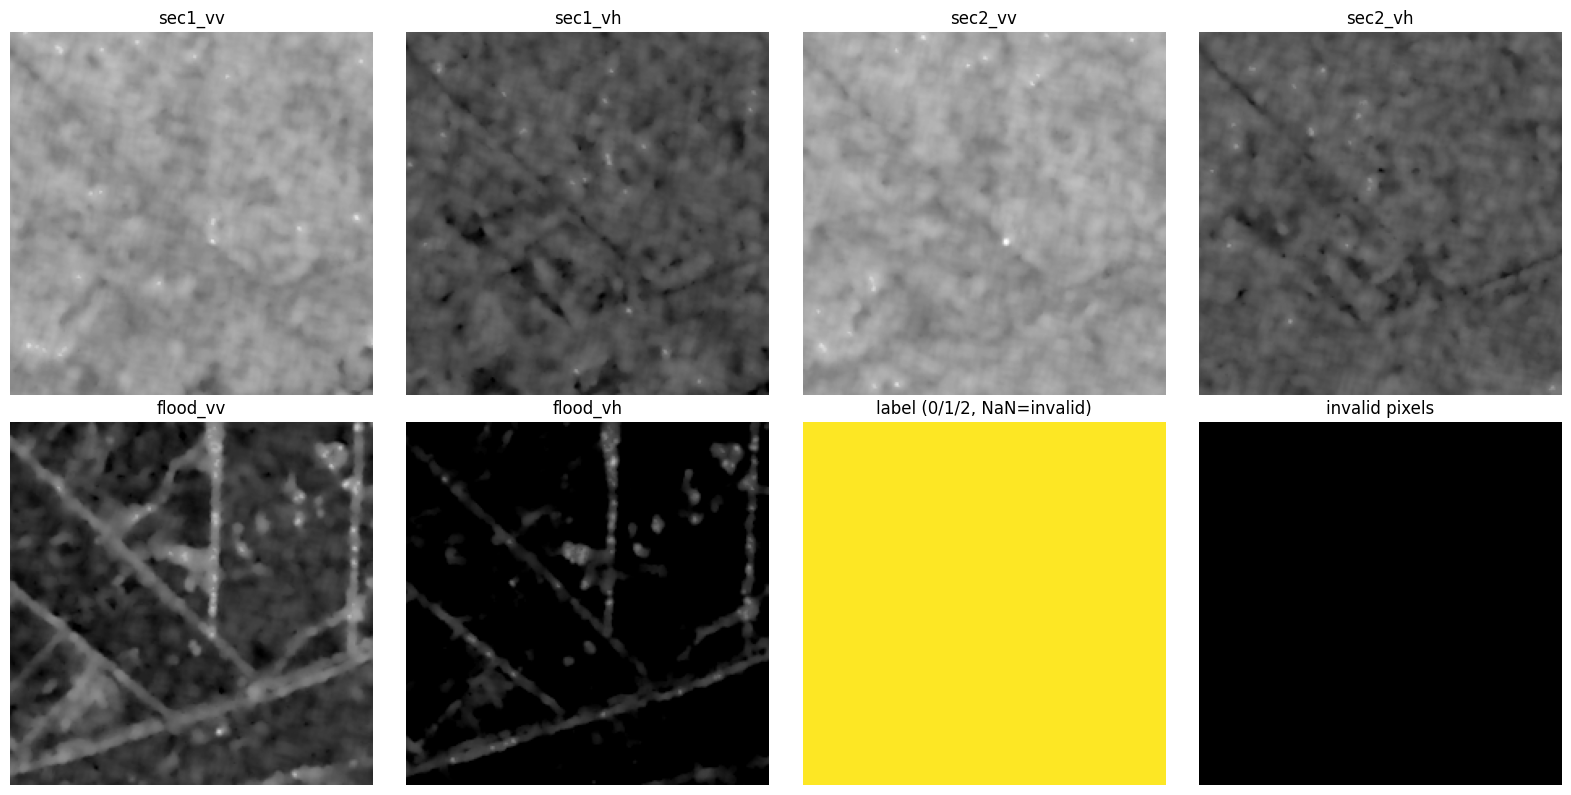

corr(stored flood %, metadata pflood): 1.0
X: (7925, 6, 224, 224) uint8 | Y: (7925, 224, 224) uint8


In [9]:
Xtr = np.load(PROC / "X_train.npy", mmap_mode="r")
Ytr = np.load(PROC / "Y_train.npy", mmap_mode="r")

s1 = np.zeros(6); s2 = np.zeros(6); lo = np.zeros(6); hi = np.zeros(6); n = 0
for a in range(0, len(Xtr), 64):
    q = np.asarray(Xtr[a:a + 64]); v = np.asarray(Ytr[a:a + 64]) != IGNORE
    qv = q.transpose(1, 0, 2, 3)[:, v].astype(np.float64)       # (6, n_valid)
    s1 += qv.sum(1); s2 += (qv ** 2).sum(1)
    lo += (qv == 0).sum(1); hi += (qv == 255).sum(1); n += qv.shape[1]

mean_q = s1 / n
std_q = np.sqrt(s2 / n - mean_q ** 2)
norm = {"channels": SAR_FIELDS, "db_min": DB_MIN, "db_max": DB_MAX,
        "mean_db": (mean_q * SCALE + DB_MIN).tolist(), "std_db": (std_q * SCALE).tolist()}
NORM_PATH = PROC / "norm_stats.json"
if NORM_PATH.exists():
    saved_norm = json.loads(NORM_PATH.read_text())
    assert saved_norm.get("channels") == SAR_FIELDS, (
        "Saved normalisation channels do not match SAR_FIELDS; do not overwrite checkpoint statistics."
    )
    assert np.isclose(saved_norm.get("db_min", np.nan), DB_MIN), (
        "Saved normalisation DB_MIN differs from the current configuration."
    )
    assert np.isclose(saved_norm.get("db_max", np.nan), DB_MAX), (
        "Saved normalisation DB_MAX differs from the current configuration."
    )
    assert np.allclose(
        np.asarray(saved_norm.get("mean_db", []), dtype=float),
        np.asarray(norm["mean_db"], dtype=float), rtol=0, atol=1e-5
    ), "Recomputed channel means differ from saved normalisation statistics; stop and inspect."
    assert np.allclose(
        np.asarray(saved_norm.get("std_db", []), dtype=float),
        np.asarray(norm["std_db"], dtype=float), rtol=0, atol=1e-5
    ), "Recomputed channel standard deviations differ from saved normalisation statistics; stop and inspect."
    norm = saved_norm
    print("Existing norm_stats.json verified and preserved; it was not overwritten.")
else:
    NORM_PATH.write_text(json.dumps(norm, indent=2))
    print("Created norm_stats.json from the current training arrays.")


display(pd.DataFrame({"mean_dB": norm["mean_db"], "std_dB": norm["std_db"],
                      "clipped_low_%": lo / n * 100, "clipped_high_%": hi / n * 100}, index=SAR_FIELDS).round(3))

import matplotlib.pyplot as plt

k = int(np.argmax(manifest[manifest.split == "train"].pflood.to_numpy()))   # a flood-heavy patch
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(6):
    ax.flat[c].imshow(Xtr[k, c] * SCALE + DB_MIN, cmap="gray", vmin=-25, vmax=0)
    ax.flat[c].set_title(SAR_FIELDS[c]); ax.flat[c].axis("off")
lab = np.asarray(Ytr[k]).astype(float); lab[lab == IGNORE] = np.nan
ax.flat[6].imshow(lab, cmap="viridis", vmin=0, vmax=2); ax.flat[6].set_title("label (0/1/2, NaN=invalid)"); ax.flat[6].axis("off")
ax.flat[7].imshow(np.asarray(Ytr[k]) == IGNORE, cmap="gray"); ax.flat[7].set_title("invalid pixels"); ax.flat[7].axis("off")
plt.tight_layout(); plt.show()

tr = manifest[manifest.split == "train"]
frac = np.array([(np.asarray(Ytr[i]) == 2).mean() * 100 for i in range(len(Ytr))])
print("corr(stored flood %, metadata pflood):", round(np.corrcoef(frac, tr.pflood.to_numpy())[0, 1], 4))
print("X:", Xtr.shape, Xtr.dtype, "| Y:", Ytr.shape, Ytr.dtype)

### 1.1 Test shards
* `test_00` (shard 0, 6,000 patches) was used **only** for exploration; its arrays were deleted afterwards to free disk (manifest kept).
* `test_01` (shard 1) and `test_02` (shard 2, eligible events 427, 437, 445 only; events 470 and 492 also occur in training/validation and are excluded) form the **fresh test**.

In [10]:
if RUN_DOWNLOADS and not (PROC / 'manifest_test_00.csv').exists():
    TEST_SHARDS = [0]

    for i in TEST_SHARDS:
        split = f"test_{i:02d}"
        if split in done:
            print(split, "already done"); continue
        p = download_shard("test_GRD", i)
        meta = extract_metadata(p, f"{i:05d}")
        meta["split"] = split; meta["row"] = np.arange(len(meta))
        Xt, Yt = open_arrays(split, len(meta))
        wanted = {r.sample_id: (split, r.row) for r in meta.itertuples()}
        preprocess_shard(p, wanted, {split: Xt}, {split: Yt})
        meta.to_csv(PROC / f"manifest_{split}.csv", index=False)
        p.unlink(); gc.collect(); mark_done(split)
        print(f"{split}: {len(meta):,} patches, {meta.actid.nunique()} events")

    test_events = set()
    for f in PROC.glob("manifest_test_*.csv"):
        test_events |= set(pd.read_csv(f)["actid"].unique())
    print("Test events:", sorted(test_events))
    print("Overlap with train/val events:", sorted(test_events & set(df2.actid.unique())) or "none")
else:
    print('skipped: switch is off or output already exists')

skipped: switch is off or output already exists


In [11]:
if RUN_DOWNLOADS:

    FRESH_SHARDS = [1]
    for i in FRESH_SHARDS:
        split = f"test_{i:02d}"
        done = set(json.loads((PROC / "done.json").read_text())) if (PROC / "done.json").exists() else set()
        if split in done:
            print(split, "already done"); continue
        p = download_shard("test_GRD", i)
        meta = extract_metadata(p, f"{i:05d}")
        meta["split"] = split; meta["row"] = np.arange(len(meta))
        Xt, Yt = open_arrays(split, len(meta))
        preprocess_shard(p, {r.sample_id: (split, r.row) for r in meta.itertuples()}, {split: Xt}, {split: Yt})
        meta.to_csv(PROC / f"manifest_{split}.csv", index=False)
        p.unlink(); gc.collect(); mark_done(split)
        print(f"{split}: {len(meta):,} patches, {meta.actid.nunique()} events")

else:
    print('skipped: switch is off or output already exists')

skipped: switch is off or output already exists


In [12]:
if RUN_DOWNLOADS and not (PROC / 'manifest_test_02_eligible.csv').exists():
    # Cell 6: Extract test shard 2 metadata directly from Hugging Face

    import requests
    import tarfile
    import json
    import time
    from pathlib import Path

    SHARD_ID = 2
    SHARD_NAME = f"{SHARD_ID:05d}"

    STREAM_URL = (
        "https://huggingface.co/datasets/"
        "orion-ai-lab/Kuro-Siwo-Webdataset/"
        f"resolve/main/test_GRD/shard-{SHARD_NAME}.tar"
    )

    def extract_metadata_stream(url, shard):
        rows = []
        start = time.time()

        response = requests.get(
            url,
            stream=True,
            allow_redirects=True,
            timeout=(30, 300)
        )
        response.raise_for_status()

        print("Connected to remote shard.")
        print("Archive size:", round(
            int(response.headers.get("Content-Length", 0)) / 1e9, 2
        ), "GB")

        try:
            with tarfile.open(fileobj=response.raw, mode="r|*") as tar:
                for member in tar:
                    if not member.isfile() or not member.name.endswith(".info.json"):
                        continue

                    info_file = tar.extractfile(member)
                    if info_file is None:
                        continue

                    info = json.loads(info_file.read())

                    row = {
                        "sample_id": Path(member.name).name.split(".")[0],
                        "shard": shard
                    }

                    row.update({
                        k: v for k, v in info.items()
                        if isinstance(v, (int, float, str, bool, type(None)))
                    })

                    sources = info.get("sources", {})
                    row["sl1_date"] = sources.get("SL1", {}).get("source_date")
                    row["sl2_date"] = sources.get("SL2", {}).get("source_date")
                    row["post_date"] = sources.get("MS1", {}).get("source_date")

                    rows.append(row)

                    if len(rows) % 500 == 0:
                        print(f"Metadata extracted: {len(rows):,} samples")

        finally:
            response.close()

        print(f"\nCompleted in {(time.time() - start) / 60:.1f} minutes.")

        return pd.DataFrame(rows)


    df_test02 = extract_metadata_stream(STREAM_URL, SHARD_NAME)

    assert len(df_test02) > 0, "No metadata extracted!"
    assert df_test02["sample_id"].is_unique, "Duplicate sample IDs detected!"

    # Identify event overlap
    trainval_events = set(
        pd.read_csv(PROC / "manifest_trainval.csv")["actid"]
    )

    test0_events = set(
        pd.read_csv(PROC / "manifest_test_00.csv")["actid"]
    )

    test02_events = set(df_test02["actid"])

    overlap_trainval = test02_events & trainval_events
    overlap_test0 = test02_events & test0_events

    print("\n" + "=" * 70)
    print("TEST SHARD 2 METADATA SUMMARY")
    print("=" * 70)

    print("Samples:", len(df_test02))
    print("Events:", len(test02_events))
    print("Event IDs:", sorted(test02_events))

    print("\nOverlap with training/validation:", sorted(overlap_trainval))
    print("Overlap with exploratory test shard 0:", sorted(overlap_test0))

    print("\nEvent distribution:")
    display(
        df_test02.groupby("actid")
        .agg(
            samples=("sample_id", "count"),
            flood_date=("flood_date", "first"),
            mean_flood=("pflood", "mean"),
            zero_flood_patches=("pflood", lambda x: (x == 0).sum())
        )
        .sort_values("samples", ascending=False)
    )

    # Save metadata only; do not mark the shard as processed.
    manifest_path = PROC / "manifest_test_02.csv"
    df_test02.to_csv(manifest_path, index=False)

    print("\nMetadata saved:", manifest_path)
    print("Processed-array completion marker has NOT been changed.")

    # Cell 7: Final event-overlap audit for test shard 2

    # Load manifests
    trainval_manifest = pd.read_csv(PROC / "manifest_trainval.csv")
    test01_manifest = pd.read_csv(PROC / "manifest_test_01.csv")

    trainval_events = set(trainval_manifest["actid"].dropna().astype(int))
    test01_events = set(test01_manifest["actid"].dropna().astype(int))

    df_test02["actid"] = df_test02["actid"].astype(int)

    test02_events = set(df_test02["actid"])

    # Identify overlaps
    overlap_trainval = test02_events & trainval_events
    overlap_test01 = test02_events & test01_events

    # Exclude only events already used in training/validation
    df_test02["eligible"] = ~df_test02["actid"].isin(trainval_events)

    df_test02["exclusion_reason"] = np.where(
        df_test02["eligible"],
        "Eligible",
        "Overlaps training/validation"
    )

    df_test02_eligible = df_test02[df_test02["eligible"]].copy()

    print("=" * 75)
    print("TEST SHARD 2: EVENT OVERLAP AUDIT")
    print("=" * 75)

    print("Events in shard 2:", sorted(test02_events))
    print("Training/validation overlap:", sorted(overlap_trainval))
    print("Shard 1 overlap:", sorted(overlap_test01))

    print("\nEligible events:", sorted(
        set(df_test02_eligible["actid"])
    ))

    print("Eligible samples:", len(df_test02_eligible))
    print("Excluded samples:", len(df_test02) - len(df_test02_eligible))

    print("\nEvent-level decision:")
    display(
        df_test02.groupby("actid")
        .agg(
            samples=("sample_id", "count"),
            eligible=("eligible", "first"),
            exclusion_reason=("exclusion_reason", "first"),
            mean_flood=("pflood", "mean"),
            zero_flood_patches=("pflood", lambda x: (x == 0).sum())
        )
        .sort_values("samples", ascending=False)
    )

    # Save the eligible manifest separately
    eligible_manifest_path = PROC / "manifest_test_02_eligible.csv"

    df_test02_eligible.to_csv(
        eligible_manifest_path,
        index=False
    )

    print("\nEligible manifest saved:", eligible_manifest_path)

    assert len(df_test02_eligible) > 0
    assert not (
        set(df_test02_eligible["actid"]) & trainval_events
    ), "Training/validation event leakage detected!"
else:
    print('skipped: switch is off or output already exists')

skipped: switch is off or output already exists


In [13]:
# the test shard 2 arrays (eligible events only) are written by the frozen-test cell in section 8 (RUN_FINAL_TEST) if they are missing
for sp in ("test_00", "test_01", "test_02"):
    f = PROC / f"manifest_{sp}.csv"
    if f.exists():
        m = pd.read_csv(f); print(f"{sp}: {len(m):,} patches, {m.actid.nunique()} events, arrays on disk: {(PROC / f'X_{sp}.npy').exists()}")

test_00: 6,000 patches, 9 events, arrays on disk: False
test_01: 6,000 patches, 8 events, arrays on disk: True
test_02: 4,839 patches, 3 events, arrays on disk: True


## 2. Core definitions (defined once, in dependency order)
Everything below only *defines* things (plus tiny cached statistics passes). The code is the final version of each function from the original notebook; where several versions existed (`make_loader_v2`, `build_model`, `load_cfg_model`, the dataset classes, `with_min_area` …) only the last one is kept, and the chained overrides are merged into one function each.

### 2.1 Constants, metrics, plain U-Net, summary helper

In [14]:
import gc, json, random, shutil, time
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
 
SEED = 42
ROOT = Path("/kaggle/working/flood_mapping_project"); DATA = ROOT / "data"; PROC = DATA / "processed"
for p in [ROOT / "checkpoints", ROOT / "results", ROOT / "logs", ROOT / "figures"]:
    p.mkdir(parents=True, exist_ok=True)
assert (PROC / "norm_stats.json").exists() and (PROC / "X_train.npy").exists(), \
    "processed data not found - /kaggle/working may have been reset; restore data/processed/ and checkpoints/ first"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DB_MIN, DB_MAX, IGNORE = -30.0, 5.0, 255
SCALE = (DB_MAX - DB_MIN) / 255.0
RECIPE = dict(lr=3e-4, epochs=12)          # recipe B (the one used for all earlier runs)
closer = [0, 1]                            # sec1 (median 36 d) is the closer pre-event image
ALL_CH = list(range(6))
 
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)

# the arrays and normalisation statistics must exist (section 1)

NORM = json.loads((PROC / "norm_stats.json").read_text())
MEAN = np.array(NORM["mean_db"], dtype=np.float32)[:, None, None]
STD  = np.array(NORM["std_db"],  dtype=np.float32)[:, None, None]

class FloodDataset(Dataset):
    def __init__(self, split, augment=False, normalize=True):
        self.split, self.augment, self.normalize = split, augment, normalize
        self.X = self.Y = None
        man = (pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
               if split in ("train", "val")
               else pd.read_csv(PROC / f"manifest_{split}.csv", dtype={"sample_id": str, "shard": str}))
        self.meta = man[man["split"] == split].sort_values("row").reset_index(drop=True)
        self.actid = self.meta["actid"].to_numpy()
    def __len__(self): return len(self.meta)
    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r"); self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = np.asarray(self.X[i]).astype(np.float32) * SCALE + DB_MIN
        if self.normalize: x = (x - MEAN) / STD
        lab = np.asarray(self.Y[i]); target = (lab == 2).astype(np.float32); valid = lab != IGNORE
        if self.augment:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))

def metrics_from_counts(tp, fp, fn, tn):
    tp, fp, fn, tn = map(float, (tp, fp, fn, tn))
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)}

def evaluate(predict_fn, loader, threshold=0.5):
    actid = loader.dataset.actid
    per_event, tot, i = {}, np.zeros(4), 0
    for x, t, v in loader:
        pred = predict_fn(x.to(DEVICE, non_blocking=True)).detach().cpu() > threshold
        t, v = t.bool(), v.bool()
        for j in range(len(x)):
            vj, pj, tj = v[j], pred[j], t[j]
            c = np.array([(pj & tj & vj).sum(), (pj & ~tj & vj).sum(), (~pj & tj & vj).sum(), (~pj & ~tj & vj).sum()], dtype=np.float64)
            per_event.setdefault(int(actid[i + j]), np.zeros(4)); per_event[int(actid[i + j])] += c; tot += c
        i += len(x)
    rows = [{"actid": e, "patches": int((actid == e).sum()), **metrics_from_counts(*c)} for e, c in sorted(per_event.items())]
    return metrics_from_counts(*tot), pd.DataFrame(rows)

class DoubleConv(nn.Sequential):
    def __init__(self, i, o):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=6, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)
    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), skips.pop()], 1))
        return self.head(x).squeeze(1)

def summarize(prefixes):
    rows = []
    for p in prefixes:
        rs = [json.loads(f.read_text()) for f in sorted((ROOT / "results").glob(f"{p}_s*.json"))]
        if not rs: continue
        row = {"experiment": p, "seeds": len(rs), "params_M": round(rs[0]["params"] / 1e6, 2),
               "best_epoch": ", ".join(str(r["best_epoch"]) for r in rs)}
        for k in ["IoU", "F1", "precision", "recall"]:
            a = np.array([r["val"][k] for r in rs]); row[k] = f"{a.mean():.3f} +/- {a.std(ddof=1) if len(a) > 1 else 0:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("experiment")

### 2.2 Input pipeline, configurations, losses, training utilities (improvement round)

In [15]:
import copy
from torch.utils.data import ConcatDataset, WeightedRandomSampler

import copy

BASE4 = list(globals().get("closer", [0, 1])) + [4, 5]          # [pre_vv, pre_vh, post_vv, post_vh]
RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))
USE_AMP = DEVICE.type == "cuda"

_common = dict(channels=BASE4, diff=False, shift_aug=False, tv_alpha=0.5, hard_neg=False, ema=False, extra=False)
_train3 = dict(shift_aug=True, tv_alpha=0.6, hard_neg=True, ema=True, extra=True)
CFGS = {
    "base":      {**_common, "ckpt": "abl_pre1_post4"},                  # existing checkpoints, 3 seeds
    "v2_inputs": {**_common, "diff": True},                              # method 2 only
    "v2_train":  {**_common, **_train3},                                 # method 3 only
    "v2_both":   {**_common, **_train3, "diff": True},                   # methods 2 + 3
}
cfg_in_ch = lambda cfg: len(cfg["channels"]) + (3 if cfg["diff"] else 0)

DIFF_JSON = PROC / "diff_stats.json"
def _db(Xarr, i, ch):
    return np.asarray(Xarr[i][ch]).astype(np.float32) * SCALE + DB_MIN
 
def diff_features(x):
    """x: (4,H,W) dB in the order pre_vv, pre_vh, post_vv, post_vh -> (3,H,W): post-pre (VV), post-pre (VH), post VV - post VH."""
    return np.stack([x[2] - x[0], x[3] - x[1], x[2] - x[3]])
 
if not DIFF_JSON.exists():
    _X = np.load(PROC / "X_train.npy", mmap_mode="r"); _Y = np.load(PROC / "Y_train.npy", mmap_mode="r")
    _idx = np.sort(np.random.default_rng(0).choice(len(_X), min(400, len(_X)), replace=False))
    _f = np.stack([diff_features(_db(_X, i, BASE4)) for i in _idx])                 # (400,3,H,W)
    _v = (np.asarray([_Y[i] for i in _idx]) != IGNORE)[:, None]
    _m = [float(_f[:, c][_v[:, 0]].mean()) for c in range(3)]; _s = [float(_f[:, c][_v[:, 0]].std()) for c in range(3)]
    DIFF_JSON.write_text(json.dumps({"mean": _m, "std": _s, "channels": BASE4})); del _X, _Y, _f, _v
DIFF = json.loads(DIFF_JSON.read_text())
DIFF_MEAN = np.array(DIFF["mean"], np.float32)[:, None, None]; DIFF_STD = np.array(DIFF["std"], np.float32)[:, None, None]

HN_W = None            # hard-negative sampling weights over [train, train_extra]; filled by mine_hard_negatives()

def masked_bce_tversky(logits, target, valid, alpha_fp=0.6, eps=1.0):
    v = valid.float()
    bce = (F.binary_cross_entropy_with_logits(logits, target, reduction="none") * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    tp = (p * target).sum(); fp = (p * (1 - target)).sum(); fn = ((1 - p) * target * v).sum()
    return bce + 1 - (tp + eps) / (tp + alpha_fp * fp + (1 - alpha_fp) * fn + eps)

class EMA:
    def __init__(self, model, decay=0.998):
        self.module, self.decay, self.n = copy.deepcopy(model).eval(), decay, 0
        for p in self.module.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, m in zip(self.module.parameters(), model.parameters()): e.mul_(d).add_(m.detach(), alpha=1 - d)
        for e, m in zip(self.module.buffers(), model.buffers()): e.copy_(m)

HN_BOOST, HN_FP_REF = 3.0, 2000      # flood-free patch weight = 1 + 3 * min(false-positive pixels / 2000, 1)

def mine_hard_negatives(base_run="abl_pre1_post4_s0"):
    out = PROC / "hard_neg_weights.npy"
    if out.exists():
        return np.load(out)
    cfg0 = CFGS["base"]; model = load_cfg_model(cfg0, base_run)
    ds = ConcatDataset([FloodDatasetV2("train", cfg0), FloodDatasetV2("train_extra", cfg0)])
    fps, fls = [], []
    with torch.no_grad():
        for x, t, v in DataLoader(ds, batch_size=32, num_workers=2):
            pred = torch.sigmoid(model(x.to(DEVICE))).cpu() > 0.5
            t, v = t.bool(), v.bool()
            fps.append((pred & ~t & v).flatten(1).sum(1)); fls.append((t & v).flatten(1).sum(1))
    fp, fl = torch.cat(fps).numpy(), torch.cat(fls).numpy()
    w = np.ones(len(fp)); empty = fl == 0
    w[empty] = 1 + HN_BOOST * np.clip(fp[empty] / HN_FP_REF, 0, 1)
    np.save(out, w); del model; gc.collect(); torch.cuda.empty_cache()
    print(f"mined {len(w)} patches: {int(empty.sum())} flood-free, {int((w > 1.5).sum())} of them hard (weight > 1.5); "
          f"flood-free share of sampling mass {w[empty].sum() / w.sum() * 100:.1f}% (uniform: {empty.mean() * 100:.1f}%)")
    return w

def train_v2(model, run, cfg, epochs, lr, batch_size=16, patience=5, weight_decay=1e-4):
    model = model.to(DEVICE)
    tr = make_loader_v2("train", cfg, batch_size, train=True); va = make_loader_v2("val", cfg, batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    ema = EMA(model) if cfg["ema"] else None
    ckpt = ROOT / "checkpoints" / f"{run}.pt"
    best, best_ep, bad, hist = -1.0, 0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                logits = model(x)
            loss = masked_bce_tversky(logits.float(), t, v, cfg["tv_alpha"])
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if ema: ema.update(model)
            run_loss += loss.item() * len(x)
        sched.step()
        ev_model = (ema.module if ema else model).eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(ev_model(x)), va)
        hist.append({"epoch": ep, "train_loss": run_loss / len(tr.dataset), **{f"val_{k}": val for k, val in pooled.items()}})
        print(f"[{run}] ep {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, best_ep, bad = pooled["IoU"], ep, 0
            torch.save(ev_model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    del tr, va; gc.collect()
    return model.eval(), {"best_val_iou": best, "best_epoch": best_ep, "epochs_run": len(hist)}

def run_v2(name, seeds, epochs=None, lr=None):
    """Train one model per seed (finished runs are skipped). Results: results/<name>_s<seed>.json (same schema as run_experiment)."""
    cfg = CFGS[name]; epochs = epochs or RECIPE["epochs"]; lr = lr or RECIPE["lr"]
    for s in seeds:
        run = f"{name}_s{s}"; out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model, info = train_v2(UNet(in_ch=cfg_in_ch(cfg), base=32), run, cfg, epochs, lr)
        pooled, per_event = evaluate(lambda x: torch.sigmoid(model(x)), make_loader_v2("val", cfg))
        out.write_text(json.dumps({"run": run, "cfg": cfg, "epochs": epochs, "lr": lr,
                                   "params": sum(p.numel() for p in model.parameters()), **info,
                                   "val": pooled, "val_per_event": per_event.to_dict("records")},
                                  default=lambda o: o.item() if hasattr(o, "item") else str(o)))
        del model; gc.collect(); torch.cuda.empty_cache()

### 2.3 Multi-temporal models: gated, gap-aware fusion (`mt_g*`) and the first-round `mt_diff` / `mt_attn`

In [16]:
import math

def gap_days(meta):
    d = lambda c: pd.to_datetime(meta[c], errors="coerce", utc=True)
    g = np.stack([(d("post_date") - d("sl1_date")).dt.days.to_numpy(dtype=float),
                  (d("post_date") - d("sl2_date")).dt.days.to_numpy(dtype=float)], 1)
    med = np.nanmedian(g, 0)
    return np.clip(np.where(np.isnan(g), med, g), 1, None)

GAP_JSON = PROC / "gap_stats.json"
if not GAP_JSON.exists():
    _m = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str}); _m = _m[_m.split == "train"]
    _l = np.log1p(gap_days(_m)); GAP_JSON.write_text(json.dumps({"mean": _l.mean(0).tolist(), "std": _l.std(0).tolist()}))
GAPS = json.loads(GAP_JSON.read_text()); GAP_MU, GAP_SD = np.array(GAPS["mean"], np.float32), np.array(GAPS["std"], np.float32)

def _norm(kind, c):
    return nn.BatchNorm2d(c) if kind == "bn" else nn.GroupNorm(6, c)          # 30, 60, 120, 240, 480 are divisible by 6

class DoubleConvN(nn.Sequential):
    def __init__(self, i, o, norm="bn"):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), _norm(norm, o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), _norm(norm, o), nn.ReLU(inplace=True))

class GatedFusion(nn.Module):
    def __init__(self, c, gap_aware, norm):
        super().__init__()
        h = max(c // 2, 8)
        self.q, self.k = nn.Conv2d(c, h, 1), nn.Conv2d(c, h, 1)
        self.bias = nn.Parameter(torch.tensor(-3.0))                     # gate starts near 0: trust pre1
        self.gap = nn.Linear(2, 1) if gap_aware else None
        if self.gap is not None:
            nn.init.zeros_(self.gap.weight); nn.init.zeros_(self.gap.bias)
        self.mix = nn.Sequential(nn.Conv2d(3 * c, c, 1, bias=False), _norm(norm, c), nn.ReLU(inplace=True))
        self.last_g = None
    def forward(self, f, gap=None, drop=None):          # f (B,3,C,H,W): pre1, pre2, post; drop (B,) 0 none / 1 drop pre1 / 2 drop pre2
        pre1, pre2, post = f[:, 0], f[:, 1], f[:, 2]
        q = self.q(post); sc = math.sqrt(q.shape[1])
        s1, s2 = (self.k(pre1) * q).sum(1, keepdim=True) / sc, (self.k(pre2) * q).sum(1, keepdim=True) / sc
        l = self.bias + (s2 - s1)
        if self.gap is not None:
            l = l + self.gap(gap.to(l.dtype))[:, :, None, None]
        if drop is not None:
            l = torch.where((drop == 2)[:, None, None, None], torch.full_like(l, -20.0), l)
            l = torch.where((drop == 1)[:, None, None, None], torch.full_like(l, 20.0), l)
        g = torch.sigmoid(l)
        self.last_g = g.mean((1, 2, 3)).detach().float()
        ref = pre1 + g * (pre2 - pre1)
        return self.mix(torch.cat([post, post - ref, ref], 1))

class MTGateUNet(nn.Module):
    def __init__(self, base=30, gap_aware=False, pdrop=0.0, bott_drop=0.1, norm="bn"):
        super().__init__()
        self.gap_aware, self.pdrop = gap_aware, pdrop
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc  = nn.ModuleList([DoubleConvN(2, c[0], norm)] + [DoubleConvN(c[i], c[i + 1], norm) for i in range(4)])
        self.fuse = nn.ModuleList([GatedFusion(ch, gap_aware, norm) for ch in c])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.dec  = nn.ModuleList([DoubleConvN(c[i] * 2, c[i], norm) for i in range(4)])
        self.bdrop = nn.Dropout2d(bott_drop)
        self.head = nn.Conv2d(c[0], 1, 1)
    def forward(self, x):                                  # x: (B,6[+2],H,W)
        B, _, H, W = x.shape
        gap = x[:, 6:8, 0, 0] if self.gap_aware else None
        h = x[:, :6].reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)
        drop = None
        if self.training and self.pdrop > 0:
            r = torch.rand(B, device=x.device); drop = torch.zeros(B, dtype=torch.long, device=x.device)
            drop[r < self.pdrop / 2] = 1; drop[(r >= self.pdrop / 2) & (r < self.pdrop)] = 2
        feats = []
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:]), gap, drop))
        x = self.bdrop(feats.pop())
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), feats.pop()], 1))
        return self.head(x).squeeze(1)

# first multi-temporal round (shared encoder; difference fusion / temporal attention)

import math

class AttentionGate(nn.Module):
    """Additive attention gate on a skip connection (Oktay et al., Attention U-Net)."""
    def __init__(self, g_ch, x_ch, inter):
        super().__init__()
        self.wg  = nn.Sequential(nn.Conv2d(g_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.wx  = nn.Sequential(nn.Conv2d(x_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.psi = nn.Sequential(nn.Conv2d(inter, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x):                                   # g: upsampled decoder features, x: skip features
        return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class TemporalFusion(nn.Module):
    """Fuse per-timestep features f (B,3,C,H,W; order pre1, pre2, post) into one map.
       attention=False: reference = mean of the two pre-event features.
       attention=True : reference = per-pixel softmax-weighted mix of the pre-event features, the weights
                        coming from similarity to the post-event features (the model chooses which pre-event image to trust)."""
    def __init__(self, c, attention):
        super().__init__()
        self.attention = attention
        if attention:
            self.q = nn.Conv2d(c, max(c // 2, 8), 1); self.k = nn.Conv2d(c, max(c // 2, 8), 1)
        self.mix = nn.Sequential(nn.Conv2d(3 * c, c, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True))
    def forward(self, f):
        pre, post = f[:, :2], f[:, 2]
        if self.attention:
            q = self.q(post)
            k = torch.stack([self.k(pre[:, i]) for i in range(2)], 1)
            w = torch.softmax((k * q[:, None]).sum(2, keepdim=True) / math.sqrt(q.shape[1]), dim=1)
            ref = (w * pre).sum(1)
        else:
            ref = pre.mean(1)
        return self.mix(torch.cat([post, post - ref, ref], 1))      # post, change, reference

class MTUNet(nn.Module):
    """Multi-temporal U-Net: ONE encoder shared by the 3 timesteps (2 channels each), temporal fusion at every scale,
       U-Net decoder (with attention gates on the skips if attention=True). Input: (B,6,H,W) in the usual channel order."""
    def __init__(self, base=32, attention=True):
        super().__init__()
        self.attention = attention
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc  = nn.ModuleList([DoubleConv(2, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.fuse = nn.ModuleList([TemporalFusion(ch, attention) for ch in c])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.gate = nn.ModuleList([AttentionGate(c[i], c[i], max(c[i] // 2, 8)) for i in range(4)]) if attention else None
        self.dec  = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        B, _, H, W = x.shape
        h = x.reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)         # (pre1, pre2, post) x (VV, VH)
        feats = []
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:])))
        x = feats.pop()
        for i in reversed(range(4)):
            u, s = self.up[i](x), feats.pop()
            if self.attention:
                s = self.gate[i](u, s)
            x = self.dec[i](torch.cat([u, s], 1))
        return self.head(x).squeeze(1)

MT_BASE = 30                          # ~7.8 M parameters for mt_diff, i.e. the same size as the plain U-Net

_mt = dict(arch="mt", channels=list(range(6)), diff=False, shift_aug=False, tv_alpha=0.5, hard_neg=False, extra=False,
           ema=True, lr=1e-4, wd=1e-2, epochs=14, patience=6, base=30, gap=False, pdrop=0.0, norm="bn")
CFGS.update({
    "mt_g0": {**_mt},                                                      # gated fusion + stabilised recipe
    "mt_g1": {**_mt, "gap": True},                                         # + gap-aware gate
    "mt_g2": {**_mt, "gap": True, "pdrop": 0.3},                           # + temporal dropout
    "mt_g3": {**_mt, "gap": True, "pdrop": 0.3, "norm": "gn"},             # + GroupNorm
})

def run_mt(name, seeds):
    """Train one multi-temporal model per seed (finished runs skipped); results/<name>_s<seed>.json (same schema as run_v2)."""
    cfg = CFGS[name]
    for s in seeds:
        run = f"{name}_s{s}"; out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model, info = train_v2(build_model(cfg), run, cfg, cfg["epochs"], cfg["lr"], weight_decay=cfg["wd"], patience=cfg["patience"])
        pooled, per_event = evaluate(lambda x: torch.sigmoid(model(x)), make_loader_v2("val", cfg))
        out.write_text(json.dumps({"run": run, "cfg": cfg, "epochs": cfg["epochs"], "lr": cfg["lr"],
                                   "params": sum(p.numel() for p in model.parameters()), **info,
                                   "val": pooled, "val_per_event": per_event.to_dict("records")},
                                  default=lambda o: o.item() if hasattr(o, "item") else str(o)))
        del model; gc.collect(); torch.cuda.empty_cache()

@torch.no_grad()
def gate_report(name, seed=0, split="val"):
    cfg = CFGS[name]; m = load_cfg_model(cfg, f"{name}_s{seed}"); loader = make_loader_v2(split, cfg)
    G = []
    for x, t, v in loader:
        m(x.to(DEVICE)); G.append(torch.stack([f.last_g for f in m.fuse], 1).cpu())
    G = torch.cat(G).numpy(); gd = gap_days(loader.dataset.meta)
    df_ = pd.DataFrame(G, columns=[f"gate_scale{i}" for i in range(5)]); df_["gap_pre1_d"] = gd[:, 0]; df_["gap_pre2_d"] = gd[:, 1]
    df_["pre1_gap_bin"] = pd.cut(df_.gap_pre1_d, [0, 30, 60, 100, 100000])
    print(f"{name}_s{seed}: mean gate g (0 = only pre1, 1 = only pre2) per scale, fine -> coarse:", G.mean(0).round(3))
    display(df_.groupby("pre1_gap_bin", observed=True)[[f"gate_scale{i}" for i in (0, 2, 4)]].mean().round(3))
    del m; gc.collect(); torch.cuda.empty_cache()

def iou_by_gap(name, seeds=(0,), split="val", n_tta=1):
    """IoU by days from the closer pre-event image to the post image (long gaps resemble the test set)."""
    cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
    ms = [load_cfg_model(cfg, f"{prefix}_s{s}") for s in seeds]; loader = make_loader_v2(split, cfg)
    d = predict_stats_fn(prob_fn(ms, n_tta), loader); d["gap"] = gap_days(loader.dataset.meta)[:, 0]
    d["bin"] = pd.cut(d.gap, [0, 30, 60, 100000]); out = {}
    for b, g in d.groupby("bin", observed=True):
        out[str(b)] = metrics_from_counts(g.tp.sum(), g.fp.sum(), g.fn.sum(), 0)["IoU"]; out[f"n[{b}]"] = len(g)
    del ms; gc.collect(); torch.cuda.empty_cache()
    return pd.Series(out, name=name)

### 2.4 DEM utilities and DEM models

In [17]:
import io, tarfile, hashlib, datetime
from huggingface_hub import HfApi, hf_hub_download
from torch.utils.data import ConcatDataset, WeightedRandomSampler

REPO = "orion-ai-lab/Kuro-Siwo-Webdataset"
TAR_DIR = DATA / "kuro_siwo"; TAR_DIR.mkdir(parents=True, exist_ok=True)
SAR_FIELDS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh"]
DEM_PIXEL_M = 10.0

def encode_sar(x):                       # (6,H,W) linear -> uint8 dB (same as the original preprocessing)
    db = 10.0 * np.log10(np.clip(np.nan_to_num(x, nan=1e-4), 1e-4, None))
    return np.rint(np.clip((db - DB_MIN) / (DB_MAX - DB_MIN), 0, 1) * 255).astype(np.uint8)

def encode_label(mask, valid):
    lab = mask.astype(np.uint8); lab[valid <= 0] = IGNORE
    return lab

def open_arrays(split, n):
    out = []
    for name, shape in [("X", (n, 6, 224, 224)), ("Y", (n, 224, 224))]:
        f = PROC / f"{name}_{split}.npy"
        out.append(np.load(f, mmap_mode="r+") if f.exists() else np.lib.format.open_memmap(f, mode="w+", dtype=np.uint8, shape=shape))
    return out

def open_D(split, n):
    f = PROC / f"D_{split}.npy"
    return np.load(f, mmap_mode="r+") if f.exists() else np.lib.format.open_memmap(f, mode="w+", dtype=np.float16, shape=(n, 2, 224, 224))

def dem_features(dem):
    d = np.asarray(dem, dtype=np.float32)
    bad = ~np.isfinite(d) | (d < -1000)                      # nodata guard
    out = np.zeros((2,) + d.shape, np.float32)
    if bad.all():
        return out.astype(np.float16)
    med = float(np.median(d[~bad])); d = np.where(bad, med, d)
    gy, gx = np.gradient(d, DEM_PIXEL_M)
    out[0] = d - med
    out[1] = np.degrees(np.arctan(np.hypot(gx, gy)))
    return out.astype(np.float16)

def stream_shard(tar_path, wanted, X=None, Y=None, D=None):
    """One pass over a shard. wanted: {sample_id: (split, row)}. Writes SAR+labels if X, Y are given, DEM features if D is given."""
    need = set()
    if X is not None: need |= set(SAR_FIELDS) | {"mask", "valid_mask"}
    if D is not None: need |= {"dem"}
    buf, written = {}, 0
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if not m.isfile():
                continue
            key, _, field = Path(m.name).name.partition(".")
            if key not in wanted or not field.endswith(".npy") or field[:-4] not in need:
                continue
            buf.setdefault(key, {})[field[:-4]] = np.load(io.BytesIO(tar.extractfile(m).read()), allow_pickle=False).squeeze()
            if len(buf[key]) == len(need):
                s = buf.pop(key); split, row = wanted[key]
                if X is not None:
                    X[split][row] = encode_sar(np.stack([s[f] for f in SAR_FIELDS])); Y[split][row] = encode_label(s["mask"], s["valid_mask"])
                if D is not None:
                    D[split][row] = dem_features(s["dem"])
                written += 1
    assert written == len(wanted) and not buf, f"wrote {written}/{len(wanted)}; incomplete: {len(buf)}"
    for a in list(X.values() if X else []) + list(Y.values() if Y else []) + list(D.values() if D else []):
        getattr(a, "flush", lambda: None)()
    return written

class MTGateUNetDEM(MTGateUNet):
    """MTGateUNet plus a light DEM encoder. Its features are added (through 1x1 convs initialised to ZERO, so training starts
       exactly as mt_g2) to the fused features at every scale. DEM channels are the last two input channels."""
    def __init__(self, base=30, gap_aware=False, pdrop=0.0, bott_drop=0.1, norm="bn"):
        super().__init__(base, gap_aware, pdrop, bott_drop, norm)
        c = [base, base * 2, base * 4, base * 8, base * 16]; w = [8, 16, 32, 64, 128]
        self.denc = nn.ModuleList([DoubleConvN(2, w[0], norm)] + [DoubleConvN(w[i], w[i + 1], norm) for i in range(4)])
        self.dproj = nn.ModuleList([nn.Conv2d(w[i], c[i], 1) for i in range(5)])
        for p in self.dproj:
            nn.init.zeros_(p.weight); nn.init.zeros_(p.bias)
    def forward(self, x):
        B, _, H, W = x.shape
        gap = x[:, 6:8, 0, 0] if self.gap_aware else None
        dem = x[:, -2:]
        h = x[:, :6].reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)
        drop = None
        if self.training and self.pdrop > 0:
            r = torch.rand(B, device=x.device); drop = torch.zeros(B, dtype=torch.long, device=x.device)
            drop[r < self.pdrop / 2] = 1; drop[(r >= self.pdrop / 2) & (r < self.pdrop)] = 2
        feats, hd = [], dem
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            hd = self.denc[i](hd if i == 0 else F.max_pool2d(hd, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:]), gap, drop) + self.dproj[i](hd))
        x = self.bdrop(feats.pop())
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), feats.pop()], 1))
        return self.head(x).squeeze(1)

### 2.5 Dataset classes (final versions; one definition each, parents before children)

In [18]:
class FloodDatasetV2(FloodDataset):
    """Selected SAR channels + optional change channels."""

    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug, self.ch = cfg, augment, list(cfg["channels"])
        self.mean, self.std = MEAN[self.ch], STD[self.ch]

    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")

        x = _db(self.X, i, self.ch)
        lab = np.asarray(self.Y[i])
        target = (lab == 2).astype(np.float32)
        valid = lab != IGNORE

        if self.aug and self.cfg["shift_aug"]:
            x = x + random.gauss(0, 1.0)
            x[:2] += random.gauss(0, 0.5)
            x[2:] += random.gauss(0, 0.5)
            x = x + np.random.standard_normal(x.shape).astype(np.float32) * 0.5
            x = np.clip(x, DB_MIN, DB_MAX)

        feats = (x - self.mean) / self.std

        if self.cfg["diff"]:
            feats = np.concatenate([
                feats,
                (diff_features(x) - DIFF_MEAN) / DIFF_STD
            ])

        x = feats.astype(np.float32)

        if self.aug:
            if random.random() < 0.5:
                x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5:
                x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k:
                x, target, valid = (
                    np.rot90(x, k, (1, 2)),
                    np.rot90(target, k),
                    np.rot90(valid, k)
                )

        return (
            torch.from_numpy(np.ascontiguousarray(x)),
            torch.from_numpy(np.ascontiguousarray(target)),
            torch.from_numpy(np.ascontiguousarray(valid))
        )

class FloodDatasetMT(FloodDatasetV2):
    """SAR channels + standardized temporal gap planes."""

    def __init__(self, split, cfg, augment=False):
        super().__init__(split, cfg, augment)
        self.gf = (
            (np.log1p(gap_days(self.meta)) - GAP_MU) / GAP_SD
        ).astype(np.float32)

    def __getitem__(self, i):
        x, t, v = super().__getitem__(i)
        g = torch.from_numpy(self.gf[i]).view(2, 1, 1)
        g = g.expand(2, *x.shape[1:])
        return torch.cat([x, g]), t, v

class FloodDatasetD(FloodDataset):
    """SAR + optional temporal gaps + DEM channels."""

    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug = cfg, augment
        self.ch = list(cfg["channels"])
        self.D = None
        self.mean, self.std = MEAN[self.ch], STD[self.ch]

        s = json.loads((PROC / "dem_stats.json").read_text())
        self.rel_sd = s["rel_sd"]
        self.sl_mu = s["slope_log_mean"]
        self.sl_sd = s["slope_log_std"]

        self.gf = (
            ((np.log1p(gap_days(self.meta)) - GAP_MU) / GAP_SD).astype(np.float32)
            if cfg.get("gap") else None
        )

    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")

        if self.D is None:
            self.D = np.load(PROC / f"D_{self.split}.npy", mmap_mode="r")

        x = (_db(self.X, i, self.ch) - self.mean) / self.std
        H, W = x.shape[1:]
        parts = [x]

        if self.gf is not None:
            parts.append(np.broadcast_to(self.gf[i][:, None, None], (2, H, W)))

        d = np.asarray(self.D[i]).astype(np.float32)

        parts.append(np.stack([
            np.clip(d[0] / self.rel_sd, -3, 3),
            (np.log1p(np.clip(d[1], 0, None)) - self.sl_mu) / self.sl_sd
        ]))

        x = np.concatenate(parts).astype(np.float32)

        lab = np.asarray(self.Y[i])
        target = (lab == 2).astype(np.float32)
        valid = lab != IGNORE

        if self.aug:
            if random.random() < 0.5:
                x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5:
                x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k:
                x, target, valid = (
                    np.rot90(x, k, (1, 2)),
                    np.rot90(target, k),
                    np.rot90(valid, k)
                )

        return (
            torch.from_numpy(np.ascontiguousarray(x)),
            torch.from_numpy(np.ascontiguousarray(target)),
            torch.from_numpy(np.ascontiguousarray(valid))
        )

### 2.6 Despeckling filters (Lee, median), tiling for large scenes, and the new baseline architectures

In [19]:
from scipy.ndimage import uniform_filter, median_filter
import matplotlib.pyplot as plt

ENL = 4.4

def lee_filter(db, win=5):
    """db: (C,H,W) dB -> Lee-filtered dB. Filtering is done in linear intensity."""
    lin = np.power(10.0, db / 10.0).astype(np.float32); out = np.empty_like(lin); cu2 = 1.0 / ENL
    for c in range(lin.shape[0]):
        x = lin[c]
        m = uniform_filter(x, win, mode="reflect"); m2 = uniform_filter(x * x, win, mode="reflect")
        ci2 = np.maximum(m2 - m * m, 0) / np.maximum(m * m, 1e-12)            # local coefficient of variation squared
        w = np.clip(1 - cu2 / np.maximum(ci2, 1e-12), 0, 1)                   # w = 0 in homogeneous areas, 1 on edges / targets
        out[c] = m + w * (x - m)
    return np.clip(10 * np.log10(np.maximum(out, 1e-4)), DB_MIN, DB_MAX).astype(np.float32)

def median_db(db, win=3):
    return np.stack([median_filter(c, size=win, mode="reflect") for c in db]).astype(np.float32)

FILTERS = {"lee5": lambda d: lee_filter(d, 5), "med3": lambda d: median_db(d, 3)}

class FloodDatasetF(FloodDataset):
    """SAR channels (dB) -> despeckle filter -> standardize with the ORIGINAL training statistics -> flips / rotations."""
    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug, self.ch = cfg, augment, list(cfg["channels"])
        self.mean, self.std = MEAN[self.ch], STD[self.ch]
    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r"); self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = ((FILTERS[self.cfg["despeckle"]](_db(self.X, i, self.ch)) - self.mean) / self.std).astype(np.float32)
        lab = np.asarray(self.Y[i]); target = (lab == 2).astype(np.float32); valid = lab != IGNORE
        if self.aug:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))

def scene_to_input(sar6, channels=(0, 1, 4, 5)):
    db = encode_sar(np.asarray(sar6, np.float32)).astype(np.float32) * SCALE + DB_MIN          # same quantisation as the stored arrays
    ch = list(channels)
    return ((db[ch] - MEAN[ch]) / STD[ch]).astype(np.float32)

def _hann2d(t):
    w = np.hanning(t + 2)[1:-1].astype(np.float32); return np.outer(w, w) + 1e-3

@torch.no_grad()
def predict_scene(models, x, tile=224, overlap=32, batch=8):
    """x: (C,H,W) normalised input of any size >= 1 pixel; returns the (H,W) probability map."""
    C, H, W = x.shape; step = tile - overlap
    grow = lambda n: tile if n <= tile else tile + -(-(n - tile) // step) * step          # padded size: tile + k * step
    Hp, Wp = grow(H), grow(W); ph, pw_ = Hp - H, Wp - W
    xp = np.pad(x, ((0, 0), (0, ph), (0, pw_)), mode="reflect" if max(ph, pw_) < min(H, W) else "edge") if (ph or pw_) else x
    ys = list(range(0, Hp - tile + 1, step)); xs = list(range(0, Wp - tile + 1, step))
    acc, wsum = np.zeros((Hp, Wp), np.float32), np.zeros((Hp, Wp), np.float32); win = _hann2d(tile) if overlap > 0 else np.ones((tile, tile), np.float32)
    coords = [(y, x_) for y in ys for x_ in xs]
    for i in range(0, len(coords), batch):
        cs = coords[i:i + batch]
        xb = torch.from_numpy(np.stack([xp[:, y:y + tile, x_:x_ + tile] for y, x_ in cs])).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            pb = torch.stack([torch.sigmoid(m(xb).float()) for m in models]).mean(0).cpu().numpy()
        for (y, x_), p in zip(cs, pb):
            acc[y:y + tile, x_:x_ + tile] += p * win; wsum[y:y + tile, x_:x_ + tile] += win
    return (acc / wsum)[:H, :W]

In [20]:
import timm
from transformers import SegformerForSemanticSegmentation, SegformerConfig

class UNetResNet50(nn.Module):
    def __init__(self, in_ch=4, name="resnet50", pretrained=True, dec=(32, 64, 128, 256, 512)):
        super().__init__()
        self.enc = timm.create_model(name, pretrained=pretrained, features_only=True, in_chans=in_ch, out_indices=(0, 1, 2, 3, 4))
        ch = self.enc.feature_info.channels()                                            # [64, 256, 512, 1024, 2048], strides 2..32
        self.lat = nn.ModuleList([nn.Conv2d(c, d, 1) for c, d in zip(ch, dec)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(dec[i + 1], dec[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(dec[i] * 2, dec[i]) for i in range(4)])
        self.last = nn.ConvTranspose2d(dec[0], 16, 2, stride=2); self.head = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        f = [l(t) for l, t in zip(self.lat, self.enc(x))]
        h = f[4]
        for i in (3, 2, 1, 0):
            u = self.up[i](h)
            if u.shape[-2:] != f[i].shape[-2:]: u = F.interpolate(u, size=f[i].shape[-2:], mode="bilinear", align_corners=False)
            h = self.dec[i](torch.cat([u, f[i]], 1))
        return self.head(F.relu(self.last(h))).squeeze(1)

class SegFormerWrap(nn.Module):
    def __init__(self, in_ch=4, name="nvidia/mit-b2", pretrained=True):
        super().__init__()
        if pretrained:
            m = SegformerForSemanticSegmentation.from_pretrained(name, num_labels=1, ignore_mismatched_sizes=True)
        else:
            m = SegformerForSemanticSegmentation(SegformerConfig(num_labels=1))
        for nm, mod in m.named_modules():                                              # first conv that reads the 3 RGB channels (robust to library versions)
            if isinstance(mod, nn.Conv2d) and mod.in_channels == 3: break
        w = mod.weight.data; new = nn.Conv2d(in_ch, mod.out_channels, mod.kernel_size, mod.stride, mod.padding)
        new.weight.data = torch.cat([w[:, :3], w.mean(1, keepdim=True).repeat(1, in_ch - 3, 1, 1)], 1) if in_ch > 3 else w[:, :in_ch].clone()
        new.bias.data = mod.bias.data.clone(); parent = m.get_submodule(nm.rsplit(".", 1)[0]); setattr(parent, nm.rsplit(".", 1)[1], new)
        if hasattr(m.config, "num_channels"): m.config.num_channels = in_ch
        self.m = m
    def forward(self, x):
        return F.interpolate(self.m(pixel_values=x).logits, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)

PRETRAINED = True                      # False only for offline smoke tests

### 2.7 Configurations registry and factories (merged `CFGS`, `cfg_in_ch`, `build_model`, `load_cfg_model`, `make_loader_v2`)

In [21]:
_d = {k: v for k, v in CFGS["base"].items() if k != "ckpt"}
CFGS["dem_unet"]  = {**_d, "dem": True}                                          # same recipe B as base
CFGS["mt_g2_dem"] = {**CFGS["mt_g2"], "dem": True, "arch": "mtd"}              # same recipe as mt_g2
CFGS.setdefault("abl_post2",        {**_d, "channels": [4, 5]})                  # original configurations, for the fresh test only
CFGS.setdefault("abl_all6",         {**_d, "channels": list(range(6))})
CFGS.setdefault("extra_pre1_post4", {**CFGS["base"], "ckpt": "extra_pre1_post4"})
if "MTUNet" in globals():                                                        # mt_diff / mt_attn from the first multi-temporal round
    CFGS.setdefault("mt_diff", {**_d, "channels": list(range(6)), "arch": "old_mt", "attn": False})
    CFGS.setdefault("mt_attn", {**_d, "channels": list(range(6)), "arch": "old_mt", "attn": True})

_b = {k: v for k, v in CFGS["base"].items() if k != "ckpt"}
CFGS["base_lee5"] = {**_b, "despeckle": "lee5"}              # despeckling ablation
CFGS["base_med3"] = {**_b, "despeckle": "med3"}
CFGS["unet_r50"] = {**_b, "arch": "r50u"}                    # pretrained baselines (4 channels: pre1 + post)
CFGS["segformer_b2"] = {**_b, "arch": "segf"}
BASELINE_LR = {"unet_r50": 2e-4, "segformer_b2": 6e-5}      # fixed in advance, not tuned

cfg_in_ch = lambda cfg: len(cfg["channels"]) + (3 if cfg["diff"] else 0) + (2 if cfg.get("gap") else 0) + (2 if cfg.get("dem") else 0)

def build_model(cfg):
    a = cfg.get("arch")
    if a == "mt":      return MTGateUNet(cfg["base"], cfg["gap"], cfg["pdrop"], norm=cfg["norm"])
    if a == "mtd":     return MTGateUNetDEM(cfg["base"], cfg["gap"], cfg["pdrop"], norm=cfg["norm"])
    if a == "old_mt":  return MTUNet(30, cfg["attn"])
    if a == "r50u":    return UNetResNet50(len(cfg["channels"]), pretrained=PRETRAINED)
    if a == "segf":    return SegFormerWrap(len(cfg["channels"]), pretrained=PRETRAINED)
    return UNet(in_ch=cfg_in_ch(cfg), base=32)

def load_cfg_model(cfg, run):
    m = build_model(cfg); m.load_state_dict(torch.load(ROOT / "checkpoints" / f"{run}.pt", map_location=DEVICE))
    return m.to(DEVICE).eval()

def make_loader_v2(split, cfg, batch_size=16, train=False, workers=2):
    if cfg.get("despeckle"):                                 # speckle-filter ablation (validation only)
        ds = FloodDatasetF("train" if train else split, cfg, augment=train)
        return DataLoader(ds, batch_size=batch_size, shuffle=train, num_workers=workers, pin_memory=USE_AMP, persistent_workers=workers > 0)
    cls = FloodDatasetD if cfg.get("dem") else (FloodDatasetMT if cfg.get("gap") else FloodDatasetV2)
    if train:
        parts = [cls("train", cfg, augment=True)] + ([cls("train_extra", cfg, augment=True)] if cfg["extra"] else [])
        ds = parts[0] if len(parts) == 1 else ConcatDataset(parts)
        sampler = None
        if cfg["hard_neg"]:
            assert HN_W is not None, "run mine_hard_negatives() first"
            sampler = WeightedRandomSampler(torch.as_tensor(HN_W[:len(ds)], dtype=torch.double), num_samples=len(ds), replacement=True)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler, shuffle=sampler is None, num_workers=workers,
                          pin_memory=USE_AMP, persistent_workers=workers > 0)
    return DataLoader(cls(split, cfg), batch_size=batch_size, shuffle=False, num_workers=workers,
                      pin_memory=USE_AMP, persistent_workers=workers > 0)

# --- training guard: a missing result never silently starts hours of training
_train_v2_impl = train_v2
def train_v2(model, run, *a, **k):
    assert RUN_TRAINING, f"{run}: no saved result; set RUN_TRAINING = True to train it"
    return _train_v2_impl(model, run, *a, **k)

### 2.8 Evaluation utilities (per-patch confusion counts, seed ensembles, minimum-area rule, flood-free re-weighting)

In [22]:
N_TTA = 8
AREA = 500
_T8 = [(0, False), (1, False), (2, False), (3, False), (0, True), (1, True), (2, True), (3, True)]
_TS = {1: [(0, False)], 4: [(0, False), (2, False), (0, True), (2, True)], 8: _T8}

def prob_fn(models, n_tta=1):
    """Average of sigmoid outputs over models and dihedral transforms; x (B,C,H,W) -> probability (B,H,W)."""
    T = _TS[n_tta]
    @torch.no_grad()
    def fn(x):
        acc, n = 0.0, 0
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            for m in models:
                for k, f in T:
                    xi = torch.rot90(torch.flip(x, (3,)) if f else x, k, (2, 3))
                    p = torch.rot90(torch.sigmoid(m(xi).float()), -k, (1, 2))
                    acc = acc + (torch.flip(p, (2,)) if f else p); n += 1
        return acc / n
    return fn

@torch.no_grad()
def predict_stats_fn(fn, loader):
    """Per-patch confusion counts at threshold 0.5 for any probability function."""
    meta, rows = loader.dataset.meta, []
    for x, t, v in loader:
        pb = fn(x.to(DEVICE)).cpu() > 0.5
        t, v = t.bool(), v.bool()
        rows.append(torch.stack([(pb & t & v).flatten(1).sum(1), (pb & ~t & v).flatten(1).sum(1),
                                 (~pb & t & v).flatten(1).sum(1), v.flatten(1).sum(1)], 1).numpy())
    c = np.concatenate(rows)
    d = pd.DataFrame({"actid": meta["actid"].to_numpy(), "tp": c[:, 0], "fp": c[:, 1], "fn": c[:, 2], "valid_px": c[:, 3]})
    d["flood_frac_%"] = (d.tp + d.fn) / d.valid_px.clip(lower=1) * 100
    return d

def summarize_stats(d):
    d5 = with_min_area(d, AREA)
    m0 = metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)
    return {"IoU": m0["IoU"], f"IoU_min{AREA}": metrics_from_counts(d5.tp.sum(), d5.fp.sum(), d5.fn.sum(), 0)["IoU"],
            f"IoU_empty69_min{AREA}": weighted_metrics(d5, 0.69)["IoU"], "F1": m0["F1"],
            "precision": m0["precision"], "recall": m0["recall"]}

def eval_config(name, seeds=(0, 1, 2), split="val", n_tta=N_TTA):
    cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
    runs = [f"{prefix}_s{s}" for s in seeds if (ROOT / "checkpoints" / f"{prefix}_s{s}.pt").exists()]
    models = [load_cfg_model(cfg, r) for r in runs]; loader = make_loader_v2(split, cfg)
    rows = [{"model": name, "kind": f"single s{r[-1]}", **summarize_stats(predict_stats_fn(prob_fn([m], 1), loader))} for r, m in zip(runs, models)]
    if len(models) > 1:
        rows.append({"model": name, "kind": f"ensemble x{len(models)}", **summarize_stats(predict_stats_fn(prob_fn(models, 1), loader))})
    rows.append({"model": name, "kind": f"single + TTA{n_tta} (s{runs[0][-1]})", **summarize_stats(predict_stats_fn(prob_fn(models[:1], n_tta), loader))})
    if len(models) > 1:
        rows.append({"model": name, "kind": f"ensemble x{len(models)} + TTA{n_tta}", **summarize_stats(predict_stats_fn(prob_fn(models, n_tta), loader))})
    del models, loader; gc.collect(); torch.cuda.empty_cache()
    return pd.DataFrame(rows)

def with_min_area(d, area):
    d = d.copy(); drop = (d.tp + d.fp) < area
    d.loc[drop, "fn"] = d.loc[drop, "fn"] + d.loc[drop, "tp"]; d.loc[drop, ["tp", "fp"]] = 0
    return d

def weighted_metrics(d, empty_share):
    empty = d["flood_frac_%"] == 0
    w = (empty_share / (1 - empty_share)) * (~empty).sum() / max(empty.sum(), 1)
    return metrics_from_counts(d.tp.sum(), d.fp[~empty].sum() + w * d.fp[empty].sum(), d.fn.sum(), 0)

AREA = 500

def fin_metrics(d, area=AREA):
    """d: per-patch counts (tp, fp, fn, valid_px, flood_frac_%). Headline numbers use the fixed minimum-area rule."""
    empty = d["flood_frac_%"] == 0; d5 = with_min_area(d, area)
    m5 = metrics_from_counts(d5.tp.sum(), d5.fp.sum(), d5.fn.sum(), 0)
    return {"IoU": m5["IoU"], "IoU_no_min_area": metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"],
            "F1": m5["F1"], "precision": m5["precision"], "recall": m5["recall"],
            "IoU_empty69": weighted_metrics(d5, 0.69)["IoU"],
            "IoU_if_no_FP_on_empty": metrics_from_counts(d5.tp.sum(), d5.fp[~empty].sum(), d5.fn.sum(), 0)["IoU"],
            "FP_share_from_empty_%": 100 * d5.fp[empty].sum() / max(d5.fp.sum(), 1)}

@torch.no_grad()
def multi_stats(groups, splits, mixes=()):
    """groups: [(label, cfg, [models])]. ONE pass over the data; per-patch confusion counts at threshold 0.5 for every single model,
       every group ensemble, and every mix (a list of group labels whose models are averaged together).
       Returns ({key: DataFrame}, meta, gap_days_pre1). Keys: 'label|s0', 'label|ens', 'a+b|ens'."""
    keys = []
    for lab, cfg, ms in groups:
        keys += [f"{lab}|s{j}" for j in range(len(ms))] + [f"{lab}|ens"]
    keys += ["+".join(m) + "|ens" for m in mixes]
    acc = {k: [] for k in keys}; metas = []
    cnt = lambda pb, t, v: torch.stack([(pb & t & v).flatten(1).sum(1), (pb & ~t & v).flatten(1).sum(1),
                                        (~pb & t & v).flatten(1).sum(1), v.flatten(1).sum(1)], 1).numpy()
    for sp in splits:
        loaders = [make_loader_v2(sp, cfg) for _, cfg, _ in groups]
        metas.append(loaders[0].dataset.meta)
        for batches in zip(*loaders):
            t, v = batches[0][1].bool(), batches[0][2].bool()
            P = {}
            for (lab, cfg, ms), (x, _, _) in zip(groups, batches):
                x = x.to(DEVICE)
                with torch.autocast(DEVICE.type, enabled=USE_AMP):
                    P[lab] = [torch.sigmoid(m(x).float()).cpu() for m in ms]
                for j, p in enumerate(P[lab]):
                    acc[f"{lab}|s{j}"].append(cnt(p > 0.5, t, v))
                acc[f"{lab}|ens"].append(cnt(torch.stack(P[lab]).mean(0) > 0.5, t, v))
            for mix in mixes:
                acc["+".join(mix) + "|ens"].append(cnt(torch.stack([p for l in mix for p in P[l]]).mean(0) > 0.5, t, v))
    meta = pd.concat(metas, ignore_index=True); out = {}
    for k, v in acc.items():
        c = np.concatenate(v)
        d = pd.DataFrame({"actid": meta["actid"].to_numpy().astype(int), "tp": c[:, 0], "fp": c[:, 1], "fn": c[:, 2], "valid_px": c[:, 3]})
        d["flood_frac_%"] = (d.tp + d.fn) / d.valid_px.clip(lower=1) * 100
        out[k] = d
    return out, meta, gap_days(meta)[:, 0]

def load_group(name, seeds=(0, 1, 2)):
    cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
    runs = [f"{prefix}_s{s}" for s in seeds if (ROOT / "checkpoints" / f"{prefix}_s{s}.pt").exists()]
    return (name, cfg, [load_cfg_model(cfg, r) for r in runs]), runs

### 2.9 First-generation helpers (channel ablation and recipe experiments, extra flood-free training patches)

In [23]:
import time
from torch.utils.data import ConcatDataset

class FloodDatasetCh(FloodDataset):
    """FloodDataset with a channel subset (normalization is per channel, so selecting afterwards is equivalent)."""
    def __init__(self, split, channels=range(6), **kw):
        super().__init__(split, **kw)
        self.ch = list(channels)
    def __getitem__(self, i):
        x, t, v = super().__getitem__(i)
        return x[self.ch], t, v

def masked_bce_dice(logits, target, valid, eps=1.0):
    v = valid.float()
    bce = (F.binary_cross_entropy_with_logits(logits, target, reduction="none") * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    inter = (p * target).sum(); denom = p.sum() + (target * v).sum()
    return bce + 1 - (2 * inter + eps) / (denom + eps)

from torch.utils.data import ConcatDataset
USE_EXTRA_TRAIN = False

def make_loader2(split, batch_size=16, channels=range(6), augment=False, shuffle=False, workers=2):
    if split == "train" and USE_EXTRA_TRAIN:                 # training = original train + extra flood-free patches
        ds = ConcatDataset([FloodDatasetCh("train", channels, augment=augment),
                            FloodDatasetCh("train_extra", channels, augment=augment)])
    else:
        ds = FloodDatasetCh(split, channels, augment=augment)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=workers > 0)

def evaluate_model2(model, split, channels):
    with torch.no_grad():
        return evaluate(lambda x: torch.sigmoid(model(x)), make_loader2(split, 16, channels))

def train_model2(model, run, channels, epochs, lr, batch_size=16, patience=5, weight_decay=1e-4):
    model = model.to(DEVICE)
    tr = make_loader2("train", batch_size, channels, augment=True, shuffle=True)
    va = make_loader2("val", batch_size, channels)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    ckpt = ROOT / "checkpoints" / f"{run}.pt"
    best, best_ep, bad, hist = -1.0, 0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
            loss = masked_bce_dice(logits.float(), t, v)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * len(x)
        sched.step(); model.eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(model(x)), va)
        hist.append({"epoch": ep, "train_loss": run_loss / len(tr.dataset), **{f"val_{k}": val for k, val in pooled.items()}})
        print(f"[{run}] ep {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, best_ep, bad = pooled["IoU"], ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    del tr, va; gc.collect()
    return model.eval(), {"best_val_iou": best, "best_epoch": best_ep, "epochs_run": len(hist)}

def run_experiment(name, channels, seeds, epochs, lr, base=32, model_fn=None):
    """Train one model per seed (skipping finished runs); results saved to results/<name>_s<seed>.json."""
    for s in seeds:
        run = f"{name}_s{s}"
        out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model = model_fn(len(channels)) if model_fn else UNet(in_ch=len(channels), base=base)
        model, info = train_model2(model, run, list(channels), epochs, lr)
        pooled, per_event = evaluate_model2(model, "val", list(channels))
        out.write_text(json.dumps({"run": run, "channels": list(channels), "epochs": epochs, "lr": lr,
                                   "params": sum(p.numel() for p in model.parameters()),
                                   **info, "val": pooled, "val_per_event": per_event.to_dict("records")}))
        del model; gc.collect(); torch.cuda.empty_cache()

_train_model2_impl = train_model2
def train_model2(model, run, *a, **k):
    assert RUN_TRAINING, f"{run}: no saved result; set RUN_TRAINING = True to train it"
    return _train_model2_impl(model, run, *a, **k)

## 3. Smoke test of the definitions (seconds; no data modified)
Builds every configuration, checks input channels and output shapes, and pulls one batch from each loader.

In [24]:
_sm = {}
for _n, _c in CFGS.items():
    if _c.get("arch") in ("r50u", "segf"): continue                       # pretrained baselines are checked in section 6
    _m = build_model(_c).eval(); _cin = cfg_in_ch(_c)
    with torch.no_grad(): _y = _m(torch.randn(2, _cin, 224, 224))
    _sm[_n] = (_cin, tuple(_y.shape), round(sum(p.numel() for p in _m.parameters()) / 1e6, 2))
display(pd.DataFrame(_sm, index=["in_channels", "output", "params_M"]).T)
_x, _t, _v = next(iter(make_loader_v2("val", CFGS["base"], 4, workers=0)))
print("val batch:", tuple(_x.shape), tuple(_t.shape), _v.dtype, "| arrays:", {s: (PROC / f"X_{s}.npy").exists() for s in ("train", "val", "test_01", "test_02")})
del _m, _x, _t, _v

,in_channels,output,params_M
base,4,"(2, 224, 224)",7.76
v2_inputs,7,"(2, 224, 224)",7.76
v2_train,4,"(2, 224, 224)",7.76
v2_both,7,"(2, 224, 224)",7.76
mt_g0,6,"(2, 224, 224)",8.05
mt_g1,8,"(2, 224, 224)",8.05
mt_g2,8,"(2, 224, 224)",8.05
mt_g3,8,"(2, 224, 224)",8.05
dem_unet,6,"(2, 224, 224)",7.76
mt_g2_dem,10,"(2, 224, 224)",8.43


val batch: (4, 4, 224, 224) (4, 224, 224) torch.bool | arrays: {'train': True, 'val': True, 'test_01': True, 'test_02': True}


## 4. Baselines and ablations on validation (3 seeds each; finished runs are loaded)
### 4.1 Change detection without learning
VV / VH change rules and a post-event threshold, fitted on training data. Evaluated originally on the (now deleted) exploratory shard `test_00`; the saved table is shown.

In [25]:
display(pd.read_csv(RESULTS / "baseline_change_detection.csv", index_col=0).round(4))

,IoU,F1,precision,recall
vv_change_val,0.5758,0.7308,0.6810,0.7884
vv_change_test,0.5244,0.6880,0.5825,0.8403
vh_change_val,0.5220,0.6859,0.5927,0.8140
vh_change_test,0.4848,0.6531,0.5137,0.8962
vv_vh_change_val,0.5757,0.7307,0.6634,0.8132
vv_vh_change_test,0.5475,0.7076,0.5873,0.8900
post_vv_only_val,0.4800,0.6487,0.5787,0.7380
post_vv_only_test,0.3109,0.4743,0.3280,0.8561


### 4.2 Training recipe (A vs B) and input-channel ablation: post only, pre1 + post, pre1 + pre2 + post

In [26]:
ALL_CH = list(range(6))
RECIPES = {"A": dict(lr=1e-3, epochs=10), "B": dict(lr=3e-4, epochs=12)}

for k, r in RECIPES.items():
    run_experiment(f"recipe{k}_6ch", ALL_CH, seeds=(0,), **r)

res = summarize([f"recipe{k}_6ch" for k in RECIPES])
best_key = max(RECIPES, key=lambda k: json.loads((ROOT / "results" / f"recipe{k}_6ch_s0.json").read_text())["best_val_iou"])
RECIPE = RECIPES[best_key]          # <- override by hand if the curves tell a different story
print("Recipe used from now on:", best_key, RECIPE)

m = pd.read_csv(PROC / "manifest_trainval.csv")
d = lambda c: pd.to_datetime(m[c], errors="coerce", utc=True)
g1, g2 = (d("post_date") - d("sl1_date")).dt.days.median(), (d("post_date") - d("sl2_date")).dt.days.median()
closer = [2, 3] if (pd.notna(g2) and g2 < g1) else [0, 1]
print(f"median days pre->post: SL1 {g1}, SL2 {g2} -> closer pre-event image = {'sec2' if closer == [2, 3] else 'sec1'}")

CONFIGS = {"post2": [4, 5], "pre1_post4": closer + [4, 5], "all6": ALL_CH}
for name, ch in CONFIGS.items():
    run_experiment(f"abl_{name}", ch, seeds=(0, 1, 2), **RECIPE)

ablation = summarize([f"abl_{n}" for n in CONFIGS])
display(ablation)
ablation.to_csv(ROOT / "results" / "ablation_channels_val.csv")

recipeA_6ch_s0 already done
recipeB_6ch_s0 already done
Recipe used from now on: B {'lr': 0.0003, 'epochs': 12}
median days pre->post: SL1 36.0, SL2 60.0 -> closer pre-event image = sec1
abl_post2_s0 already done
abl_post2_s1 already done
abl_post2_s2 already done
abl_pre1_post4_s0 already done
abl_pre1_post4_s1 already done
abl_pre1_post4_s2 already done
abl_all6_s0 already done
abl_all6_s1 already done
abl_all6_s2 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_post2,3,7.76,"6, 9, 12",0.532 +/- 0.003,0.695 +/- 0.002,0.639 +/- 0.013,0.762 +/- 0.014
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
abl_all6,3,7.76,"6, 1, 8",0.668 +/- 0.005,0.801 +/- 0.003,0.793 +/- 0.015,0.810 +/- 0.013


### 4.3 First multi-temporal round: shared encoder with difference fusion (`mt_diff`) and temporal attention (`mt_attn`)

In [27]:
SEEDS = (0, 1, 2)

RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))
ALL_CH = globals().get("ALL_CH", list(range(6)))
SEEDS = (0, 1, 2)                       # use (0,) for a first quick look; finished runs are skipped on re-run

for name, att in [("mt_diff", False), ("mt_attn", True)]:
    run_experiment(name, ALL_CH, seeds=SEEDS, model_fn=lambda n, a=att: MTUNet(MT_BASE, a), **RECIPE)

NAMES = ["abl_post2", "abl_pre1_post4", "abl_all6", "mt_diff", "mt_attn"]
table = summarize(NAMES)
display(table)
table.to_csv(ROOT / "results" / "model_comparison_val.csv")

mt_diff_s0 already done
mt_diff_s1 already done
mt_diff_s2 already done
mt_attn_s0 already done
mt_attn_s1 already done
mt_attn_s2 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_post2,3,7.76,"6, 9, 12",0.532 +/- 0.003,0.695 +/- 0.002,0.639 +/- 0.013,0.762 +/- 0.014
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
abl_all6,3,7.76,"6, 1, 8",0.668 +/- 0.005,0.801 +/- 0.003,0.793 +/- 0.015,0.810 +/- 0.013
mt_diff,3,7.75,"2, 1, 2",0.666 +/- 0.010,0.799 +/- 0.007,0.793 +/- 0.018,0.806 +/- 0.017
mt_attn,3,8.13,"1, 1, 6",0.665 +/- 0.001,0.798 +/- 0.001,0.784 +/- 0.022,0.814 +/- 0.023


### 4.4 Extra flood-free training patches

In [28]:
# the extra flood-free arrays (train_extra) are only needed to (re)train `extra_pre1_post4`; its validation results are saved:
display(pd.read_csv(RESULTS / "extra_empty_pre1_post4_val.csv").groupby(["run", "min_area_px"])[["IoU_val", "IoU_empty50", "IoU_empty69"]].mean().round(4).unstack(0))

IoU_val                     IoU_empty50                   \
run         abl_pre1_post4 extra_pre1_post4 abl_pre1_post4 extra_pre1_post4   
min_area_px                                                                   
0                   0.6841           0.6860         0.6773           0.6796   
100                 0.6843           0.6861         0.6779           0.6800   
250                 0.6842           0.6859         0.6783           0.6803   
500                 0.6837           0.6853         0.6786           0.6806   
1000                0.6816           0.6828         0.6776           0.6789   
2500                0.6709           0.6713         0.6681           0.6685   
5000                0.6488           0.6477         0.6474           0.6463   

               IoU_empty69                   
run         abl_pre1_post4 extra_pre1_post4  
min_area_px                                  
0                   0.6644           0.6672  
100                 0.6656           0.6683  
250                 0.6671           0.6696  
500                 0.6689           0.6714  
1000                0.6698           0.6713  
2500                0.6626           0.6632  
5000                0.6447           0.6436

### 4.5 Improvement round: change channels, Tversky loss, hard-negative sampling, shift augmentation, EMA
Validation only; adoption rule: +0.015 IoU. None passed.

In [29]:
SEEDS = (0, 1, 2)

HN_W = mine_hard_negatives("abl_pre1_post4_s0")        # needed by v2_train / v2_both (about 1-2 minutes, cached)
 
for name in ["v2_inputs", "v2_train", "v2_both"]:
    run_v2(name, SEEDS)
 
table = summarize(["abl_pre1_post4", "v2_inputs", "v2_train", "v2_both"])
display(table)
table.to_csv(ROOT / "results" / "improvement_round_val.csv")

v2_inputs_s0 already done
v2_inputs_s1 already done
v2_inputs_s2 already done
v2_train_s0 already done
v2_train_s1 already done
v2_train_s2 already done
v2_both_s0 already done
v2_both_s1 already done
v2_both_s2 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
v2_inputs,3,7.76,"1, 6, 6",0.683 +/- 0.006,0.812 +/- 0.004,0.811 +/- 0.022,0.814 +/- 0.014
v2_train,3,7.76,"5, 5, 5",0.674 +/- 0.003,0.805 +/- 0.002,0.825 +/- 0.018,0.787 +/- 0.013
v2_both,3,7.76,"1, 1, 3",0.668 +/- 0.001,0.801 +/- 0.001,0.797 +/- 0.001,0.805 +/- 0.002


In [30]:
parts = [eval_config(n) for n in ["base", "v2_inputs", "v2_train", "v2_both"]
         if any((ROOT / "checkpoints" / f"{CFGS[n].get('ckpt', n)}_s{s}.pt").exists() for s in range(3))]
R = pd.concat(parts, ignore_index=True)
R.to_csv(ROOT / "results" / "improvement_round_val_detail.csv", index=False)
display(R.round(4))
 
# mean +/- sd over seeds for the single models, then the ensemble rows
num = [c for c in R.columns if c.startswith("IoU") or c in ("F1", "precision", "recall")]
single = R[R.kind.str.startswith("single s")].groupby("model")[num].agg(["mean", "std"]).round(4)
print("Single models, mean / sd over seeds:"); display(single)
 
# decision rule (fixed before looking at results):
#   a training/input variant replaces 'base' only if its mean single-model IoU is higher by >= 0.015 AND its IoU_empty69_min500 is not lower.
#   ensembling / TTA is adopted if it gains >= 0.005 IoU over the single-model mean for the same configuration.
base_iou = R[(R.model == "base") & R.kind.str.startswith("single s")].IoU.mean()
for n in ["v2_inputs", "v2_train", "v2_both"]:
    s = R[(R.model == n) & R.kind.str.startswith("single s")]
    if len(s):
        b69 = R[(R.model == "base") & R.kind.str.startswith("single s")][f"IoU_empty69_min{AREA}"].mean()
        gain, g69 = s.IoU.mean() - base_iou, s[f"IoU_empty69_min{AREA}"].mean() - b69
        print(f"{n}: dIoU {gain:+.3f} | dIoU_empty69 {g69:+.3f} -> {'ADOPT' if gain >= 0.015 and g69 >= 0 else 'do not adopt'}")

,model,kind,IoU,IoU_min500,IoU_empty69_min500,F1,precision,recall
0,base,single s0,0.6885,0.6880,0.6712,0.8155,0.8212,0.8099
1,base,single s1,0.6890,0.6888,0.6787,0.8159,0.8208,0.8110
2,base,single s2,0.6748,0.6743,0.6567,0.8059,0.8047,0.8070
3,base,ensemble x3,0.6918,0.6911,0.6782,0.8178,0.8277,0.8082
4,base,single + TTA8 (s0),0.6901,0.6896,0.6733,0.8166,0.8233,0.8101
5,base,ensemble x3 + TTA8,0.6926,0.6919,0.6789,0.8184,0.8286,0.8084
6,v2_inputs,single s0,0.6787,0.6790,0.6521,0.8086,0.7900,0.8281
7,v2_inputs,single s1,0.6815,0.6814,0.6626,0.8106,0.8091,0.8121
8,v2_inputs,single s2,0.6900,0.6891,0.6792,0.8166,0.8334,0.8004
9,v2_inputs,ensemble x3,0.6870,0.6865,0.6720,0.8145,0.8211,0.8079


Single models, mean / sd over seeds:


IoU         IoU_min500         IoU_empty69_min500          \
             mean     std       mean     std               mean     std   
model                                                                     
base       0.6841  0.0080     0.6837  0.0081             0.6689  0.0112   
v2_both    0.6682  0.0007     0.6678  0.0011             0.6499  0.0024   
v2_inputs  0.6834  0.0059     0.6831  0.0053             0.6646  0.0137   
v2_train   0.6741  0.0029     0.6731  0.0023             0.6623  0.0048   

               F1         precision          recall          
             mean     std      mean     std    mean     std  
model                                                        
base       0.8124  0.0057    0.8156  0.0094  0.8093  0.0021  
v2_both    0.8011  0.0005    0.7974  0.0012  0.8048  0.0020  
v2_inputs  0.8119  0.0041    0.8108  0.0218  0.8135  0.0139  
v2_train   0.8053  0.0021    0.8254  0.0183  0.7866  0.0126

v2_inputs: dIoU -0.001 | dIoU_empty69 -0.004 -> do not adopt
v2_train: dIoU -0.010 | dIoU_empty69 -0.007 -> do not adopt
v2_both: dIoU -0.016 | dIoU_empty69 -0.019 -> do not adopt


### 4.6 Gated, gap-aware multi-temporal U-Net (proposed `mt_g2`) — screening and finalist

In [31]:
SCREEN = ["mt_g0", "mt_g1", "mt_g2", "mt_g3"] 
for name in SCREEN:
    run_mt(name, (0,)) 
 
tab = summarize(["abl_pre1_post4"] + SCREEN) 
display(tab) 
print("Reference (3 seeds, earlier recipe): mt_diff 0.666 +/- 0.010, mt_attn 0.665 +/- 0.001, plain U-Net 1 pre + post 0.684 +/- 0.008")
for n in SCREEN:
    h = pd.read_csv(ROOT / "logs" / f"{n}_s0_history.csv") 
    print(f"{n}: best epoch {int(h.val_IoU.idxmax()) + 1}, val IoU by epoch:", h.val_IoU.round(3).tolist())

mt_g0_s0 already done
mt_g1_s0 already done
mt_g2_s0 already done
mt_g3_s0 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
mt_g0,1,8.05,2,0.669 +/- 0.000,0.802 +/- 0.000,0.805 +/- 0.000,0.799 +/- 0.000
mt_g1,1,8.05,8,0.670 +/- 0.000,0.802 +/- 0.000,0.780 +/- 0.000,0.826 +/- 0.000
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013
mt_g3,1,8.05,7,0.667 +/- 0.000,0.801 +/- 0.000,0.796 +/- 0.000,0.805 +/- 0.000


Reference (3 seeds, earlier recipe): mt_diff 0.666 +/- 0.010, mt_attn 0.665 +/- 0.001, plain U-Net 1 pre + post 0.684 +/- 0.008
mt_g0: best epoch 2, val IoU by epoch: [0.639, 0.669, 0.63, 0.632, 0.621, 0.659, 0.647, 0.634]
mt_g1: best epoch 8, val IoU by epoch: [0.659, 0.664, 0.649, 0.639, 0.641, 0.647, 0.656, 0.67, 0.653, 0.662, 0.663, 0.655, 0.661, 0.662]
mt_g2: best epoch 8, val IoU by epoch: [0.661, 0.673, 0.664, 0.662, 0.659, 0.659, 0.658, 0.673, 0.652, 0.661, 0.663, 0.663, 0.662, 0.66]
mt_g3: best epoch 7, val IoU by epoch: [0.66, 0.665, 0.667, 0.666, 0.667, 0.667, 0.667, 0.662, 0.66, 0.662, 0.661, 0.661, 0.661]


In [32]:
FINALISTS = ["mt_g2"]          # <- edit after looking at the screening table
for name in FINALISTS:
    run_mt(name, (0, 1, 2))
 
R2 = pd.concat([eval_config(n, n_tta=1) for n in ["base"] + FINALISTS], ignore_index=True)
R2.to_csv(ROOT / "results" / "mt_round_val_detail.csv", index=False)
display(R2.round(4))
display(summarize(["abl_pre1_post4"] + FINALISTS))
 
print("IoU by days from the closer pre-event image to the post image (validation; long gaps resemble the test set):")
display(pd.concat([iou_by_gap("base", (0, 1, 2))] + [iou_by_gap(n, (0, 1, 2)) for n in FINALISTS], axis=1).T.round(3))
 
for n in FINALISTS:
    gate_report(n, 0)

mt_g2_s0 already done
mt_g2_s1 already done
mt_g2_s2 already done


,model,kind,IoU,IoU_min500,IoU_empty69_min500,F1,precision,recall
0,base,single s0,0.6885,0.6880,0.6712,0.8155,0.8212,0.8099
1,base,single s1,0.6890,0.6888,0.6787,0.8159,0.8208,0.8110
2,base,single s2,0.6748,0.6743,0.6567,0.8059,0.8047,0.8070
3,base,ensemble x3,0.6918,0.6911,0.6782,0.8178,0.8277,0.8082
4,base,single + TTA1 (s0),0.6885,0.6880,0.6712,0.8155,0.8212,0.8099
5,base,ensemble x3 + TTA1,0.6918,0.6911,0.6782,0.8178,0.8277,0.8082
6,mt_g2,single s0,0.6734,0.6734,0.6581,0.8049,0.7812,0.8300
7,mt_g2,single s1,0.6686,0.6680,0.6588,0.8014,0.7928,0.8102
8,mt_g2,single s2,0.6648,0.6645,0.6516,0.7987,0.7907,0.8068
9,mt_g2,ensemble x3,0.6779,0.6774,0.6661,0.8080,0.7983,0.8180


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013


IoU by days from the closer pre-event image to the post image (validation; long gaps resemble the test set):


,"(0, 30]","n[(0, 30]]","(30, 60]","n[(30, 60]]","(60, 100000]","n[(60, 100000]]"
base,0.757,1500.0,0.640,1500.0,0.538,684.0
mt_g2,0.727,1500.0,0.638,1500.0,0.529,684.0


mt_g2_s0: mean gate g (0 = only pre1, 1 = only pre2) per scale, fine -> coarse: [0.08  0.086 0.089 0.173 0.257]


,gate_scale0,gate_scale2,gate_scale4
pre1_gap_bin,,,
"(0, 30]",0.085,0.102,0.290
"(30, 60]",0.076,0.091,0.264
"(100, 100000]",0.079,0.057,0.169


## 5. Terrain (DEM) and speckle filtering — validation only
### 5.1 DEM channels (relief and slope from the dataset's DEM); decision stored in `results/dem_decision.json`

In [33]:
if RUN_DOWNLOADS or (PROC / 'dem_done.json').exists():
    DEM_DONE = PROC / "dem_done.json"
    dem_done = set(json.loads(DEM_DONE.read_text())) if DEM_DONE.exists() else set()
    man = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
    D = {s: open_D(s, n) for s, n in man.groupby("split").size().to_dict().items()}
    print("free disk (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1), "| splits:", {s: len(a) for s, a in D.items()})
 
    for i in range(5):
        key = f"dem_train_{i:05d}"
        if key in dem_done:
            print(key, "already done"); continue
        sub = man[man["shard"] == f"{i:05d}"]
        wanted = {r.sample_id: (r.split, r.row) for r in sub.itertuples()}
        p = download_shard("train_GRD", i)
        n = stream_shard(p, wanted, D=D)
        p.unlink(); gc.collect()
        dem_done.add(key); DEM_DONE.write_text(json.dumps(sorted(dem_done)))
        print(f"{key}: wrote {n} patches | free disk {shutil.disk_usage('/kaggle/working').free / 1e9:.1f} GB")
 
    # sanity check of what was stored (values must look like terrain)
    Dt = np.load(PROC / "D_train.npy", mmap_mode="r")
    idx = np.linspace(0, len(Dt) - 1, 300).astype(int); a = np.stack([Dt[i] for i in idx]).astype(np.float32)
    flat = float((np.abs(a[:, 0]).max((1, 2)) == 0).mean() * 100)
    print("relief (m)  percentiles 1/50/99:", np.percentile(a[:, 0], [1, 50, 99]).round(2), "| max |relief| in a patch, median:", np.median(np.abs(a[:, 0]).max((1, 2))).round(1))
    print("slope (deg) percentiles 50/90/99:", np.percentile(a[:, 1], [50, 90, 99]).round(2))
    print(f"patches with no relief at all (all-nodata or perfectly flat): {flat:.1f}%")
    print("CHECK: relief p99 should be a few to a few hundred metres and slope p99 a few to ~30 degrees. If the numbers are ~0 or ~1e4, "
          "the `dem` field has other units - stop and tell me before training.")
else:
    print('skipped: switch is off or output already exists')

free disk (GB): 0.8 | splits: {'train': 7925, 'val': 3684}
dem_train_00000 already done
dem_train_00001 already done
dem_train_00002 already done
dem_train_00003 already done
dem_train_00004 already done
relief (m)  percentiles 1/50/99: [-41.69   0.    59.22] | max |relief| in a patch, median: 10.9
slope (deg) percentiles 50/90/99: [ 0.99  3.8  14.5 ]
patches with no relief at all (all-nodata or perfectly flat): 0.0%
CHECK: relief p99 should be a few to a few hundred metres and slope p99 a few to ~30 degrees. If the numbers are ~0 or ~1e4, the `dem` field has other units - stop and tell me before training.


In [34]:
DEM_STATS = PROC / "dem_stats.json"
if not DEM_STATS.exists():
    Dt = np.load(PROC / "D_train.npy", mmap_mode="r"); Yt = np.load(PROC / "Y_train.npy", mmap_mode="r")
    idx = np.sort(np.random.default_rng(0).choice(len(Dt), min(400, len(Dt)), replace=False))
    rel = np.concatenate([np.asarray(Dt[i][0], np.float32)[Yt[i] != IGNORE] for i in idx])
    slope = np.concatenate([np.asarray(Dt[i][1], np.float32)[Yt[i] != IGNORE] for i in idx])
    lo, hi = np.percentile(rel, [1, 99]); ls = np.log1p(np.clip(slope, 0, None))
    DEM_STATS.write_text(json.dumps({"rel_sd": float(max(np.clip(rel, lo, hi).std(), 1e-3)),
                                     "slope_log_mean": float(ls.mean()), "slope_log_std": float(max(ls.std(), 1e-3))}))
print("dem_stats:", DEM_STATS.read_text())

_x, _t, _v = FloodDatasetD("train", CFGS["dem_unet"], augment=True)[0]
print("dem_unet sample", tuple(_x.shape), "| channel means", _x.mean((1, 2)).numpy().round(2), "| stds", _x.std((1, 2)).numpy().round(2))
 
# --- training (resumable: finished runs are skipped)
SEEDS = (0, 1, 2)
run_v2("dem_unet", SEEDS)                                   # ~17 min per seed on a T4
 
run_mt("mt_g2_dem", (0,))                                   # ~45 min
_mt_ref = np.mean([json.loads((ROOT / "results" / f"mt_g2_s{s}.json").read_text())["val"]["IoU"] for s in SEEDS])
_mt_dem0 = json.loads((ROOT / "results" / "mt_g2_dem_s0.json").read_text())["val"]["IoU"]
PROMISING = _mt_dem0 >= _mt_ref + 0.010
print(f"mt_g2_dem seed 0: {_mt_dem0:.4f} vs mt_g2 3-seed mean {_mt_ref:.4f} -> {'promising, training seeds 1 and 2' if PROMISING else 'not promising, stopping at 1 seed'}")
if PROMISING:
    run_mt("mt_g2_dem", (1, 2))
 
display(summarize(["abl_pre1_post4", "dem_unet", "mt_g2", "mt_g2_dem"]))
 
# --- validation evaluation: singles, ensembles and the mixed ensemble, one pass over the validation set
G = []
for n in ["base", "dem_unet", "mt_g2", "mt_g2_dem"]:
    g, runs = load_group(n)
    if g[2]: G.append(g)
labels = [g[0] for g in G]
MIXES = [m for m in (["base", "mt_g2"], ["dem_unet", "mt_g2_dem"]) if all(l in labels for l in m)]
S, _, gapv = multi_stats(G, ["val"], mixes=MIXES)
rows = [{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d)} for k, d in S.items()]
V = pd.DataFrame(rows); V.to_csv(ROOT / "results" / "dem_round_val_detail.csv", index=False)
display(V.round(4))
 
single = V[V.kind.str.startswith("s")].groupby("model")[["IoU", "IoU_empty69", "F1", "precision", "recall"]].agg(["mean", "std"]).round(4)
print("Single models, mean / sd over seeds (min area 500):"); display(single)
 
def mean_single(m, col="IoU"):
    s = V[(V.model == m) & V.kind.str.startswith("s")]
    return (s[col].mean(), len(s)) if len(s) else (np.nan, 0)
def ens(m, col="IoU"):
    s = V[(V.model == m) & (V.kind == "ens")]
    return s[col].iloc[0] if len(s) else np.nan
 
dec = {}
for new, old, key in [("dem_unet", "base", "R1"), ("mt_g2_dem", "mt_g2", "R2")]:
    (a, na), (b, _) = mean_single(new), mean_single(old)
    (a69, _), (b69, _) = mean_single(new, "IoU_empty69"), mean_single(old, "IoU_empty69")
    ok = (na >= 3) and (a - b >= 0.015) and (a69 - b69 >= 0)
    dec[key] = {"new": new, "old": old, "n_seeds": int(na), "dIoU": float(a - b), "dIoU_empty69": float(a69 - b69), "adopt": bool(ok)}
    print(f"{key}: {new} vs {old}: dIoU {a - b:+.4f} | dIoU_empty69 {a69 - b69:+.4f} | seeds {na} -> {'ADOPT' if ok else 'do not adopt'}")
 
head_plain = "dem_unet" if dec["R1"]["adopt"] else "base"
head_mt = "mt_g2_dem" if dec["R2"]["adopt"] else "mt_g2"
mixname = f"{head_plain}+{head_mt}"
if any("+".join(m) == mixname for m in MIXES):
    mi = V[(V.model == mixname) & (V.kind == "ens")].iloc[0]
    d_iou, d69 = mi.IoU - ens(head_plain), mi.IoU_empty69 - ens(head_plain, "IoU_empty69")
    ok = (d_iou >= 0.005) and (d69 >= 0)
    dec["R3"] = {"mix": mixname, "dIoU_vs_plain_ensemble": float(d_iou), "dIoU_empty69": float(d69), "adopt": bool(ok)}
    print(f"R3: mixed ensemble {mixname}: dIoU {d_iou:+.4f} vs {head_plain} ensemble | dIoU_empty69 {d69:+.4f} -> {'ADOPT' if ok else 'do not adopt'} (6 models vs 3)")
else:
    dec["R3"] = {"mix": mixname, "adopt": False, "note": "mix not evaluated (models missing)"}
    print("R3: mixed ensemble", mixname, "not evaluated (models missing)")
 
dec["headline_plain"], dec["headline_mt"] = head_plain, head_mt
dec["dem_adopted_anywhere"] = bool(dec["R1"]["adopt"] or dec["R2"]["adopt"])
dec["decided_at"] = datetime.datetime.now().isoformat(timespec="seconds")
(ROOT / "results" / "dem_decision.json").write_text(json.dumps(dec, indent=2))
print("\nsaved results/dem_decision.json:\n", json.dumps(dec, indent=2))
 
# --- IoU by pre-to-post gap (validation) for the plain and multi-temporal heads
bins = pd.cut(gapv, [0, 30, 60, 100000]); gt = []
for k in [f"{head_plain}|ens", f"{head_mt}|ens"]:
    if k in S:
        gt.append(pd.Series({str(b): fin_metrics(S[k][bins == b])["IoU"] for b in bins.categories}, name=k))
display(pd.DataFrame(gt).round(3))
print("Back up checkpoints/, results/ and data/processed/D_*.npy + dem_stats.json now.")

dem_stats: {"rel_sd": 9.492206949078863, "slope_log_mean": 0.804275393486023, "slope_log_std": 0.5449684858322144}
dem_unet sample (6, 224, 224) | channel means [-0.41 -0.6   0.17  0.3  -0.28 -0.06] | stds [0.37 0.46 0.35 0.36 0.8  0.59]
dem_unet_s0 already done
dem_unet_s1 already done
dem_unet_s2 already done
mt_g2_dem_s0 already done
mt_g2_dem seed 0: 0.6591 vs mt_g2 3-seed mean 0.6690 -> not promising, stopping at 1 seed


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
dem_unet,3,7.76,"7, 2, 8",0.675 +/- 0.007,0.806 +/- 0.005,0.802 +/- 0.012,0.810 +/- 0.007
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013
mt_g2_dem,1,8.43,9,0.659 +/- 0.000,0.795 +/- 0.000,0.811 +/- 0.000,0.779 +/- 0.000


,model,kind,IoU,IoU_no_min_area,F1,precision,recall,IoU_empty69,IoU_if_no_FP_on_empty,FP_share_from_empty_%
0,base,s0,0.6880,0.6885,0.8152,0.8245,0.8061,0.6712,0.6915,3.4885
1,base,s1,0.6888,0.6890,0.8157,0.8240,0.8075,0.6787,0.6908,2.0454
2,base,s2,0.6743,0.6748,0.8055,0.8076,0.8034,0.6567,0.6780,3.3960
3,base,ens,0.6911,0.6918,0.8174,0.8307,0.8045,0.6782,0.6938,2.7625
4,dem_unet,s0,0.6831,0.6827,0.8117,0.8209,0.8028,0.6677,0.6864,3.1646
5,dem_unet,s1,0.6754,0.6758,0.8063,0.7982,0.8146,0.6579,0.6791,3.1705
6,dem_unet,s2,0.6673,0.6679,0.8005,0.7977,0.8033,0.6565,0.6696,1.9878
7,dem_unet,ens,0.6843,0.6847,0.8126,0.8203,0.8050,0.6717,0.6870,2.5475
8,mt_g2,s0,0.6734,0.6734,0.8048,0.7842,0.8266,0.6581,0.6765,2.5435
9,mt_g2,s1,0.6680,0.6686,0.8009,0.7953,0.8067,0.6588,0.6699,1.6487


Single models, mean / sd over seeds (min area 500):


IoU         IoU_empty69              F1         precision  \
             mean     std        mean     std    mean     std      mean   
model                                                                     
base       0.6837  0.0081      0.6689  0.0112  0.8121  0.0058    0.8187   
dem_unet   0.6753  0.0079      0.6607  0.0061  0.8062  0.0056    0.8056   
mt_g2      0.6686  0.0045      0.6562  0.0040  0.8014  0.0032    0.7911   
mt_g2_dem  0.6584     NaN      0.6491     NaN  0.7940     NaN    0.8137   

                   recall          
              std    mean     std  
model                              
base       0.0096  0.8057  0.0021  
dem_unet   0.0132  0.8069  0.0066  
mt_g2      0.0060  0.8121  0.0126  
mt_g2_dem     NaN  0.7753     NaN

R1: dem_unet vs base: dIoU -0.0084 | dIoU_empty69 -0.0082 | seeds 3 -> do not adopt
R2: mt_g2_dem vs mt_g2: dIoU -0.0102 | dIoU_empty69 -0.0070 | seeds 1 -> do not adopt
R3: mixed ensemble base+mt_g2: dIoU +0.0016 vs base ensemble | dIoU_empty69 +0.0042 -> do not adopt (6 models vs 3)

saved results/dem_decision.json:
 {
  "R1": {
    "new": "dem_unet",
    "old": "base",
    "n_seeds": 3,
    "dIoU": -0.008384210463230346,
    "dIoU_empty69": -0.008165774383613211,
    "adopt": false
  },
  "R2": {
    "new": "mt_g2_dem",
    "old": "mt_g2",
    "n_seeds": 1,
    "dIoU": -0.010170503470626868,
    "dIoU_empty69": -0.007012555470032988,
    "adopt": false
  },
  "R3": {
    "mix": "base+mt_g2",
    "dIoU_vs_plain_ensemble": 0.0015592953331134973,
    "dIoU_empty69": 0.004204849259409116,
    "adopt": false
  },
  "headline_plain": "base",
  "headline_mt": "mt_g2",
  "dem_adopted_anywhere": false,
  "decided_at": "2026-11-10T15:43:54"
}


,"(0, 30]","(30, 60]","(60, 100000]"
base|ens,0.757,0.640,0.533
mt_g2|ens,0.727,0.637,0.524


Back up checkpoints/, results/ and data/processed/D_*.npy + dem_stats.json now.


### 5.2 Speckle filtering (Lee 5×5, median 3×3)

In [35]:
SEEDS = (0, 1, 2)
for name in ["base_lee5", "base_med3"]:
    run_v2(name, SEEDS)
display(summarize(["abl_pre1_post4", "base_lee5", "base_med3"]))
 
# --- validation comparison, ONE pass over validation for everything
G = [load_group(n)[0] for n in ["base", "base_lee5", "base_med3"]]
S, _, _ = multi_stats(G, ["val"])
V = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d)} for k, d in S.items()])
V.to_csv(ROOT / "results" / "despeckle_val_detail.csv", index=False); display(V.round(4))
sing = V[V.kind.str.startswith("s")].groupby("model")[["IoU", "IoU_empty69", "precision", "recall"]].agg(["mean", "std"]).round(4); display(sing)
dec_ds = {}
for new in ["base_lee5", "base_med3"]:
    a, b = V[(V.model == new) & V.kind.str.startswith("s")], V[(V.model == "base") & V.kind.str.startswith("s")]
    d1, d2 = a.IoU.mean() - b.IoU.mean(), a.IoU_empty69.mean() - b.IoU_empty69.mean()
    dec_ds[new] = {"dIoU": float(d1), "dIoU_empty69": float(d2), "adopt": bool(len(a) == 3 and d1 >= 0.015 and d2 >= 0)}
    print(f"{new}: dIoU {d1:+.4f} | dIoU_empty69 {d2:+.4f} -> {'ADOPT' if dec_ds[new]['adopt'] else 'no measurable benefit'}")
(ROOT / "results" / "despeckle_decision.json").write_text(json.dumps(dec_ds, indent=2))
 
# --- OPTIONAL post-hoc check on the (already used) fresh test. Descriptive only: it cannot change the frozen headline.
POSTHOC_TEST = False
if POSTHOC_TEST:
    tv = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
    GT = [load_group(n)[0] for n in ["base", "base_lee5", "base_med3"]]
    St, meta, _ = multi_stats(GT, ["test_01", "test_02"]); keep = ~meta.actid.astype(int).isin(tv).to_numpy()
    T = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d[keep])} for k, d in St.items()])
    T.to_csv(ROOT / "results" / "posthoc_despeckle_test.csv", index=False); display(T.round(4))
    print("POST-HOC, exploratory: not used for any decision.")

base_lee5_s0 already done
base_lee5_s1 already done
base_lee5_s2 already done
base_med3_s0 already done
base_med3_s1 already done
base_med3_s2 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
base_lee5,3,7.76,"8, 3, 3",0.683 +/- 0.004,0.812 +/- 0.003,0.820 +/- 0.010,0.804 +/- 0.015
base_med3,3,7.76,"5, 3, 3",0.680 +/- 0.013,0.810 +/- 0.009,0.834 +/- 0.013,0.788 +/- 0.028


,model,kind,IoU,IoU_no_min_area,F1,precision,recall,IoU_empty69,IoU_if_no_FP_on_empty,FP_share_from_empty_%
0,base,s0,0.6880,0.6885,0.8152,0.8245,0.8061,0.6712,0.6915,3.4885
1,base,s1,0.6888,0.6890,0.8157,0.8240,0.8075,0.6787,0.6908,2.0454
2,base,s2,0.6743,0.6748,0.8055,0.8076,0.8034,0.6567,0.6780,3.3960
3,base,ens,0.6911,0.6918,0.8174,0.8307,0.8045,0.6782,0.6938,2.7625
4,base_lee5,s0,0.6860,0.6865,0.8137,0.8216,0.8061,0.6712,0.6891,3.0023
5,base_lee5,s1,0.6854,0.6854,0.8134,0.8150,0.8117,0.6722,0.6882,2.5675
6,base_lee5,s2,0.6776,0.6783,0.8078,0.8346,0.7827,0.6637,0.6805,3.1648
7,base_lee5,ens,0.6890,0.6894,0.8159,0.8352,0.7974,0.6784,0.6912,2.3390
8,base_med3,s0,0.6862,0.6865,0.8139,0.8356,0.7934,0.6778,0.6880,1.8818
9,base_med3,s1,0.6891,0.6890,0.8160,0.8258,0.8063,0.6757,0.6919,2.7862


IoU         IoU_empty69         precision          recall  \
             mean     std        mean     std      mean     std    mean   
model                                                                     
base       0.6837  0.0081      0.6689  0.0112    0.8187  0.0096  0.8057   
base_lee5  0.6830  0.0047      0.6691  0.0047    0.8237  0.0099  0.8002   
base_med3  0.6800  0.0134      0.6686  0.0141    0.8376  0.0129  0.7839   

                   
              std  
model              
base       0.0021  
base_lee5  0.0154  
base_med3  0.0284

base_lee5: dIoU -0.0007 | dIoU_empty69 +0.0002 -> no measurable benefit
base_med3: dIoU -0.0037 | dIoU_empty69 -0.0003 -> no measurable benefit


## 6. Recent baselines (pretrained encoders) on Kuro Siwo
U-Net on a pretrained ResNet-50 and SegFormer-B2, 4 input channels, the same recipe, learning rates fixed in advance (2e-4 / 6e-5), 3 seeds. Validation first; the fresh-test numbers are **post hoc and exploratory** (`RUN_POSTHOC`).

In [36]:
def run_baseline(name, seeds, epochs=12, patience=5, wd=1e-4):
    cfg = CFGS[name]
    for s in seeds:
        run = f"{name}_s{s}"; out = ROOT / "results" / f"{run}.json"
        if out.exists(): print(run, "already done"); continue
        set_seed(s); t0 = time.time()
        model, info = train_v2(build_model(cfg), run, cfg, epochs, BASELINE_LR[name], weight_decay=wd, patience=patience)
        pooled, per_event = evaluate(lambda x: torch.sigmoid(model(x)), make_loader_v2("val", cfg))
        out.write_text(json.dumps({"run": run, "cfg": cfg, "epochs": epochs, "lr": BASELINE_LR[name], "params": sum(p.numel() for p in model.parameters()),
                                   "train_minutes": (time.time() - t0) / 60, **info, "val": pooled, "val_per_event": per_event.to_dict("records")},
                                  default=lambda o: o.item() if hasattr(o, "item") else str(o)))
        del model; gc.collect(); torch.cuda.empty_cache()

BASELINE_SEEDS = (0, 1, 2)             # ~20 min per seed per model on a T4

for n in ["unet_r50", "segformer_b2"]:
    run_baseline(n, BASELINE_SEEDS)
display(summarize(["abl_pre1_post4", "mt_g2", "unet_r50", "segformer_b2"]))

# --- validation comparison with the frozen models (one pass; `base` = plain U-Net, `mt_g2` = proposed)
names = ["base", "mt_g2", "unet_r50", "segformer_b2"]
G = [load_group(n)[0] for n in names]; G = [g for g in G if g[2]]
S, _, _ = multi_stats(G, ["val"])
V = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d)} for k, d in S.items()])
V.to_csv(ROOT / "results" / "sota_baselines_val.csv", index=False)
sing = V[V.kind.str.startswith("s")].groupby("model")[["IoU", "F1", "precision", "recall", "IoU_empty69"]].agg(["mean", "std"]).round(4)
ens = V[V.kind == "ens"].set_index("model")[["IoU", "F1", "precision", "recall", "IoU_empty69"]].round(4)
print("VALIDATION, single models (mean/std over seeds), 500 px rule:"); display(sing); print("ensembles:"); display(ens)
_pt, PRETRAINED = PRETRAINED, False   # count parameters without downloading weights
print("parameters (M):", {n: round(sum(p.numel() for p in build_model(CFGS[n]).parameters()) / 1e6, 2) for n in ["unet_r50", "segformer_b2"]})

PRETRAINED = _pt

unet_r50_s0 already done
unet_r50_s1 already done
unet_r50_s2 already done
segformer_b2_s0 already done
segformer_b2_s1 already done
segformer_b2_s2 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013
unet_r50,3,27.96,"3, 1, 2",0.694 +/- 0.007,0.819 +/- 0.005,0.827 +/- 0.015,0.812 +/- 0.019
segformer_b2,3,27.35,"1, 1, 1",0.697 +/- 0.003,0.822 +/- 0.002,0.835 +/- 0.015,0.810 +/- 0.014


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


... (12 outputs left out)

IoU              F1         precision          recall  \
                mean     std    mean     std      mean     std    mean   
model                                                                    
base          0.6837  0.0081  0.8121  0.0058    0.8187  0.0096  0.8057   
mt_g2         0.6686  0.0045  0.8014  0.0032    0.7911  0.0060  0.8121   
segformer_b2  0.6963  0.0032  0.8210  0.0022    0.8371  0.0150  0.8058   
unet_r50      0.6929  0.0074  0.8186  0.0052    0.8292  0.0152  0.8086   

                     IoU_empty69          
                 std        mean     std  
model                                     
base          0.0021      0.6689  0.0112  
mt_g2         0.0126      0.6562  0.0040  
segformer_b2  0.0143      0.6872  0.0025  
unet_r50      0.0192      0.6812  0.0054

ensembles:


,IoU,F1,precision,recall,IoU_empty69
model,,,,,
base,0.6911,0.8174,0.8307,0.8045,0.6782
mt_g2,0.6774,0.8077,0.8010,0.8144,0.6661
unet_r50,0.7030,0.8256,0.8413,0.8104,0.6939
segformer_b2,0.6998,0.8234,0.8425,0.8052,0.6913


parameters (M): {'unet_r50': 27.96, 'segformer_b2': 3.72}


In [37]:
# --- OPTIONAL post-hoc evaluation on the already-used fresh test (exploratory; not used for any decision)
if RUN_POSTHOC:
    tv = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
    St, meta, gapt = multi_stats(G, ["test_01", "test_02"]); keep = ~meta.actid.astype(int).isin(tv).to_numpy()
    T = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d[keep].reset_index(drop=True))} for k, d in St.items()])
    T.to_csv(ROOT / "results" / "sota_baselines_test_posthoc.csv", index=False)
    cols = ["IoU", "F1", "precision", "recall", "IoU_no_min_area", "IoU_if_no_FP_on_empty"]
    print("FRESH TEST, POST HOC / EXPLORATORY (frozen test was evaluated before these baselines existed):")
    display(T[T.kind.str.startswith("s")].groupby("model")[cols].agg(["mean", "std"]).round(4)); display(T[T.kind == "ens"].set_index("model")[cols].round(4))
    # per-event IoU of the ensembles
    ev = {}
    for n in [g[0] for g in G]:
        d = with_min_area(St[f"{n}|ens"][keep].reset_index(drop=True), AREA)
        ev[n] = {int(a): metrics_from_counts(r.tp, r.fp, r.fn, 0)["IoU"] for a, r in d.groupby("actid")[["tp", "fp", "fn"]].sum().iterrows()}
    display(pd.DataFrame(ev).round(3).T)



else:
    display(pd.read_csv(RESULTS / 'sota_baselines_test_posthoc.csv').round(4))

,model,kind,IoU,IoU_no_min_area,F1,precision,recall,IoU_empty69,IoU_if_no_FP_on_empty,FP_share_from_empty_%
0,base,s0,0.5935,0.5852,0.7449,0.6989,0.7974,0.6378,0.6666,42.9020
1,base,s1,0.5644,0.5581,0.7215,0.6689,0.7831,0.6146,0.6479,46.1768
2,base,s2,0.5999,0.5935,0.7499,0.7037,0.8026,0.6399,0.6656,39.0928
3,base,ens,0.5994,0.5926,0.7495,0.7090,0.7949,0.6396,0.6655,40.4132
4,mt_g2,s0,0.5712,0.5613,0.7271,0.6527,0.8206,0.6298,0.6697,48.3797
5,mt_g2,s1,0.5860,0.5792,0.7390,0.6915,0.7935,0.6319,0.6620,43.8857
6,mt_g2,s2,0.6027,0.5965,0.7521,0.7181,0.7895,0.6460,0.6740,44.6678
7,mt_g2,ens,0.5967,0.5898,0.7474,0.7002,0.8015,0.6423,0.6720,43.8674
8,unet_r50,s0,0.5623,0.5549,0.7198,0.6495,0.8073,0.6232,0.6649,50.8362
9,unet_r50,s1,0.5972,0.5944,0.7478,0.7529,0.7428,0.6299,0.6505,41.7865


## 7. Freeze the model choices (validation evidence only)
Writes `results/FROZEN_CHOICES.json` (never overwritten; asserts the file matches if it exists). Headline plain model = `base` (U-Net, pre1 + post); proposed = `mt_g2`.

In [38]:
# Does NOT train models or access fresh test data.
# ============================================================

import json
from pathlib import Path

RESULTS = ROOT / "results"
CHECKPOINTS = ROOT / "checkpoints"

FROZEN = RESULTS / "FROZEN_CHOICES.json"
FINAL_CSV = RESULTS / "fresh_test_final.csv"

# Read the completed validation decision
decision_file = RESULTS / "dem_decision.json"
assert decision_file.exists(), "dem_decision.json is missing"

dec = json.loads(decision_file.read_text())

# Verify the validation-selected models
hp = dec["headline_plain"]
hm = dec["headline_mt"]

assert hp == "base", f"Unexpected plain model: {hp}"
assert hm == "mt_g2", f"Unexpected MT model: {hm}"

# Verify all three checkpoints exist for both models
for name in [hp, hm]:
    cfg = CFGS[name]
    prefix = cfg.get("ckpt", name)

    missing = [
        f"{prefix}_s{s}.pt"
        for s in (0, 1, 2)
        if not (CHECKPOINTS / f"{prefix}_s{s}.pt").exists()
    ]

    assert not missing, f"{name}: missing checkpoints: {missing}"
    print(name, "-> all 3 checkpoints verified")

# Freeze only the two validation-selected models.
# No exploratory models, DEM, or mixed ensemble are adopted.
frozen_config = {
    "headline_plain": {
        "model": hp
    },
    "proposed_multitemporal": {
        "model": hm
    },
    "exploratory": [],
    "mixed_ensemble": {
        "models": [hp, hm],
        "adopted_on_validation": False
    },
    "dem_arrays_needed_for_test": False,
    "validation_decision_file": "dem_decision.json"
}

# Never overwrite an existing frozen configuration.
if FROZEN.exists():
    existing = json.loads(FROZEN.read_text())
    assert existing == frozen_config, (
        "An existing freeze file has different choices. "
        "Inspect it before proceeding; do not overwrite it."
    )
    print("Existing freeze configuration matches.")
else:
    FROZEN.write_text(json.dumps(frozen_config, indent=2))
    print("Created:", FROZEN)

# Respect the one-time fresh-test rule while allowing saved results to be read.
if RUN_FINAL_TEST:
    assert not FINAL_CSV.exists(), (
        "fresh_test_final.csv already exists. "
        "The fresh test has already been evaluated; do not rerun it."
    )
    print("Fresh-test evaluation is enabled and no previous final CSV exists.")
else:
    assert FINAL_CSV.exists(), (
        "RUN_FINAL_TEST=False, but fresh_test_final.csv is missing. "
        "Restore the saved final-test results or explicitly plan the one-time evaluation."
    )
    print("Existing fresh_test_final.csv found; it will be read, not regenerated.")


base -> all 3 checkpoints verified
mt_g2 -> all 3 checkpoints verified
Existing freeze configuration matches.
Existing fresh_test_final.csv found; it will be read, not regenerated.


## 8. Frozen test: unseen events (test_01 + eligible test_02), evaluated once
The fresh test is evaluated only when `RUN_FINAL_TEST=True` and no prior final CSV exists. With the default `RUN_FINAL_TEST=False`, the notebook reads and displays the saved results.

In [39]:
if RUN_FINAL_TEST:
    trainval_events = set(pd.read_csv(PROC / 'manifest_trainval.csv').actid.astype(int))
    assert FROZEN.exists(), "run the FREEZE cell first"
    assert not FINAL_CSV.exists(), "fresh_test_final.csv exists: the fresh test has been evaluated already; it is run once only"
    fz = json.loads(FROZEN.read_text()); hp, hm = fz["headline_plain"]["model"], fz["proposed_multitemporal"]["model"]
    SPLITS = ["test_01", "test_02"]
    trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
 
    # ---- 1. test arrays
    READY2 = PROC / "test_02_ready.json"
    if not READY2.exists():
        full = PROC / "manifest_test_02_full.csv"
        if not full.exists():
            shutil.copy(PROC / "manifest_test_02.csv", full)
        el = pd.read_csv(PROC / "manifest_test_02_eligible.csv", dtype={"sample_id": str, "shard": str})
        assert not (set(el.actid.astype(int)) & trainval_events), "leak in eligible manifest"
        el["split"] = "test_02"; el["row"] = np.arange(len(el)); el.to_csv(PROC / "manifest_test_02.csv", index=False)
        need_D = bool(fz["dem_arrays_needed_for_test"])
        Xt, Yt = open_arrays("test_02", len(el)); Dd = {"test_02": open_D("test_02", len(el))} if need_D else None
        p = download_shard("test_GRD", 2)
        stream_shard(p, {r.sample_id: ("test_02", r.row) for r in el.itertuples()}, X={"test_02": Xt}, Y={"test_02": Yt}, D=Dd)
        p.unlink(); gc.collect(); READY2.write_text(json.dumps({"patches": len(el), "dem": need_D}))
        if need_D:
            dd = set(json.loads(DEM_DONE.read_text())); dd.add("dem_test_02"); DEM_DONE.write_text(json.dumps(sorted(dd)))
        print("test_02 prepared:", len(el), "patches,", sorted(el.actid.unique()))
    if fz["dem_arrays_needed_for_test"]:
        for sp, shard in [("test_01", 1), ("test_02", 2)]:
            if f"dem_{sp}" in set(json.loads(DEM_DONE.read_text())):
                continue
            mf = pd.read_csv(PROC / f"manifest_{sp}.csv", dtype={"sample_id": str, "shard": str}); mf = mf[mf.split == sp]
            Dd = {sp: open_D(sp, len(mf))}
            p = download_shard("test_GRD", shard)
            stream_shard(p, {r.sample_id: (sp, r.row) for r in mf.itertuples()}, D=Dd)
            p.unlink(); gc.collect()
            dem_done = set(json.loads(DEM_DONE.read_text())); dem_done.add(f"dem_{sp}"); DEM_DONE.write_text(json.dumps(sorted(dem_done)))
            print("DEM arrays written for", sp)
 
    # ---- 2. evaluation
    def run_config(name):
        g, runs = load_group(name)
        assert len(runs) == 3, f"{name}: expected 3 checkpoints, found {len(runs)}"
        S, meta, gap = multi_stats([g], SPLITS)
        keep = ~meta.actid.astype(int).isin(trainval_events).to_numpy()
        out = {k: d[keep].reset_index(drop=True) for k, d in S.items()}
        del g; gc.collect(); torch.cuda.empty_cache()
        return out, meta[keep].reset_index(drop=True), gap[keep]
 
    GAP_BINS = [0, 60, 120, 180, 240, 100000]
    rows, ev_rows, gap_rows, ENS = [], [], [], {}
    order = [hp, hm] + list(fz["exploratory"])
    for name in order:
        S, meta, gap = run_config(name)
        for k, d in S.items():
            kind = k.split("|")[1]
            rows.append({"model": name, "role": "headline plain" if name == hp else "proposed MT" if name == hm else "exploratory",
                         "kind": "single" if kind.startswith("s") else "ensemble x3", "seed": int(kind[1:]) if kind.startswith("s") else -1, **fin_metrics(d)})
        ens = S[f"{name}|ens"]; ENS[name] = ens
        e5 = with_min_area(ens, AREA)
        ev_rows.append({"model": name, **{int(a): metrics_from_counts(r.tp, r.fp, r.fn, 0)["IoU"] for a, r in e5.groupby("actid")[["tp", "fp", "fn"]].sum().iterrows()}})
        b = pd.cut(gap, GAP_BINS)
        gap_rows.append({"model": name, **{f"{x.left:.0f}-{x.right:.0f} d (n={int((b == x).sum())})": fin_metrics(ens[b == x])["IoU"] for x in b.categories if (b == x).sum() > 0}})
        ens.assign(gap=gap).to_csv(ROOT / "results" / f"fresh_test_patchstats_{name}_ens.csv", index=False)
        print(name, "done")
 
    if fz["mixed_ensemble"]["adopted_on_validation"]:
        (ga, ra), (gb, rb) = load_group(hp), load_group(hm)
        S, meta, gap = multi_stats([ga, gb], SPLITS, mixes=[[hp, hm]])
        keep = ~meta.actid.astype(int).isin(trainval_events).to_numpy(); mix = S[f"{hp}+{hm}|ens"][keep].reset_index(drop=True)
        rows.append({"model": f"{hp}+{hm}", "role": "mixed ensemble", "kind": "ensemble x6", "seed": -1, **fin_metrics(mix)}); ENS[f"{hp}+{hm}"] = mix
        del ga, gb; gc.collect(); torch.cuda.empty_cache()
 
    R = pd.DataFrame(rows); R.to_csv(FINAL_CSV, index=False)
    pd.DataFrame(ev_rows).set_index("model").to_csv(ROOT / "results" / "fresh_test_final_per_event.csv")
    pd.DataFrame(gap_rows).set_index("model").to_csv(ROOT / "results" / "fresh_test_final_by_gap.csv")
 
    # ---- 3. report
    ms = lambda x: f"{x.mean():.3f} +/- {(x.std(ddof=1) if len(x) > 1 else 0):.3f}"
    cols = ["IoU", "F1", "precision", "recall", "IoU_no_min_area", "IoU_if_no_FP_on_empty", "FP_share_from_empty_%"]
    print(f"FRESH TEST (test_01 + eligible test_02), pooled over valid pixels, min area {AREA} px. Single models: mean +/- sd over 3 seeds.")
    t1 = R[R.kind == "single"].groupby(["role", "model"])[cols].agg(ms); display(t1)
    print("Ensembles:"); display(R[R.kind.str.startswith("ensemble")].set_index(["role", "model", "kind"])[cols].round(3))
    print("Per-event IoU (ensembles, min area 500):"); display(pd.DataFrame(ev_rows).set_index("model").T.round(3))
    print("IoU by days from the closer pre-event image to the post image (ensembles):"); display(pd.DataFrame(gap_rows).set_index("model").round(3))
 
    def boot(a, b, B=1000, seed=0):
        """Patch-level bootstrap of IoU(a) - IoU(b) (min area 500). Patches within an event are correlated, so treat the interval as optimistic."""
        a5, b5 = with_min_area(a, AREA), with_min_area(b, AREA); n = len(a5); rng = np.random.default_rng(seed)
        iou = lambda d, ix: d.tp.to_numpy()[ix].sum(1) / np.maximum((d.tp + d.fp + d.fn).to_numpy()[ix].sum(1), 1)
        ix = rng.integers(0, n, (B, n)); diff = iou(a5, ix) - iou(b5, ix)
        return float(np.mean(diff)), float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))
    bt = []
    for a_, b_ in [(hm, hp)] + ([(f"{hp}+{hm}", hp)] if f"{hp}+{hm}" in ENS else []):
        m, lo, hi = boot(ENS[a_], ENS[b_]); bt.append({"A": a_, "B": b_, "IoU(A)-IoU(B)": round(m, 4), "95% lo": round(lo, 4), "95% hi": round(hi, 4)})
    print("Bootstrap of ensemble differences (patch-level):"); display(pd.DataFrame(bt))
    print("Saved: results/fresh_test_final.csv, _per_event.csv, _by_gap.csv and fresh_test_patchstats_*_ens.csv. DO NOT re-run or tune on these numbers.")
else:
    print('skipped: switch is off or output already exists')
if not RUN_FINAL_TEST:
    FINAL_CSV = RESULTS / "fresh_test_final.csv"
    R = pd.read_csv(FINAL_CSV)
    cols = ["IoU", "F1", "precision", "recall", "IoU_no_min_area", "IoU_if_no_FP_on_empty", "FP_share_from_empty_%"]
    ms = lambda x: f"{x.mean():.3f} +/- {(x.std(ddof=1) if len(x) > 1 else 0):.3f}"
    print("FROZEN FRESH TEST (saved): single models (mean +/- sd over 3 seeds)"); display(R[R.kind == "single"].groupby(["role", "model"])[cols].agg(ms))
    print("ensembles of 3 seeds:"); display(R[R.kind.str.startswith("ensemble")].set_index(["role", "model", "kind"])[cols].round(4))
    print("IoU by days from the closer pre-event image (ensembles):"); display(pd.read_csv(RESULTS / "fresh_test_final_by_gap.csv", index_col=0).round(3))

skipped: switch is off or output already exists
FROZEN FRESH TEST (saved): single models (mean +/- sd over 3 seeds)


,,IoU,F1,precision,recall,IoU_no_min_area,IoU_if_no_FP_on_empty,FP_share_from_empty_%
role,model,,,,,,,
headline plain,base,0.586 +/- 0.019,0.739 +/- 0.015,0.691 +/- 0.019,0.794 +/- 0.010,0.579 +/- 0.019,0.660 +/- 0.011,42.724 +/- 3.545
proposed MT,mt_g2,0.587 +/- 0.016,0.739 +/- 0.013,0.687 +/- 0.033,0.801 +/- 0.017,0.579 +/- 0.018,0.669 +/- 0.006,45.644 +/- 2.401


ensembles of 3 seeds:


,,,IoU,F1,precision,recall,IoU_no_min_area,IoU_if_no_FP_on_empty,FP_share_from_empty_%
role,model,kind,,,,,,,
headline plain,base,ensemble x3,0.5994,0.7495,0.7090,0.7949,0.5926,0.6655,40.4132
proposed MT,mt_g2,ensemble x3,0.5967,0.7474,0.7002,0.8015,0.5898,0.6720,43.8674


IoU by days from the closer pre-event image (ensembles):


,0-60 d (n=1227),60-120 d (n=506),180-240 d (n=8674),240-100000 d (n=432)
model,,,,
base,0.657,0.906,0.540,0.520
mt_g2,0.669,0.909,0.532,0.538


## 9. Analysis (no training)
### 9.1 Permanent water

In [40]:
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
 
@torch.no_grad()
def perm_water_report(name="base", splits=("val", "test_01", "test_02")):
    g, runs = load_group(name); cfg, models = g[1], g[2]; rows = []
    for sp in splits:
        loader = make_loader_v2(sp, cfg); meta = loader.dataset.meta
        Y = np.load(PROC / f"Y_{sp}.npy", mmap_mode="r")
        keep = (~meta.actid.astype(int).isin(trainval_events).to_numpy()) if sp.startswith("test") else np.ones(len(meta), bool)
        c = dict(tp=0, fn=0, fp_bg=0, fp_pw=0, pw=0, pw_called=0, fp_pw_patches=0, fp_all_patches=0, pw_patches=0, n=0)
        i0 = 0
        for x, t, v in loader:
            n = len(x); lab = np.asarray(Y[i0:i0 + n]); k = keep[i0:i0 + n][:, None, None]; i0 += n
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                p = torch.stack([torch.sigmoid(m(x.to(DEVICE)).float()) for m in models]).mean(0)
            pred = (p > 0.5).cpu().numpy(); valid = lab != IGNORE
            fl, pw, bg = lab == 2, lab == 1, lab == 0
            c["tp"] += int((pred & fl & k).sum()); c["fn"] += int((~pred & fl & valid & k).sum())
            c["fp_bg"] += int((pred & bg & k).sum()); c["fp_pw"] += int((pred & pw & k).sum())
            c["pw"] += int((pw & k).sum()); c["pw_called"] += int((pred & pw & k).sum())
            has_pw = (pw.reshape(n, -1).any(1)) & k[:, 0, 0]
            c["pw_patches"] += int(has_pw.sum()); c["n"] += int(k.sum())
            c["fp_pw_patches"] += int((((pred & ~fl & valid).reshape(n, -1).sum(1)) * has_pw).sum())
            c["fp_all_patches"] += int((((pred & ~fl & valid).reshape(n, -1).sum(1)) * k[:, 0, 0]).sum())
        fp = c["fp_bg"] + c["fp_pw"]
        rows.append({"split": sp, "patches": c["n"], "patches_with_perm_water_%": 100 * c["pw_patches"] / max(c["n"], 1),
                     "IoU": c["tp"] / max(c["tp"] + fp + c["fn"], 1),
                     "IoU_ignoring_perm_water": c["tp"] / max(c["tp"] + c["fp_bg"] + c["fn"], 1),
                     "FP_px_total": fp, "FP_on_perm_water_%": 100 * c["fp_pw"] / max(fp, 1),
                     "perm_water_px_called_flood_%": 100 * c["pw_called"] / max(c["pw"], 1),
                     "FP_in_patches_with_perm_water_%": 100 * c["fp_pw_patches"] / max(c["fp_all_patches"], 1)})
    return pd.DataFrame(rows).set_index("split")
 
PW = perm_water_report("base"); PW.to_csv(ROOT / "results" / "permanent_water_analysis.csv"); display(PW.round(3))
print("Reading guide: if 'FP_on_perm_water_%' is small and IoU_ignoring_perm_water is close to IoU, permanent water is not a real problem for this "
      "model and a 3-class model is not worth the effort; if it is large, a 3-class output (flood / permanent water / background) is the fix.")

,patches,patches_with_perm_water_%,IoU,IoU_ignoring_perm_water,FP_px_total,FP_on_perm_water_%,perm_water_px_called_flood_%,FP_in_patches_with_perm_water_%
split,,,,,,,,
val,3684,64.577,0.692,0.726,3349516,32.273,11.889,69.842
test_01,6000,17.583,0.640,0.667,2789546,15.979,6.118,48.134
test_02,4839,36.309,0.372,0.392,327444,25.670,0.439,67.431


Reading guide: if 'FP_on_perm_water_%' is small and IoU_ignoring_perm_water is close to IoU, permanent water is not a real problem for this model and a 3-class model is not worth the effort; if it is large, a 3-class output (flood / permanent water / background) is the fix.


### 9.2 Per-event results on the unseen test events (event locations cannot be derived from `geom`, which is in projected metres; only unseen-event generalisation is claimed)

In [41]:
# ============================================================
# E3: Event-level generalisation analysis
# Descriptive only — no training, no new test evaluation.
# ============================================================

trainval_events = set(
    pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int)
)

def load_manifest(split):
    m = pd.read_csv(
        PROC / f"manifest_{split}.csv",
        dtype={"sample_id": str, "shard": str}
    )
    return m[m.split == split].sort_values("row")

tm = pd.concat(
    [load_manifest("test_01"), load_manifest("test_02")],
    ignore_index=True
)

tm = tm[
    ~tm.actid.astype(int).isin(trainval_events)
].reset_index(drop=True)

P = {
    n: pd.read_csv(
        ROOT / "results" / f"fresh_test_patchstats_{n}_ens.csv"
    )
    for n in ["base", "mt_g2"]
}

assert all(
    len(p) == len(tm) for p in P.values()
), "Patch statistics do not match the test manifest."

def event_iou(d):
    return metrics_from_counts(
        d.tp.sum(), d.fp.sum(), d.fn.sum(), 0
    )["IoU"]

rows = []

for actid, indices in tm.groupby("actid").groups.items():
    idx = np.array(list(indices))

    row = {
        "actid": int(actid),
        "patches": len(idx),
        "mean_flood_fraction": float(tm.loc[idx, "pflood"].mean())
    }

    for name, predictions in P.items():
        d = predictions.iloc[idx]
        d = with_min_area(d, AREA)
        row[f"IoU_{name}"] = event_iou(d)

    rows.append(row)

EVENT_RESULTS = pd.DataFrame(rows).sort_values("actid")

EVENT_RESULTS.to_csv(
    ROOT / "results" / "cross_event_analysis.csv",
    index=False
)

display(EVENT_RESULTS.round(4))

print("\nOverall event-level summary:")
display(
    EVENT_RESULTS[
        ["IoU_base", "IoU_mt_g2"]
    ].agg(["mean", "std", "min", "max"]).round(4)
)

,actid,patches,mean_flood_fraction,IoU_base,IoU_mt_g2
0,277,873,8.4675,0.7851,0.7796
1,279,2381,0.7271,0.2548,0.2606
2,321,432,4.2901,0.5196,0.5377
3,324,548,2.3041,0.6034,0.6305
4,411,149,1.3757,0.7154,0.7178
5,417,506,6.2385,0.9065,0.9090
6,421,137,2.1504,0.6201,0.6370
7,427,5283,0.4656,0.2448,0.2432
8,437,169,0.7548,0.5828,0.5431
9,445,361,1.8976,0.7671,0.7577



Overall event-level summary:


,IoU_base,IoU_mt_g2
mean,0.6000,0.6016
std,0.2165,0.2156
min,0.2448,0.2432
max,0.9065,0.9090


### 9.3 Tiling and stitching of full scenes (`predict_scene`): consistency with patch-wise prediction

In [42]:
_g, _ = load_group("base"); _models = _g[2]
_ds = FloodDatasetV2("val", CFGS["base"]); _idx = [int(i) for i in np.linspace(0, len(_ds) - 1, 4)]
_xs = [_ds[i][0].numpy() for i in _idx]
_mosaic = np.concatenate([np.concatenate(_xs[:2], 2), np.concatenate(_xs[2:], 2)], 1)               # (4,448,448)
with torch.no_grad():
    _patch = [torch.stack([torch.sigmoid(m(torch.from_numpy(a)[None].to(DEVICE)).float()) for m in _models]).mean(0)[0].cpu().numpy() for a in _xs]
_ref = np.concatenate([np.concatenate(_patch[:2], 1), np.concatenate(_patch[2:], 1)], 0)
p0 = predict_scene(_models, _mosaic, 224, 0); p32 = predict_scene(_models, _mosaic, 224, 32)
print("mosaic", _mosaic.shape, "| overlap 0 vs patch-wise: max abs diff", float(np.abs(p0 - _ref).max()))
print("overlap 32 vs patch-wise: flood mask agreement", float(((p32 > .5) == (_ref > .5)).mean()), "| mean abs prob diff", float(np.abs(p32 - _ref).mean()))
_odd = predict_scene(_models, _mosaic[:, :300, :390], 224, 32); print("non-multiple size", _mosaic[:, :300, :390].shape, "->", _odd.shape)
print("Usage on a real scene:  x = scene_to_input(sar6_linear);  prob = predict_scene(models, x);  flood = prob > 0.5  (then apply the 500 px rule per scene region if wanted)")
 

mosaic (4, 448, 448) | overlap 0 vs patch-wise: max abs diff 0.0007761716842651367
overlap 32 vs patch-wise: flood mask agreement 0.9997159996811225 | mean abs prob diff 0.0004271878569852561
non-multiple size (4, 300, 390) -> (300, 390)
Usage on a real scene:  x = scene_to_input(sar6_linear);  prob = predict_scene(models, x);  flood = prob > 0.5  (then apply the 500 px rule per scene region if wanted)


## 10. Second dataset: Sen1Floods11 (download, conversion, EDA)
446 hand-labelled 512×512 chips, one Sentinel-1 image each (no pre-event image), water label (includes permanent water) and the JRC permanent-water layer. Official split: train 252 / valid 89 / test 90 / Bolivia 15 (held-out region). Source order: `SEN_LOCAL_DIR` (attached Kaggle dataset) → public Google Cloud bucket → Hugging Face mirror.

EDA per split:


,chips,regions,water_frac,perm_frac,valid_frac
split,,,,,
bolivia,15,1,0.170,0.015,0.718
test,90,10,0.123,0.046,0.867
train,252,10,0.093,0.026,0.867
valid,89,10,0.110,0.032,0.869


EDA per region:


,chips,water_frac,perm_frac
region,,,
Bolivia,15,0.170,0.015
Ghana,53,0.064,0.013
India,68,0.128,0.023
Mekong,30,0.236,0.076
Nigeria,18,0.223,0.019
Pakistan,28,0.076,0.027
Paraguay,67,0.079,0.028
Somalia,26,0.062,0.000
Spain,30,0.141,0.052


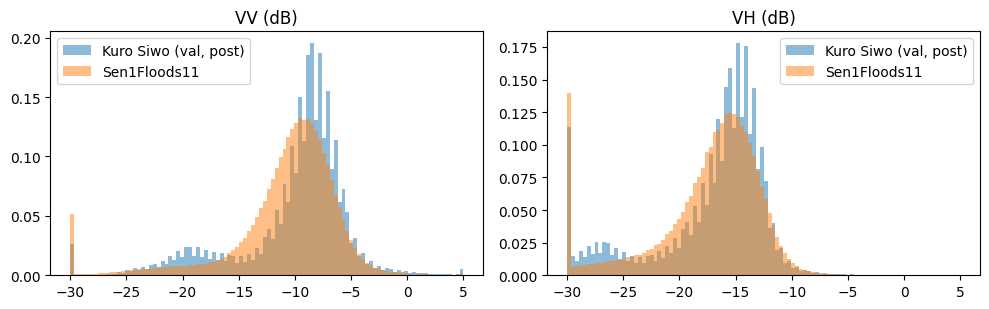

percentiles 1/25/50/75/99  VV  Kuro: [-26.7 -11.2  -8.9  -7.2  -0.5] | Sen1Floods11: [-30.  -12.2  -9.8  -7.9  -2.3]
percentiles 1/25/50/75/99  VH  Kuro: [-30.  -18.6 -15.7 -13.9  -9.4] | Sen1Floods11: [-30.  -19.2 -16.3 -14.2  -9.6]


In [44]:
# # ============================================================
# Sen1Floods11 (Bonafilia et al., CVPRW 2020): 446 hand-labelled 512x512 chips with Sentinel-1 GRD in dB (band 0 = VV, band 1 = VH),
# water labels (-1 no data, 0 not water, 1 water) and the JRC permanent-water layer; official splits train / valid / test / bolivia
# (Bolivia is a held-out REGION). There is ONE Sentinel-1 image per chip (no pre-event image), so only post-event models can be used here.
#
# Source order (first that works):  1. SEN_LOCAL_DIR, an attached Kaggle dataset (best if the internet is restricted)
#                                   2. public Google Cloud bucket sen1floods11 over HTTPS
#                                   3. Hugging Face mirror harshinde/sen1floods11 (third-party copy)
# The cell prints what it found. If all three fail, attach a Sen1Floods11 dataset to the notebook and set SEN_LOCAL_DIR.
# Output: data/sen1floods11/S_X.npy (n,2,512,512 float16 dB), S_Y.npy (int8 -1/0/1), S_P.npy (uint8 JRC permanent water), manifest.csv.
# ============================================================
import requests, glob, time as _time
from pathlib import Path
SEN = DATA / "sen1floods11"; SEN.mkdir(parents=True, exist_ok=True)
SEN_LOCAL_DIR = None                       # e.g. "/kaggle/input/sen1floods11"
GCS_BASE, GCS_API = "https://storage.googleapis.com/sen1floods11", "https://storage.googleapis.com/storage/v1/b/sen1floods11/o"
HF_MIRROR = "harshinde/sen1floods11"
KINDS = {"S1Hand": "_S1Hand.tif", "LabelHand": "_LabelHand.tif", "JRCWaterHand": "_JRCWaterHand.tif"}

def read_tif(path):
    try:
        import rasterio
        with rasterio.open(path) as ds: return ds.read()
    except ImportError:
        try: import tifffile
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tifffile"], check=False); import tifffile
        a = tifffile.imread(path)
        if a.ndim == 2: a = a[None]
        elif a.shape[-1] <= 4 < a.shape[0]: a = np.moveaxis(a, -1, 0)
        return a

def _http_get(url, dest, retries=3):
    for k in range(retries):
        try:
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for ch in r.iter_content(1 << 20): f.write(ch)
            return dest
        except Exception as e:
            if k == retries - 1: raise
            _time.sleep(2 * (k + 1))

def _chip(name):
    for suf in KINDS.values():
        if name.endswith(suf): return name[:-len(suf)]
    return None

def discover():
    """Returns (index, split_refs, fetch): index[kind][chip] -> ref, split_refs[split] -> ref, fetch(ref, dest_dir) -> local Path."""
    idx = {k: {} for k in KINDS}; spl = {}
    if SEN_LOCAL_DIR:
        root = Path(SEN_LOCAL_DIR)
        for k in KINDS:
            for p in root.rglob(f"{k}/*.tif"): idx[k][_chip(p.name)] = p
        for p in root.rglob("*.csv"):
            if "flood_handlabeled" in str(p) or "flood_" in p.name:
                for s in ("train", "valid", "test", "bolivia"):
                    if s in p.name.lower() and "flood" in p.name.lower(): spl[s] = p
        return idx, spl, (lambda ref, d: ref), f"local:{SEN_LOCAL_DIR}"
    try:                                                                              # 2. Google Cloud Storage, anonymous HTTPS
        def lst(prefix):
            out, tok = [], None
            while True:
                r = requests.get(GCS_API, params={"prefix": prefix, "maxResults": 1000, **({"pageToken": tok} if tok else {})}, timeout=60); r.raise_for_status()
                j = r.json(); out += [o["name"] for o in j.get("items", [])]; tok = j.get("nextPageToken")
                if not tok: return out
        base = "v1.1/data/flood_events/HandLabeled/"
        for k in KINDS:
            for n in lst(base + k + "/"):
                if n.endswith(".tif"): idx[k][_chip(Path(n).name)] = n
        for n in lst("v1.1/splits/flood_handlabeled/"):
            for s in ("train", "valid", "test", "bolivia"):
                if n.endswith(".csv") and s in Path(n).name.lower(): spl[s] = n
        if not idx["S1Hand"]: raise RuntimeError("bucket listing empty")
        return idx, spl, (lambda ref, d: _http_get(f"{GCS_BASE}/{ref}", Path(d) / Path(ref).name)), "gcs"
    except Exception as e:
        print("GCS not usable:", repr(e)[:150])
    from huggingface_hub import HfApi, hf_hub_download                                 # 3. Hugging Face mirror
    files = HfApi().list_repo_files(HF_MIRROR, repo_type="dataset")
    for f in files:
        for k in KINDS:
            if f"/{k}/" in f and f.endswith(".tif"): idx[k][_chip(Path(f).name)] = f
        if f.endswith(".csv") and "flood" in Path(f).name.lower():
            for s in ("train", "valid", "test", "bolivia"):
                if s in Path(f).name.lower(): spl[s] = f
    return idx, spl, (lambda ref, d: Path(hf_hub_download(HF_MIRROR, ref, repo_type="dataset", local_dir=str(d)))), "hf-mirror"

if not (SEN / "manifest.csv").exists():
    assert RUN_DOWNLOADS or SEN_LOCAL_DIR, 'Sen1Floods11 is not on disk: set RUN_DOWNLOADS = True (public bucket) or SEN_LOCAL_DIR (attached Kaggle dataset)'
    idx, spl, fetch, src = discover()
    print("source:", src, "| chips per layer:", {k: len(v) for k, v in idx.items()}, "| split files:", sorted(spl))
    assert idx["S1Hand"] and idx["LabelHand"], "Sen1Floods11 not found: attach a Kaggle dataset and set SEN_LOCAL_DIR, or check internet access"
    tmp = Path("/tmp/sen_tmp"); tmp.mkdir(exist_ok=True)
    chips_by_split = {}
    for s, ref in spl.items():
        p = fetch(ref, tmp); lines = [l.strip().split(",")[0] for l in Path(p).read_text().splitlines() if l.strip()]
        chips_by_split[s] = [c for c in (_chip(Path(l).name) for l in lines) if c]
    assert chips_by_split, "no split files found; set SEN_LOCAL_DIR to a folder that contains the split CSVs"
    rows = [(c, s) for s, cs in chips_by_split.items() for c in cs if c in idx["S1Hand"] and c in idx["LabelHand"]]
    n = len(rows); print("chips with split:", n, {s: sum(1 for _, t in rows if t == s) for s in chips_by_split})
    SX = np.lib.format.open_memmap(SEN / "S_X.npy", mode="w+", dtype=np.float16, shape=(n, 2, 512, 512))
    SY = np.lib.format.open_memmap(SEN / "S_Y.npy", mode="w+", dtype=np.int8, shape=(n, 512, 512))
    SP = np.lib.format.open_memmap(SEN / "S_P.npy", mode="w+", dtype=np.uint8, shape=(n, 512, 512))
    bad = 0
    for i, (c, s) in enumerate(rows):
        x = read_tif(fetch(idx["S1Hand"][c], tmp)).astype(np.float32); y = read_tif(fetch(idx["LabelHand"][c], tmp))[0]
        perm = read_tif(fetch(idx["JRCWaterHand"][c], tmp))[0] if c in idx["JRCWaterHand"] else np.zeros_like(y)
        if x.shape != (2, 512, 512) or y.shape != (512, 512): bad += 1; y = np.full((512, 512), -1); x = np.zeros((2, 512, 512), np.float32); perm = np.zeros((512, 512))
        nanm = ~np.isfinite(x).all(0); x = np.nan_to_num(x, nan=DB_MIN, posinf=DB_MAX, neginf=DB_MIN); y = y.astype(np.int8); y[nanm] = -1
        SX[i], SY[i], SP[i] = np.clip(x, DB_MIN, DB_MAX).astype(np.float16), y, (perm > 0).astype(np.uint8)
        for p in tmp.glob("**/*.tif"): p.unlink()
        if i % 50 == 0: print(f"  {i}/{n}", end="\r")
    for a in (SX, SY, SP): a.flush()
    pd.DataFrame({"chip": [c for c, _ in rows], "split": [s for _, s in rows], "region": [c.split("_")[0] for c, _ in rows]}).to_csv(SEN / "manifest.csv", index=False)
    print("done; chips with wrong shape (set to no-data):", bad)

SMAN = pd.read_csv(SEN / "manifest.csv"); SX = np.load(SEN / "S_X.npy", mmap_mode="r"); SY = np.load(SEN / "S_Y.npy", mmap_mode="r"); SP = np.load(SEN / "S_P.npy", mmap_mode="r")
valid_n = [(np.asarray(SY[i]) != -1).mean() for i in range(len(SMAN))]
eda = SMAN.assign(valid_frac=valid_n, water_frac=[float((np.asarray(SY[i]) == 1).sum() / max((np.asarray(SY[i]) != -1).sum(), 1)) for i in range(len(SMAN))],
                  perm_frac=[float(np.asarray(SP[i]).mean()) for i in range(len(SMAN))])
print("EDA per split:"); display(eda.groupby("split").agg(chips=("chip", "size"), regions=("region", "nunique"), water_frac=("water_frac", "mean"), perm_frac=("perm_frac", "mean"), valid_frac=("valid_frac", "mean")).round(3))
print("EDA per region:"); display(eda.groupby("region").agg(chips=("chip", "size"), water_frac=("water_frac", "mean"), perm_frac=("perm_frac", "mean")).round(3))
eda.to_csv(ROOT / "results" / "sen1floods11_eda.csv", index=False)

# --- radiometry: Sen1Floods11 post-event dB vs Kuro Siwo post-event dB (a cross-dataset shift check)
import matplotlib.pyplot as plt
Xk = np.load(PROC / "X_val.npy", mmap_mode="r"); ik = np.linspace(0, len(Xk) - 1, 300).astype(int)
kv = np.stack([np.asarray(Xk[i][[4, 5]]).astype(np.float32) * SCALE + DB_MIN for i in ik])                 # (300,2,H,W) post VV/VH
sv = np.stack([np.asarray(SX[i]).astype(np.float32) for i in np.linspace(0, len(SX) - 1, 100).astype(int)])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for c, nm in enumerate(["VV", "VH"]):
    ax[c].hist(kv[:, c].ravel(), 100, range=(DB_MIN, DB_MAX), density=True, alpha=.5, label="Kuro Siwo (val, post)"); ax[c].hist(sv[:, c].ravel(), 100, range=(DB_MIN, DB_MAX), density=True, alpha=.5, label="Sen1Floods11")
    ax[c].set_title(f"{nm} (dB)"); ax[c].legend()
plt.tight_layout(); plt.savefig(ROOT / "figures" / "radiometry_kuro_vs_sen.png", dpi=130); plt.show()
print("percentiles 1/25/50/75/99  VV  Kuro:", np.percentile(kv[:, 0], [1, 25, 50, 75, 99]).round(1), "| Sen1Floods11:", np.percentile(sv[:, 0], [1, 25, 50, 75, 99]).round(1))
print("percentiles 1/25/50/75/99  VH  Kuro:", np.percentile(kv[:, 1], [1, 25, 50, 75, 99]).round(1), "| Sen1Floods11:", np.percentile(sv[:, 1], [1, 25, 50, 75, 99]).round(1))
del kv, sv

## 11. Cross-dataset evaluation (Kuro Siwo ↔ Sen1Floods11), post-event-only U-Net, 3 seeds
Like-for-like score: predicted water vs. temporary flood, with permanent water ignored (`flood_noperm`). Models: Kuro-trained `abl_post2` (existing checkpoints) and new Sen1Floods11-trained U-Nets (`sen_post_s*.pt`). The Kuro Siwo test shards are used post hoc.

In [45]:
# # ============================================================
# Only what both datasets share can be compared: ONE post-event image (VV, VH) -> water mask. Same pre-processing (dB, clip [-30, 5], the SAME
# Kuro Siwo per-channel standardisation for both), same U-Net (2 input channels), same recipe family.
#   K->K  `abl_post2` (trained on Kuro Siwo flood, existing checkpoints)           tested on Kuro Siwo val / fresh test (post hoc)
#   K->S  the same checkpoints, zero-shot                                           tested on Sen1Floods11 test and the held-out region Bolivia
#   S->S  new U-Net trained on Sen1Floods11 train (water), early stopping on valid  tested on Sen1Floods11 test / Bolivia
#   S->K  the Sen1Floods11 models, zero-shot                                        tested on Kuro Siwo val / fresh test (post hoc)
# Label definitions differ: Sen1Floods11 "water" = flood + permanent water; Kuro Siwo "flood" = temporary flood only. Therefore two scores:
#   flood_noperm  predicted water vs flood, pixels of PERMANENT water (JRC layer / Kuro label 1) are ignored   <- the apples-to-apples comparison
#   water         Sen1Floods11 water vs prediction; for the Kuro-trained model the JRC permanent-water layer is added to its flood prediction;
#                 on Kuro Siwo water = label 1 or 2
# Sen1Floods11 chips are 512x512 and predicted with the tiling function of cell E4 (224 tiles, 32 px overlap, Hann blending).
# ============================================================
from torch.utils.data import Dataset, DataLoader
M2, S2 = MEAN[[4, 5]], STD[[4, 5]]                                           # Kuro Siwo post-event VV/VH statistics, used for BOTH datasets
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))

class SenCrops(Dataset):
    """Random 224x224 crops of the train chips (flips / 90-degree rotations); chips with no valid pixel in the crop are still returned (loss masks them)."""
    def __init__(self, split="train", n=1024, crop=224):
        self.ids = np.where(SMAN.split == split)[0]; self.n, self.crop = n, crop
    def __len__(self): return self.n
    def __getitem__(self, i):
        j = int(self.ids[random.randrange(len(self.ids))]); y0, x0 = random.randint(0, 512 - self.crop), random.randint(0, 512 - self.crop)
        x = (np.asarray(SX[j][:, y0:y0 + self.crop, x0:x0 + self.crop]).astype(np.float32) - M2) / S2
        lab = np.asarray(SY[j][y0:y0 + self.crop, x0:x0 + self.crop]); t, v = (lab == 1).astype(np.float32), lab != -1
        if random.random() < .5: x, t, v = x[:, :, ::-1], t[:, ::-1], v[:, ::-1]
        if random.random() < .5: x, t, v = x[:, ::-1], t[::-1], v[::-1]
        k = random.randint(0, 3)
        if k: x, t, v = np.rot90(x, k, (1, 2)), np.rot90(t, k), np.rot90(v, k)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(t)), torch.from_numpy(np.ascontiguousarray(v))

def sen_chip_input(i): return ((np.asarray(SX[i]).astype(np.float32) - M2) / S2).astype(np.float32)

def sen_counts(models, split, mode, region=None, threshold=0.5, k_model=False):
    """Pooled (tp, fp, fn) on Sen1Floods11 chips of a split. mode: 'water' or 'flood_noperm'."""
    ids = np.where((SMAN.split == split) & ((SMAN.region == region) if region else True))[0]; tp = fp = fn = 0
    for i in ids:
        pred = predict_scene(models, sen_chip_input(i), 224, 32) > threshold; lab = np.asarray(SY[i]); perm = np.asarray(SP[i]) > 0
        if mode == "water":
            if k_model: pred = pred | perm                                        # add JRC permanent water to a flood-only prediction
            tgt, val = lab == 1, lab != -1
        else:
            tgt, val = (lab == 1) & ~perm, (lab != -1) & ~perm
        tp += int((pred & tgt & val).sum()); fp += int((pred & ~tgt & val).sum()); fn += int((~pred & tgt & val).sum())
    return tp, fp, fn

def sen_train(seed, epochs=30, patience=8, lr=3e-4, wd=1e-4):
    run = f"sen_post_s{seed}"; ck = ROOT / "checkpoints" / f"{run}.pt"; res = ROOT / "results" / f"{run}.json"
    if res.exists(): print(run, "already done"); return
    assert RUN_TRAINING, f"{run}: no saved result; set RUN_TRAINING = True to train it"
    set_seed(seed); model = UNet(in_ch=2, base=32).to(DEVICE)
    dl = DataLoader(SenCrops("train"), batch_size=16, num_workers=2, shuffle=False); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs); scaler = torch.amp.GradScaler(enabled=USE_AMP); best, bad, hist = -1, 0, []
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for x, t, v in dl:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE); opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=USE_AMP): lg = model(x)
            loss = masked_bce_tversky(lg.float(), t, v, 0.5); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        sched.step(); model.eval()
        tp, fp, fn = sen_counts([model], "valid", "water"); iou = tp / max(tp + fp + fn, 1); hist.append({"epoch": ep, "loss": tot / len(dl), "val_IoU": iou})
        print(f"[{run}] ep {ep:02d} | loss {tot / len(dl):.4f} | valid IoU {iou:.4f}")
        if iou > best: best, bad = iou, 0; torch.save(model.state_dict(), ck)
        else:
            bad += 1
            if bad >= patience: print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False); res.write_text(json.dumps({"run": run, "best_valid_IoU": best, "epochs_run": len(hist)}))
    del model; gc.collect(); torch.cuda.empty_cache()

for s in (0, 1, 2): sen_train(s)

def load_unet2(path):
    m = UNet(in_ch=2, base=32); m.load_state_dict(torch.load(path, map_location=DEVICE)); return m.to(DEVICE).eval()
K_MODELS = [load_unet2(ROOT / "checkpoints" / f"abl_post2_s{s}.pt") for s in range(3)]
S_MODELS = [load_unet2(ROOT / "checkpoints" / f"sen_post_s{s}.pt") for s in range(3)]

@torch.no_grad()
def kuro_counts(models, split, mode):
    """Pooled counts on Kuro Siwo patches (post-event VV/VH only). mode: 'flood' (standard), 'flood_noperm', 'water'."""
    cfg = CFGS["abl_post2"]; loader = make_loader_v2(split, cfg); meta = loader.dataset.meta; Y = np.load(PROC / f"Y_{split}.npy", mmap_mode="r")
    keep = (~meta.actid.astype(int).isin(trainval_events).to_numpy()) if split.startswith("test") else np.ones(len(meta), bool)
    tp = fp = fn = 0; i0 = 0
    for x, _, _ in loader:
        n = len(x); lab = np.asarray(Y[i0:i0 + n]); k = keep[i0:i0 + n][:, None, None]; i0 += n
        with torch.autocast(DEVICE.type, enabled=USE_AMP): p = torch.stack([torch.sigmoid(m(x.to(DEVICE)).float()) for m in models]).mean(0)
        pred = (p > .5).cpu().numpy(); valid = (lab != IGNORE) & k
        if mode == "flood": tgt = lab == 2
        elif mode == "flood_noperm": tgt, valid = lab == 2, valid & (lab != 1)
        else: tgt = lab >= 1
        tp += int((pred & tgt & valid).sum()); fp += int((pred & ~tgt & valid).sum()); fn += int((~pred & tgt & valid).sum())
    return tp, fp, fn

iou_f = lambda c: metrics_from_counts(c[0], c[1], c[2], 0)
rows = []
def add(train, test, mode, models, fn):
    per = [fn([m]) for m in models]; ens = fn(models)
    ious = np.array([iou_f(c)["IoU"] for c in per]); f1 = np.array([iou_f(c)["F1"] for c in per])
    rows.append({"train": train, "test": test, "score": mode, "IoU": f"{ious.mean():.3f} +/- {ious.std(ddof=1):.3f}", "F1": f"{f1.mean():.3f}", "ensemble IoU": round(iou_f(ens)["IoU"], 3), "_iou": ious.mean()})
    print(rows[-1]["train"], "->", rows[-1]["test"], rows[-1]["score"], rows[-1]["IoU"])

for sp, nm in [("test", "Sen1Floods11 test"), ("bolivia", "Sen1Floods11 Bolivia (held-out region)")]:
    if (SMAN.split == sp).any():
        add("Sen1Floods11", nm, "flood_noperm", S_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "flood_noperm"))
        add("Sen1Floods11", nm, "water", S_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "water"))
        add("Kuro Siwo", nm, "flood_noperm", K_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "flood_noperm", k_model=True))
        add("Kuro Siwo", nm, "water (+JRC)", K_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "water", k_model=True))
for sp, nm in [("val", "Kuro Siwo validation"), ("test_01", "Kuro Siwo fresh test, shard 1 (post hoc)"), ("test_02", "Kuro Siwo fresh test, shard 2 (post hoc)")]:
    add("Kuro Siwo", nm, "flood_noperm", K_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "flood_noperm"))
    add("Kuro Siwo", nm, "flood (standard)", K_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "flood"))
    add("Sen1Floods11", nm, "flood_noperm", S_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "flood_noperm"))
    add("Sen1Floods11", nm, "water", S_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "water"))
CD = pd.DataFrame(rows).drop(columns="_iou"); CD.to_csv(ROOT / "results" / "cross_dataset_results.csv", index=False)
print("\nCROSS-DATASET RESULTS (post-event-only U-Net, 3 seeds, pooled IoU):"); display(CD)

# --- per-region IoU on Sen1Floods11 test chips (regions seen in training vs the held-out region)
reg_rows = []
for r in sorted(SMAN[SMAN.split.isin(["test", "bolivia"])].region.unique()):
    sp = SMAN[(SMAN.region == r) & SMAN.split.isin(["test", "bolivia"])].split.iloc[0]
    for nm, ms, kk in [("Sen1Floods11-trained", S_MODELS, False), ("Kuro-Siwo-trained", K_MODELS, True)]:
        c = sen_counts(ms, sp, "flood_noperm", region=r, k_model=kk); reg_rows.append({"region": r, "split": sp, "model": nm, "IoU": round(iou_f(c)["IoU"], 3)})
RG = pd.DataFrame(reg_rows).pivot_table(index=["region", "split"], columns="model", values="IoU"); RG.to_csv(ROOT / "results" / "cross_dataset_by_region.csv"); display(RG)
print("Reading guide: the diagonal (K->K, S->S) is in-domain, the off-diagonal is cross-dataset; the drop between them is the dataset shift. "
      "'flood_noperm' is the like-for-like score. Sen1Floods11 has no pre-event image, so the 1-pre + post and multi-temporal models cannot be tested here.")

sen_post_s0 already done
sen_post_s1 already done
sen_post_s2 already done
Sen1Floods11 -> Sen1Floods11 test flood_noperm 0.524 +/- 0.012
Sen1Floods11 -> Sen1Floods11 test water 0.661 +/- 0.011
Kuro Siwo -> Sen1Floods11 test flood_noperm 0.233 +/- 0.124
Kuro Siwo -> Sen1Floods11 test water (+JRC) 0.473 +/- 0.067
Sen1Floods11 -> Sen1Floods11 Bolivia (held-out region) flood_noperm 0.608 +/- 0.065
Sen1Floods11 -> Sen1Floods11 Bolivia (held-out region) water 0.625 +/- 0.062
Kuro Siwo -> Sen1Floods11 Bolivia (held-out region) flood_noperm 0.230 +/- 0.371
Kuro Siwo -> Sen1Floods11 Bolivia (held-out region) water (+JRC) 0.275 +/- 0.339
Kuro Siwo -> Kuro Siwo validation flood_noperm 0.656 +/- 0.016
Kuro Siwo -> Kuro Siwo validation flood (standard) 0.532 +/- 0.003
Sen1Floods11 -> Kuro Siwo validation flood_noperm 0.577 +/- 0.062
Sen1Floods11 -> Kuro Siwo validation water 0.611 +/- 0.056
Kuro Siwo -> Kuro Siwo fresh test, shard 1 (post hoc) flood_noperm 0.599 +/- 0.004
Kuro Siwo -> Kuro Siwo fr

,train,test,score,IoU,F1,ensemble IoU
0,Sen1Floods11,Sen1Floods11 test,flood_noperm,0.524 +/- 0.012,0.688,0.533
1,Sen1Floods11,Sen1Floods11 test,water,0.661 +/- 0.011,0.796,0.669
2,Kuro Siwo,Sen1Floods11 test,flood_noperm,0.233 +/- 0.124,0.367,0.263
3,Kuro Siwo,Sen1Floods11 test,water (+JRC),0.473 +/- 0.067,0.640,0.511
4,Sen1Floods11,Sen1Floods11 Bolivia (held-out region),flood_noperm,0.608 +/- 0.065,0.755,0.635
5,Sen1Floods11,Sen1Floods11 Bolivia (held-out region),water,0.625 +/- 0.062,0.768,0.649
6,Kuro Siwo,Sen1Floods11 Bolivia (held-out region),flood_noperm,0.230 +/- 0.371,0.285,0.073
7,Kuro Siwo,Sen1Floods11 Bolivia (held-out region),water (+JRC),0.275 +/- 0.339,0.364,0.131
8,Kuro Siwo,Kuro Siwo validation,flood_noperm,0.656 +/- 0.016,0.792,0.661
9,Kuro Siwo,Kuro Siwo validation,flood (standard),0.532 +/- 0.003,0.695,0.537


,model,Kuro-Siwo-trained,Sen1Floods11-trained
region,split,,
Bolivia,bolivia,0.073,0.635
Ghana,test,0.086,0.353
India,test,0.117,0.605
Mekong,test,0.699,0.841
Nigeria,test,0.867,0.861
Pakistan,test,0.084,0.190
Paraguay,test,0.002,0.416
Somalia,test,0.154,0.456
Spain,test,0.379,0.637


Reading guide: the diagonal (K->K, S->S) is in-domain, the off-diagonal is cross-dataset; the drop between them is the dataset shift. 'flood_noperm' is the like-for-like score. Sen1Floods11 has no pre-event image, so the 1-pre + post and multi-temporal models cannot be tested here.


## 12. Explainability: qualitative maps, Grad-CAM, exact Shapley values over input channels, gate maps
Plain U-Net (`base`) and proposed `mt_g2`, ensembles of three seeds, 1,200 sampled patches each for validation and the first test shard. Shapley values replace an absent channel by the training mean, so they describe dependence, not causal importance.

selected patches (event, split, row): [(417, 'test_01', 4862), (277, 'test_01', 646), (279, 'test_01', 897), (427, 'test_01', 5079)]


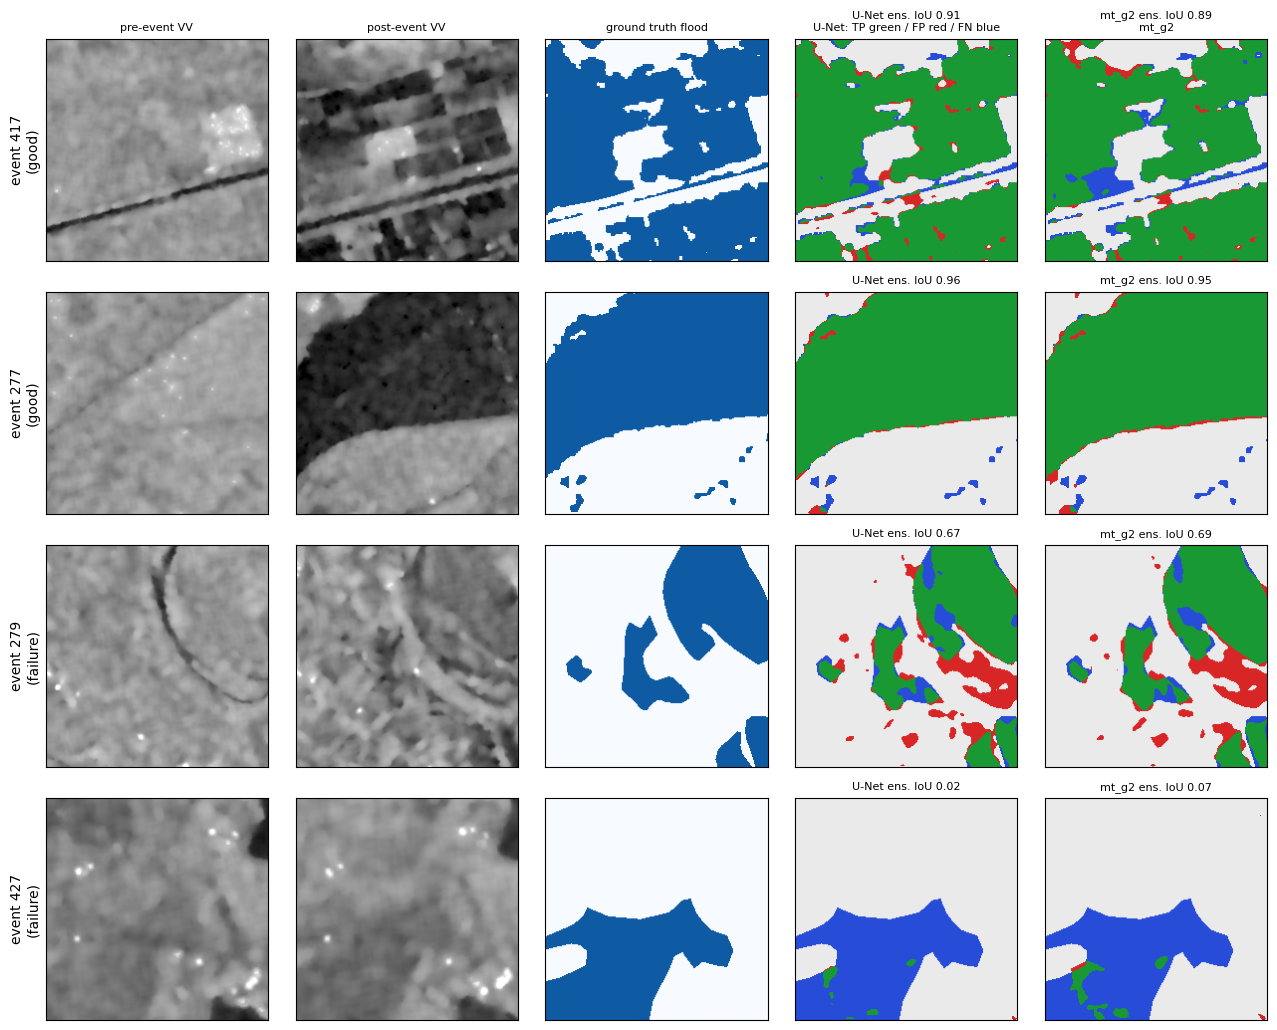

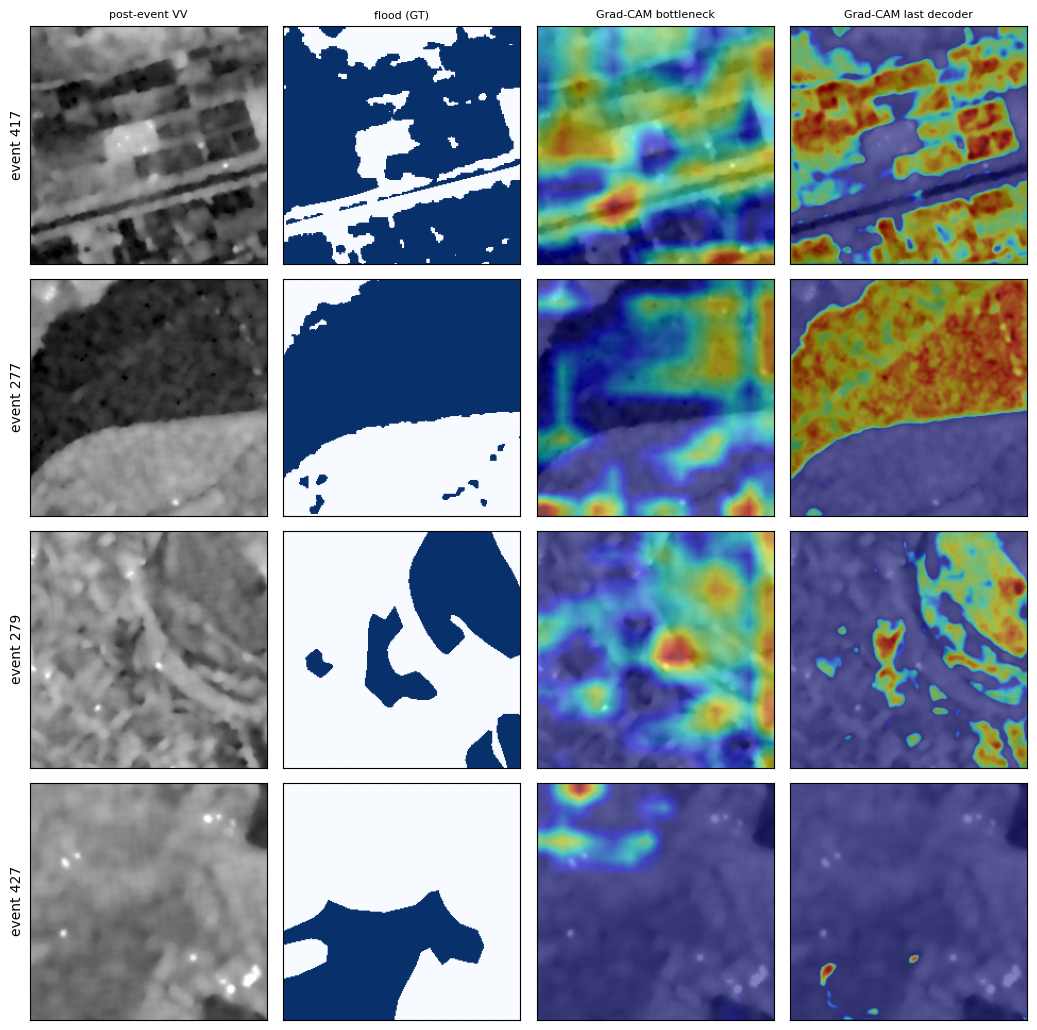

gradient x input, share per input channel and patch:


,pre VV,pre VH,post VV,post VH
event,,,,
417,0.108,0.126,0.318,0.447
277,0.079,0.103,0.383,0.435
279,0.106,0.151,0.314,0.429
427,0.162,0.111,0.510,0.217


,model,split,player,Shapley (IoU),permutation drop (IoU),IoU all
0,U-Net (pre1 + post),val,pre VV,0.0530,0.1085,0.6849
1,U-Net (pre1 + post),val,pre VH,0.0734,0.0994,0.6849
2,U-Net (pre1 + post),val,post VV,0.4691,0.5440,0.6849
3,U-Net (pre1 + post),val,post VH,0.0893,0.2327,0.6849
4,mt_g2,val,pre-event 1,0.0560,NaN,0.6738
5,mt_g2,val,pre-event 2,0.0457,NaN,0.6738
6,mt_g2,val,post-event,0.5722,NaN,0.6738
7,U-Net (pre1 + post),test_01,pre VV,0.0555,0.1050,0.5906
8,U-Net (pre1 + post),test_01,pre VH,0.0442,0.0663,0.5906
9,U-Net (pre1 + post),test_01,post VV,0.4547,0.5122,0.5906


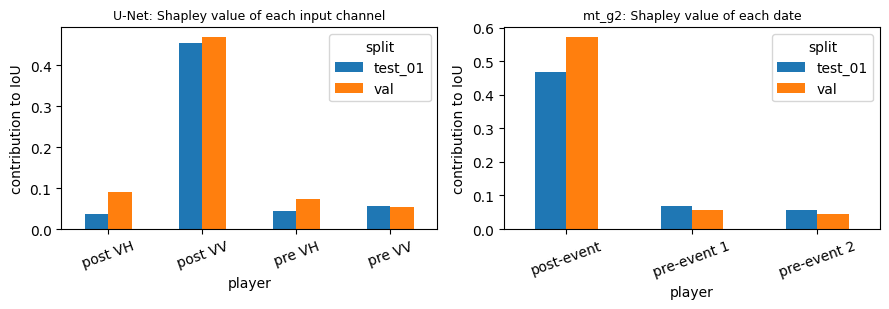

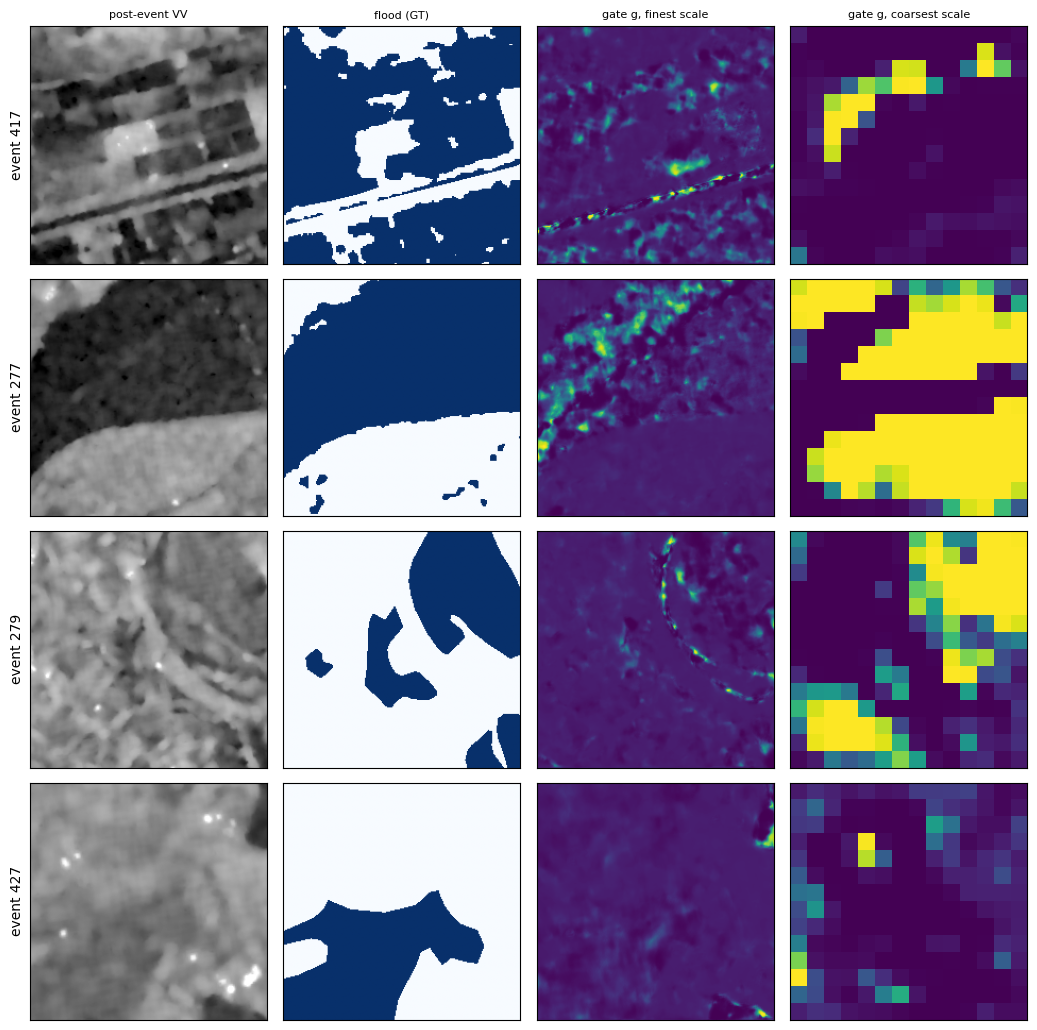

mean gate g (0 = only pre1) inside / outside flood:


,gate finest (mean),gate finest in flood,gate finest outside flood,gate coarsest in flood,gate coarsest outside flood
event,,,,,
417,0.110,0.116,0.094,0.134,0.000
277,0.118,0.144,0.079,0.462,0.809
279,0.087,0.088,0.087,0.583,0.256
427,0.081,0.081,0.080,0.049,0.059


Done. Send me: the printed tables of B1, D1, D2, X1 and the files in results/ (sota_baselines_*.csv, sen1floods11_eda.csv, cross_dataset_*.csv, input_importance.csv, gate_maps_stats.csv, gradient_x_input_share.csv); and look at figures/qualitative_maps.png, gradcam_examples.png, channel_importance.png, gate_maps.png.


In [46]:
# # ============================================================
# (a) qualitative prediction maps for good and failure events (frozen models, ensembles; fresh-test patches; descriptive)
# (b) Grad-CAM of the plain U-Net (seed 0), bottleneck and last decoder block, target = flood evidence over ground-truth flood pixels
# (c) which input channel matters: exact Shapley values over the 4 input channels (16 coalitions, absent channel = training mean) and
#     permutation importance, for the plain U-Net ensemble; date-level Shapley (pre1 / pre2 / post) for mt_g2  - on random samples of
#     validation and fresh-test patches (pixel-level IoU, no minimum-area rule)
# (d) spatial gate maps of mt_g2: where does the model use the older pre-event image?
# Outputs: figures/qualitative_maps.png, gradcam_examples.png, channel_importance.png, gate_maps.png and results/*.csv.
# ============================================================
import matplotlib.pyplot as plt, copy
_orig_gate_forward = GatedFusion.forward               # restored at the end of this cell
GOOD, FAIL = [417, 277], [279, 427]
BASEC, MTC = CFGS["base"], CFGS["mt_g2"]
base_models = load_group("base")[0][2]; mt_models = load_group("mt_g2")[0][2]
mk_ds = lambda cfg, split: (FloodDatasetMT if cfg.get("gap") else FloodDatasetV2)(split, cfg)

def find_patch(event, q=0.9):
    for sp in ("test_01", "test_02"):
        m = pd.read_csv(PROC / f"manifest_{sp}.csv", dtype={"sample_id": str, "shard": str}); m = m[m.split == sp].sort_values("row").reset_index(drop=True)
        sub = m[(m.actid.astype(int) == event) & (m.pflood > 0)]
        if len(sub): return sp, int(sub.sort_values("pflood").iloc[int(q * (len(sub) - 1))].name)          # patch with a visible, typical flood
    return None
sel = [(e, *find_patch(e)) for e in GOOD + FAIL if find_patch(e)]
print("selected patches (event, split, row):", sel)

@torch.no_grad()
def ens_prob(models, x): return torch.stack([torch.sigmoid(m(x.to(DEVICE)).float()) for m in models]).mean(0).cpu().numpy()

# ---- (a) qualitative maps
fig, ax = plt.subplots(len(sel), 5, figsize=(13, 2.6 * len(sel)))
ax = np.atleast_2d(ax)
for r, (e, sp, i) in enumerate(sel):
    dsb, dsm = mk_ds(BASEC, sp), mk_ds(MTC, sp); xb, t, v = dsb[i]; xm = dsm[i][0]
    Xr = np.load(PROC / f"X_{sp}.npy", mmap_mode="r"); raw = _db(Xr, i, [0, 4]); t, v = t.numpy() > 0, v.numpy()
    pb, pm = ens_prob(base_models, xb[None])[0] > .5, ens_prob(mt_models, xm[None])[0] > .5
    def overlay(p):
        im = np.ones(p.shape + (3,)) * 0.92; im[p & t & v] = (0.1, 0.6, 0.2); im[p & ~t & v] = (0.85, 0.15, 0.15); im[~p & t & v] = (0.15, 0.3, 0.85); im[~v] = (0.6, 0.6, 0.6); return im
    iou = lambda p: (p & t & v).sum() / max((p & v).sum() + (t & v).sum() - (p & t & v).sum(), 1)
    ax[r, 0].imshow(raw[0], cmap="gray", vmin=-25, vmax=0); ax[r, 1].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 2].imshow(np.where(v, t, .5), cmap="Blues", vmin=0, vmax=1.2)
    ax[r, 3].imshow(overlay(pb)); ax[r, 4].imshow(overlay(pm))
    ax[r, 0].set_ylabel(f"event {e}\n({'good' if e in GOOD else 'failure'})")
    ax[r, 3].set_title(f"U-Net ens. IoU {iou(pb):.2f}", fontsize=8); ax[r, 4].set_title(f"mt_g2 ens. IoU {iou(pm):.2f}", fontsize=8)
for a, t_ in zip(ax[0], ["pre-event VV", "post-event VV", "ground truth flood", "U-Net: TP green / FP red / FN blue", "mt_g2"]): a.set_title(t_ if a is not ax[0, 3] and a is not ax[0, 4] else a.get_title() + "\n" + t_, fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(ROOT / "figures" / "qualitative_maps.png", dpi=130); plt.show()

# ---- (b) Grad-CAM (plain U-Net seed 0)
class GradCAM:
    def __init__(self, model, layer):
        self.m, self.act = model, None
        def hook(mod, i, o):
            self.act = o
            if o.requires_grad: o.retain_grad()
        layer.register_forward_hook(hook)                                              # hook returns None: output unchanged
    def __call__(self, x, score_mask):
        self.m.zero_grad(); xin = x[None].clone().to(DEVICE).float().requires_grad_(True); lg = self.m(xin)[0]
        s = (lg * score_mask.to(DEVICE)).sum() / score_mask.sum().clamp(min=1); s.backward()
        w = self.act.grad.mean((2, 3), keepdim=True); cam = F.relu((w * self.act).sum(1))[0].detach().cpu()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].numpy()
        return cam / (cam.max() + 1e-8), xin.grad[0].detach().cpu().numpy()
m0 = copy.deepcopy(base_models[0]).float().eval()
for p_ in m0.parameters(): p_.requires_grad_(True)
gc_b, gc_d = GradCAM(m0, m0.enc[4]), GradCAM(m0, m0.dec[0])
fig, ax = plt.subplots(len(sel), 4, figsize=(10.5, 2.6 * len(sel))); ax = np.atleast_2d(ax); sal_rows = []
for r, (e, sp, i) in enumerate(sel):
    x, t, v = mk_ds(BASEC, sp)[i]; mask = (t > 0) & v
    if mask.sum() == 0: continue
    Xr = np.load(PROC / f"X_{sp}.npy", mmap_mode="r"); raw = _db(Xr, i, [0, 4])
    cam_b, g = gc_b(x, mask.float()); cam_d, _ = gc_d(x, mask.float())
    ax[r, 0].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 1].imshow(mask, cmap="Blues"); ax[r, 2].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 2].imshow(cam_b, cmap="jet", alpha=.5)
    ax[r, 3].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 3].imshow(cam_d, cmap="jet", alpha=.5); ax[r, 0].set_ylabel(f"event {e}")
    sal_rows.append({"event": e, **{n: float((np.abs(g[c]) * np.abs(x[c].numpy())).mean()) for c, n in enumerate(["pre VV", "pre VH", "post VV", "post VH"])}})   # gradient x input
for a, t_ in zip(ax[0], ["post-event VV", "flood (GT)", "Grad-CAM bottleneck", "Grad-CAM last decoder"]): a.set_title(t_, fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(ROOT / "figures" / "gradcam_examples.png", dpi=130); plt.show()
SAL = pd.DataFrame(sal_rows).set_index("event"); SAL = SAL.div(SAL.sum(1), axis=0); print("gradient x input, share per input channel and patch:"); display(SAL.round(3)); SAL.to_csv(ROOT / "results" / "gradient_x_input_share.csv")
del m0, gc_b, gc_d; gc.collect(); torch.cuda.empty_cache()

# ---- (c) exact Shapley values and permutation importance of the inputs
def sample_tensors(cfg, split, n=1200, seed=0):
    ds = mk_ds(cfg, split); keep = np.where(~ds.meta.actid.astype(int).isin(trainval_events))[0] if split.startswith("test") else np.arange(len(ds))
    ids = np.sort(np.random.default_rng(seed).choice(keep, min(n, len(keep)), replace=False)); X, T, V = [], [], []
    for i in ids: x, t, v = ds[int(i)]; X.append(x.half()); T.append(t.bool()); V.append(v.bool())
    return torch.stack(X), torch.stack(T), torch.stack(V)

@torch.no_grad()
def value(models, X, T, V, absent=(), shuffle=(), bs=32):
    tp = fp = fn = 0
    for a in range(0, len(X), bs):
        x = X[a:a + bs].float().clone()
        for c in absent: x[:, c] = 0.0                                                # standardised 0 = training-mean backscatter
        for c in shuffle: x[:, c] = x[:, c][torch.randperm(len(x), generator=torch.Generator().manual_seed(a))]
        p = ens_prob(models, x) > .5; t, v = T[a:a + bs].numpy(), V[a:a + bs].numpy()
        tp += int((p & t & v).sum()); fp += int((p & ~t & v).sum()); fn += int((~p & t & v).sum())
    return tp / max(tp + fp + fn, 1)

from itertools import combinations
from math import factorial
def shapley(models, X, T, V, groups):
    n = len(groups); v = {}
    for k in range(n + 1):
        for S in combinations(range(n), k):
            v[S] = value(models, X, T, V, absent=[c for j in range(n) if j not in S for c in groups[j]])
    phi = []
    for i in range(n):
        s = 0.0
        for k in range(n):
            for S in combinations([j for j in range(n) if j != i], k):
                s += factorial(k) * factorial(n - k - 1) / factorial(n) * (v[tuple(sorted(S + (i,)))] - v[S])
        phi.append(s)
    return phi, v[tuple(range(n))], v[()]

imp_rows = []
for split in ("val", "test"):
    sp = "val" if split == "val" else "test_01"
    Xb, Tb, Vb = sample_tensors(BASEC, sp); names = ["pre VV", "pre VH", "post VV", "post VH"]
    phi, full, empty = shapley(base_models, Xb, Tb, Vb, [[0], [1], [2], [3]])
    perm = [full - value(base_models, Xb, Tb, Vb, shuffle=[c]) for c in range(4)]
    for n_, p_, q_ in zip(names, phi, perm): imp_rows.append({"model": "U-Net (pre1 + post)", "split": sp, "player": n_, "Shapley (IoU)": p_, "permutation drop (IoU)": q_, "IoU all": full})
    del Xb, Tb, Vb
    Xm, Tm, Vm = sample_tensors(MTC, sp)
    phi, full, empty = shapley(mt_models, Xm, Tm, Vm, [[0, 1], [2, 3], [4, 5]])
    for n_, p_ in zip(["pre-event 1", "pre-event 2", "post-event"], phi): imp_rows.append({"model": "mt_g2", "split": sp, "player": n_, "Shapley (IoU)": p_, "permutation drop (IoU)": np.nan, "IoU all": full})
    del Xm, Tm, Vm; gc.collect(); torch.cuda.empty_cache()
IMP = pd.DataFrame(imp_rows); IMP.to_csv(ROOT / "results" / "input_importance.csv", index=False); display(IMP.round(4))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, (mdl, ttl) in zip(ax, [("U-Net (pre1 + post)", "U-Net: Shapley value of each input channel"), ("mt_g2", "mt_g2: Shapley value of each date")]):
    d = IMP[IMP.model == mdl].pivot(index="player", columns="split", values="Shapley (IoU)"); d.plot.bar(ax=a, rot=20); a.set_title(ttl, fontsize=9); a.set_ylabel("contribution to IoU")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "channel_importance.png", dpi=130); plt.show()

# ---- (d) gate maps of mt_g2
def _fwd_with_map(self, f, gap=None, drop=None):
    pre1, pre2, post = f[:, 0], f[:, 1], f[:, 2]
    q = self.q(post); sc = math.sqrt(q.shape[1])
    s1, s2 = (self.k(pre1) * q).sum(1, keepdim=True) / sc, (self.k(pre2) * q).sum(1, keepdim=True) / sc
    l = self.bias + (s2 - s1)
    if self.gap is not None: l = l + self.gap(gap.to(l.dtype))[:, :, None, None]
    if drop is not None:
        l = torch.where((drop == 2)[:, None, None, None], torch.full_like(l, -20.0), l); l = torch.where((drop == 1)[:, None, None, None], torch.full_like(l, 20.0), l)
    g = torch.sigmoid(l); self.last_g = g.mean((1, 2, 3)).detach().float(); self.last_gmap = g.detach().float()
    ref = pre1 + g * (pre2 - pre1); return self.mix(torch.cat([post, post - ref, ref], 1))
GatedFusion.forward = _fwd_with_map                           # temporary patch to expose the gate map
gm = copy.deepcopy(mt_models[0]).eval(); fig, ax = plt.subplots(len(sel), 4, figsize=(10.5, 2.6 * len(sel))); ax = np.atleast_2d(ax); grows = []
for r, (e, sp, i) in enumerate(sel):
    x, t, v = mk_ds(MTC, sp)[i]
    with torch.no_grad(): gm(x[None].to(DEVICE))
    Xr = np.load(PROC / f"X_{sp}.npy", mmap_mode="r"); raw = _db(Xr, i, [0, 4]); t = t.numpy() > 0
    g0, g4 = gm.fuse[0].last_gmap[0, 0].cpu().numpy(), gm.fuse[4].last_gmap[0, 0].cpu().numpy()
    ax[r, 0].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 1].imshow(t, cmap="Blues"); im = ax[r, 2].imshow(g0, cmap="viridis", vmin=0, vmax=max(g0.max(), .2)); ax[r, 3].imshow(g4, cmap="viridis", vmin=0, vmax=max(g4.max(), .2))
    t4 = F.adaptive_avg_pool2d(torch.tensor(t[None, None].astype(np.float32)), g4.shape).numpy()[0, 0] > .5
    grows.append({"event": e, "gate finest (mean)": g0.mean(), "gate finest in flood": g0[t].mean() if t.any() else np.nan, "gate finest outside flood": g0[~t].mean(),
                  "gate coarsest in flood": g4[t4].mean() if t4.any() else np.nan, "gate coarsest outside flood": g4[~t4].mean()})
    ax[r, 0].set_ylabel(f"event {e}")
for a, t_ in zip(ax[0], ["post-event VV", "flood (GT)", "gate g, finest scale", "gate g, coarsest scale"]): a.set_title(t_, fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(ROOT / "figures" / "gate_maps.png", dpi=130); plt.show()
GT_ = pd.DataFrame(grows).set_index("event"); print("mean gate g (0 = only pre1) inside / outside flood:"); display(GT_.round(3)); GT_.to_csv(ROOT / "results" / "gate_maps_stats.csv")
print("Done. Send me: the printed tables of B1, D1, D2, X1 and the files in results/ (sota_baselines_*.csv, sen1floods11_eda.csv, cross_dataset_*.csv, input_importance.csv, gate_maps_stats.csv, gradient_x_input_share.csv); "
      "and look at figures/qualitative_maps.png, gradcam_examples.png, channel_importance.png, gate_maps.png.")
GatedFusion.forward = _orig_gate_forward                       # undo the patch

## 13. Results summary (reads the saved CSV files; these are the numbers in the paper)

In [47]:
def ms(x): return f"{x.mean():.3f} +/- {(x.std(ddof=1) if len(x) > 1 else 0):.3f}"
print("A. Validation, single models (3 seeds) and ensembles; 500 px rule")
V = pd.read_csv(RESULTS / "sota_baselines_val.csv"); display(V[V.kind.str.startswith("s")].groupby("model")[["IoU", "F1", "precision", "recall"]].agg(ms))
display(V[V.kind == "ens"].set_index("model")[["IoU", "F1"]].round(3))
print("B. Frozen fresh test (10 unseen events): single / ensemble IoU")
R = pd.read_csv(RESULTS / "fresh_test_final.csv"); display(pd.concat([R[R.kind == "single"].groupby("model")["IoU"].agg(ms).rename("single"), R[R.kind.str.startswith("ens")].set_index("model")["IoU"].round(3).rename("ensemble")], axis=1))
print("C. Recent baselines on the fresh test (post hoc, exploratory)")
T = pd.read_csv(RESULTS / "sota_baselines_test_posthoc.csv"); display(pd.concat([T[T.kind.str.startswith("s")].groupby("model")["IoU"].agg(ms).rename("single"), T[T.kind == "ens"].set_index("model")["IoU"].round(3).rename("ensemble")], axis=1))
print("D. Cross-dataset (post-event-only U-Net)"); display(pd.read_csv(RESULTS / "cross_dataset_results.csv"))
print("E. Per region on Sen1Floods11"); display(pd.read_csv(RESULTS / "cross_dataset_by_region.csv"))
print("F. Input importance (Shapley)"); display(pd.read_csv(RESULTS / "input_importance.csv").round(3))

A. Validation, single models (3 seeds) and ensembles; 500 px rule


,IoU,F1,precision,recall
model,,,,
base,0.684 +/- 0.008,0.812 +/- 0.006,0.819 +/- 0.010,0.806 +/- 0.002
mt_g2,0.669 +/- 0.004,0.801 +/- 0.003,0.791 +/- 0.006,0.812 +/- 0.013
segformer_b2,0.696 +/- 0.003,0.821 +/- 0.002,0.837 +/- 0.015,0.806 +/- 0.014
unet_r50,0.693 +/- 0.007,0.819 +/- 0.005,0.829 +/- 0.015,0.809 +/- 0.019


,IoU,F1
model,,
base,0.691,0.817
mt_g2,0.677,0.808
unet_r50,0.703,0.826
segformer_b2,0.700,0.823


B. Frozen fresh test (10 unseen events): single / ensemble IoU


,single,ensemble
model,,
base,0.586 +/- 0.019,0.599
mt_g2,0.587 +/- 0.016,0.597


C. Recent baselines on the fresh test (post hoc, exploratory)


... (3 outputs left out)

E. Per region on Sen1Floods11


,region,split,Kuro-Siwo-trained,Sen1Floods11-trained
0,Bolivia,bolivia,0.073,0.635
1,Ghana,test,0.086,0.353
2,India,test,0.117,0.605
3,Mekong,test,0.699,0.841
4,Nigeria,test,0.867,0.861
5,Pakistan,test,0.084,0.190
6,Paraguay,test,0.002,0.416
7,Somalia,test,0.154,0.456
8,Spain,test,0.379,0.637
9,Sri-Lanka,test,0.000,0.207


F. Input importance (Shapley)


,model,split,player,Shapley (IoU),permutation drop (IoU),IoU all
0,U-Net (pre1 + post),val,pre VV,0.053,0.109,0.685
1,U-Net (pre1 + post),val,pre VH,0.073,0.099,0.685
2,U-Net (pre1 + post),val,post VV,0.469,0.544,0.685
3,U-Net (pre1 + post),val,post VH,0.089,0.233,0.685
4,mt_g2,val,pre-event 1,0.056,NaN,0.674
5,mt_g2,val,pre-event 2,0.046,NaN,0.674
6,mt_g2,val,post-event,0.572,NaN,0.674
7,U-Net (pre1 + post),test_01,pre VV,0.055,0.105,0.591
8,U-Net (pre1 + post),test_01,pre VH,0.044,0.066,0.591
9,U-Net (pre1 + post),test_01,post VV,0.455,0.512,0.591


## 14. Backup (optional) and what was removed from the original notebook
Set `RUN_BACKUP = True` to zip checkpoints, results, logs and small data files for download.

In [48]:
if RUN_BACKUP:
    import zipfile, hashlib
    OUT = Path("/kaggle/working/backup_improvement_round.zip")
    ALL_CKPT = True            # True: all checkpoints (original + v2); False: only the v2_* ones
    files = []
    for pat in (["*.pt"] if ALL_CKPT else ["v2_*.pt"]):
        files += sorted((ROOT / "checkpoints").glob(pat))
    files += sorted((ROOT / "results").glob("*")) + sorted((ROOT / "logs").glob("*"))
    files += [PROC / n for n in ["diff_stats.json", "hard_neg_weights.npy", "norm_stats.json", "done.json",
                                 "manifest_trainval.csv", "manifest_train_extra.csv", "manifest_test_00.csv",
                                 "manifest_test_01.csv", "manifest_test_02.csv", "manifest_test_02_eligible.csv"]]
    files += sorted(DATA.glob("*.csv"))
    files = [f for f in files if f.is_file()]
    listing = []
    with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
        for f in files:
            z.write(f, arcname=str(f.relative_to(ROOT)))
            listing.append({"file": str(f.relative_to(ROOT)), "MB": round(f.stat().st_size / 1e6, 2)})
    pd.DataFrame(listing).to_csv(ROOT / "results" / "backup_listing.csv", index=False)
    print(f"{len(files)} files -> {OUT} ({OUT.stat().st_size / 1e9:.2f} GB)")
    print("v2 checkpoints:", sorted(p.name for p in (ROOT / "checkpoints").glob("v2_*.pt")))
    display(pd.DataFrame(listing).sort_values("MB", ascending=False).head(12))
else:
    print('skipped: switch is off or output already exists')

skipped: switch is off or output already exists
